<a href="https://colab.research.google.com/github/eliasbelme/eliasbelme.github.io/blob/main/TP_GP27_FBNV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP GP27 — Feature-Based Newsvendor (FBNV) appliqué au *Bike Sharing Demand*

### Reproduction et extension de Jing Shi (2022), *Application of the model combining demand forecasting and inventory decision in feature based newsvendor problem*, Computers & Industrial Engineering, 173, 108709

| | |
|---|---|
| **Module** | GP27 — Gestion de production et des stocks, cycle ingénieur Génie Industriel, UTT |
| **Encadrant** | M. Ahmed Khemili |
| **Auteur** | Elias Belmeliani |
| **Paradigme** | *Predict-to-Optimize* : prévision de la demande et décision de stock intégrées en une seule étape |
| **Données** | Kaggle *Bike Sharing Demand*, fichier `train.csv` : 10 886 observations horaires (Capital Bikeshare, Washington D.C., 2011-2012) |
| **Transposition** | Les données de l'article (ventes BMW à Hefei, Baidu Index) sont confidentielles ; la transposition sur un jeu de données public a été validée par le chargé de TP |

---

## Problématique

Un opérateur de vélos en libre-service doit décider, **avant** d'observer la demande, combien de vélos $q$ positionner en station pour chaque heure. Deux erreurs coûtent de l'argent, et elles ne coûtent pas la même chose :

* **Rupture** ($D > q$) : location perdue, client insatisfait. Coût unitaire $b = 10$.
* **Sur-stockage** ($q > D$) : vélo immobilisé, rééquilibrage inutile. Coût unitaire $h = 4$.

C'est le problème du **vendeur de journaux** (*newsvendor*). L'article de Jing Shi montre qu'il vaut mieux apprendre **directement** la décision $q(\mathbf{x})$ à partir des variables contextuelles $\mathbf{x}$ (météo, calendrier, heure) plutôt que de prévoir la moyenne puis d'ajouter un stock de sécurité. Ce notebook reproduit cette démonstration de bout en bout.

## Sommaire du pipeline (5 étapes)

| Étape | Contenu | Correspondance avec l'article |
|---|---|---|
| **1. Chargement, audit d'intégrité et EDA** | 16 micro-étapes : chargement, structure, qualité, modalités, fuite de données, extraction temporelle, 4 visualisations | §4.1 « data viewing stage » |
| **2. Data engineering, multicolinéarité et Lasso** | Pearson, VIF, standardisation sans fuite, sélection L1, robustesse | §4.2 « Selection of variables » |
| **3. Protocole train/test et validation croisée** | Split 87,5 % / 12,5 %, benchmark de 9 modèles, 5-Fold CV, diagnostic des résidus | §4.3 et §5.3 |
| **4. Optimisation des stocks : Direct, Two-Step et One-Step FBNV** | Convergence, GridSearchCV, newsvendor et perte Pinball, régression quantile, sensibilité $b/(b+h)$ | §3.2, §4.1 et §5.4, équations (1)-(2) |
| **5. Évaluation finale et livrables** | Tableaux 8 et 9, importance MDI et permutation, réel vs prédit, courbes $q^*$, export Excel | §5.3-§5.4, Tableaux 8-9, Fig. 6-9 |

> **Temps d'exécution.** Environ 10 minutes sur 4 cœurs (davantage sur Colab gratuit) : les recherches sur grille et l'analyse de sensibilité ré-entraînent plusieurs dizaines de modèles.
>
> **Convention de lecture.** Chaque cellule de code est précédée d'une cellule **Pourquoi** (justification mathématique et métier) et suivie d'une cellule **Finding** (constats chiffrés, issus de l'exécution) et **Insights** (interprétation Supply Chain et lien avec l'article).

---
# ÉTAPE 1 — Chargement, audit d'intégrité et analyse exploratoire (EDA)

L'article décrit une phase de *data viewing* (§4.1) : lecture des premières lignes, statistiques descriptives et vérification de l'absence de valeurs manquantes. Nous la portons à un niveau industriel en 16 micro-étapes. Un modèle de décision de stock ne vaut que ce que valent ses données : une erreur d'encodage ou une fuite d'information à ce stade fausserait silencieusement toute la chaîne *Predict-to-Optimize*.

| # | Micro-étape | Question d'audit |
|---|---|---|
| 1.0 | Configuration de l'environnement | Le notebook est-il reproductible ? |
| 1.1 | Chargement et traçabilité | Travaille-t-on sur le bon fichier ? |
| 1.2 | Aperçu `head()` / `tail()` | À quoi ressemblent les données brutes ? |
| 1.3 | Audit structurel et typage mémoire | Les types sont-ils cohérents et économes ? |
| 1.4 | Continuité de l'index temporel | La série horaire est-elle complète ? |
| 1.5 | Statistiques descriptives | Quelle est la forme de la demande ? |
| 1.6 | Valeurs manquantes | Faut-il imputer ? |
| 1.7 | Doublons | Une heure est-elle comptée deux fois ? |
| 1.8 | Propreté des modalités | Existe-t-il des codes parasites ? |
| 1.9 | Plausibilité physique | Les mesures météo sont-elles crédibles ? |
| 1.10 | Fuite de données | Une variable connaît-elle la réponse ? |
| 1.11 | Extraction temporelle et renommage | Le calendrier est-il exploitable par les modèles ? |
| 1.12 | Visualisation 1 : distribution de `cnt` | La demande est-elle gaussienne ? |
| 1.13 | Visualisation 2 : boxplots | Où sont les extrêmes et la saisonnalité ? |
| 1.14 | Visualisation 3 : profil horaire | Comment l'heure et le type de jour interagissent-ils ? |
| 1.15 | Visualisation 4 : effet thermique | La température pilote-t-elle la demande ? |
| 1.16 | Synthèse de l'audit | Les données sont-elles prêtes pour l'Étape 2 ? |

## 1.0 Configuration de l'environnement

**Pourquoi ?** Un résultat scientifique doit être reproductible à l'identique. Nous fixons la graine aléatoire (`RANDOM_STATE = 42`, celle de tout le TP), importons les bibliothèques une seule fois et définissons une charte graphique unique (palette, typographie, grille discrète) pour que toutes les figures aient une qualité de publication et puissent être reprises telles quelles dans le rapport. Deux fonctions utilitaires sont définies : `afficher_tableau()` pour des tableaux mis en forme et `sauver_figure()` pour exporter chaque graphique en PNG haute définition dans `figures/`.

In [1]:
# ============================================================================
# 1.0 CONFIGURATION DE L'ENVIRONNEMENT
# ============================================================================
%matplotlib inline

import hashlib
import io
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoCV, LinearRegression, lasso_path

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Charte graphique (palette catégorielle à ordre fixe, encres neutres) -----
COULEURS = {
    "bleu": "#2a78d6", "orange": "#eb6834", "vert_eau": "#1baf7a",
    "jaune": "#eda100", "magenta": "#e87ba4", "vert": "#008300",
    "violet": "#6250d6", "rouge": "#e34948",
    "encre": "#0b0b0b", "encre_2": "#52514e", "gris": "#b8b7b2", "fond": "#fcfcfb",
}
PALETTE_CAT = [COULEURS[k] for k in ["bleu", "orange", "vert_eau", "jaune",
                                     "magenta", "vert", "violet", "rouge"]]
# Palette divergente bleu <-> rouge avec un point milieu gris neutre (corrélations)
CMAP_DIV = LinearSegmentedColormap.from_list(
    "div_bleu_rouge", ["#104281", "#2a78d6", "#f0efec", "#e34948", "#8f1d1d"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": COULEURS["fond"],
    "axes.facecolor": COULEURS["fond"], "axes.edgecolor": COULEURS["gris"],
    "axes.labelcolor": COULEURS["encre"], "axes.titleweight": "bold",
    "axes.titlesize": 12.5, "axes.labelsize": 10.5, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.7, "xtick.color": COULEURS["encre_2"],
    "ytick.color": COULEURS["encre_2"], "legend.frameon": False,
    "font.family": "DejaVu Sans", "lines.linewidth": 2, "axes.axisbelow": True,
})
sns.set_palette(PALETTE_CAT)

DOSSIER_FIGURES = "figures"
os.makedirs(DOSSIER_FIGURES, exist_ok=True)


def sauver_figure(fig, nom):
    # Exporte la figure en PNG 200 dpi pour le rapport.
    chemin = os.path.join(DOSSIER_FIGURES, f"{nom}.png")
    fig.savefig(chemin, bbox_inches="tight", facecolor=fig.get_facecolor())
    return chemin


def afficher_tableau(df, titre, formats=None, index=True, degrade=None, cmap="Blues", post=None):
    # Affiche un DataFrame comme un tableau de publication (titre, formats, dégradé).
    sty = df.style.set_caption(titre)
    if formats:
        sty = sty.format(formats, na_rep="—")
    if degrade:
        sty = sty.background_gradient(subset=degrade, cmap=cmap)
    if post is not None:
        sty = post(sty)
    if not index:
        sty = sty.hide(axis="index")
    sty = sty.set_table_styles([
        {"selector": "caption", "props": "caption-side: top; font-weight: bold; "
                                         "font-size: 1.05em; text-align: left; padding: 6px 0;"},
        {"selector": "th", "props": "background-color: #eef3fb; color: #0b0b0b; "
                                    "text-align: center; padding: 4px 8px;"},
        {"selector": "td", "props": "text-align: center; padding: 3px 8px;"},
    ])
    display(sty)


def annoter_barres(ax, fmt="{:.2f}", horizontal=False, decalage=3, taille=8.5):
    # Écrit la valeur au bout de chaque barre d'un barplot.
    for patch in ax.patches:
        if horizontal:
            val = patch.get_width()
            y = patch.get_y() + patch.get_height() / 2
            ax.annotate(fmt.format(val), (val, y), xytext=(decalage if val >= 0 else -decalage, 0),
                        textcoords="offset points", va="center",
                        ha="left" if val >= 0 else "right", fontsize=taille, color=COULEURS["encre"])
        else:
            val = patch.get_height()
            x = patch.get_x() + patch.get_width() / 2
            ax.annotate(fmt.format(val), (x, val), xytext=(0, decalage), textcoords="offset points",
                        ha="center", va="bottom", fontsize=taille, color=COULEURS["encre"])


import sklearn, matplotlib
versions = pd.DataFrame({
    "Bibliothèque": ["numpy", "pandas", "matplotlib", "seaborn", "scipy", "scikit-learn"],
    "Version": [np.__version__, pd.__version__, matplotlib.__version__, sns.__version__,
                stats.__name__ and __import__("scipy").__version__, sklearn.__version__],
})
afficher_tableau(versions, "Tableau 1.0 — Environnement d'exécution (RANDOM_STATE = 42)", index=False)

Bibliothèque,Version
numpy,2.5.3
pandas,3.0.5
matplotlib,3.11.2
seaborn,0.13.2
scipy,1.18.1
scikit-learn,1.9.1


**Finding (Constats chiffrés)**
* L'environnement est figé par une graine unique `RANDOM_STATE = 42`, réutilisée par tous les tirages aléatoires du notebook (split, validation croisée, modèles).
* Le Tableau 1.0 consigne les versions exactes des bibliothèques, ce qui permet de rejouer le notebook à l'identique (en local ou sur Google Colab).
* Toutes les figures sont exportées automatiquement en PNG 200 dpi dans `figures/`.

**Insights (Interprétation métier et lien avec l'article)**
* Jing Shi (2022) utilise le *framework* Scikit-Learn (§4.1) : nous restons dans le même écosystème pour que la comparaison des modèles soit méthodologiquement équivalente.
* En contexte industriel (SAP IBP, planification de la demande), la traçabilité de l'environnement est une exigence d'audit : un plan d'approvisionnement doit pouvoir être recalculé et justifié a posteriori.

## 1.1 Chargement de `train.csv` et traçabilité du fichier

**Pourquoi ?** Avant toute analyse, on garantit que l'on travaille sur le bon fichier. Le chargement cherche `train.csv` dans le dossier courant (ou `data/`). S'il est absent (par exemple sur Colab), il est téléchargé depuis une copie publique du fichier Kaggle original. On calcule ensuite une **empreinte MD5** : deux exécutions qui affichent la même empreinte ont travaillé sur exactement les mêmes octets. La colonne `datetime` est parsée dès la lecture pour disposer d'un vrai type temporel.

In [2]:
# ============================================================================
# 1.1 CHARGEMENT ET TRAÇABILITÉ
# ============================================================================
URL_MIROIR = ("https://raw.githubusercontent.com/logicalguess/"
              "kaggle-bike-sharing-demand/master/data/train.csv")
MD5_ATTENDU = "2219249bc86a065cdadae737a7e3033d"   # train.csv officiel Kaggle

chemins_locaux = ["train.csv", os.path.join("data", "train.csv")]
chemin = next((c for c in chemins_locaux if os.path.exists(c)), None)

if chemin is not None:
    with open(chemin, "rb") as f:
        octets = f.read()
    source = f"fichier local « {chemin} »"
else:
    octets = urllib.request.urlopen(URL_MIROIR, timeout=60).read()
    with open("train.csv", "wb") as f:
        f.write(octets)
    source = "copie publique du fichier Kaggle (téléchargée et enregistrée sous train.csv)"

md5 = hashlib.md5(octets).hexdigest()
df_raw = pd.read_csv(io.BytesIO(octets), parse_dates=["datetime"])

trace = pd.DataFrame({
    "Élément": ["Source", "Taille du fichier", "Empreinte MD5", "Conforme au fichier Kaggle",
                "Observations (lignes)", "Variables (colonnes)", "Première date", "Dernière date"],
    "Valeur": [source, f"{len(octets) / 1024:,.1f} Ko".replace(",", " "), md5,
               "Oui" if md5 == MD5_ATTENDU else "NON — vérifier le fichier",
               f"{df_raw.shape[0]:,}".replace(",", " "), df_raw.shape[1],
               df_raw["datetime"].min(), df_raw["datetime"].max()],
})
afficher_tableau(trace, "Tableau 1.1 — Fiche de traçabilité du jeu de données", index=False)

Élément,Valeur
Source,fichier local « train.csv »
Taille du fichier,633.2 Ko
Empreinte MD5,2219249bc86a065cdadae737a7e3033d
Conforme au fichier Kaggle,Oui
Observations (lignes),10 886
Variables (colonnes),12
Première date,2011-01-01 00:00:00
Dernière date,2012-12-19 23:00:00


**Finding (Constats chiffrés)**
* Le fichier contient **10 886 observations** et **12 colonnes**, du **01/01/2011 00h** au **19/12/2012 23h**.
* L'empreinte MD5 `2219249bc86a065cdadae737a7e3033d` est identique à celle du fichier Kaggle original (vérifiée sur deux copies publiques indépendantes).

**Insights (Interprétation métier et lien avec l'article)**
* Chaque ligne représente **une heure d'exploitation** du réseau : c'est la granularité de la décision de stock. Le newsvendor sera donc résolu **heure par heure**, de la même manière que Jing Shi résout un problème de commande par période.
* Avec 10 886 périodes contre une centaine de mois de ventes BMW dans l'article, nous disposons d'un échantillon environ cent fois plus grand. C'est un avantage décisif pour les méthodes non paramétriques (forêts aléatoires, quantiles empiriques) qui ont besoin de beaucoup d'observations pour estimer une queue de distribution.

## 1.2 Aperçu des données brutes (`head()` et `tail()`)

**Pourquoi ?** Regarder les premières **et** les dernières lignes permet de vérifier d'un coup d'œil l'ordre chronologique, le format des valeurs et l'absence de lignes de pied de fichier ou d'en-têtes répétés, défaut classique des exports ERP.

In [3]:
# ============================================================================
# 1.2 APERÇU HEAD / TAIL
# ============================================================================
apercu = pd.concat([df_raw.head(5), df_raw.tail(5)])
afficher_tableau(
    apercu,
    "Tableau 1.2 — Les 5 premières et les 5 dernières observations de train.csv",
    formats={"temp": "{:.2f}", "atemp": "{:.3f}", "windspeed": "{:.4f}",
             "datetime": lambda d: d.strftime("%Y-%m-%d %H:%M")},
)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16
1,2011-01-01 01:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40
2,2011-01-01 02:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32
3,2011-01-01 03:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13
4,2011-01-01 04:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1
10881,2012-12-19 19:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336
10882,2012-12-19 20:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241
10883,2012-12-19 21:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168
10884,2012-12-19 22:00,4,0,1,1,13.94,17.425,61,6.0032,12,117,129
10885,2012-12-19 23:00,4,0,1,1,13.12,16.665,66,8.9981,4,84,88


**Finding (Constats chiffrés)**
* Les lignes sont triées chronologiquement, au pas d'une heure (00:00, 01:00, ...).
* La première heure (01/01/2011 à 0h) compte `count = 16` locations, dont `casual = 3` et `registered = 13`. On observe déjà que `casual + registered = count`.
* Les variables météo sont déjà dans leurs unités physiques : `temp` et `atemp` en °C, `humidity` en %, `windspeed` en km/h.
* Aucune ligne parasite (en-tête répété, total, commentaire) en fin de fichier.

**Insights (Interprétation métier et lien avec l'article)**
* La table croise trois familles d'information : **calendrier** (`datetime`, `season`, `holiday`, `workingday`), **météo** (`weather`, `temp`, `atemp`, `humidity`, `windspeed`) et **demande** (`casual`, `registered`, `count`). C'est l'équivalent exact des « facteurs caractéristiques » de Jing Shi (indicateurs macro-économiques et Baidu Index) qui expliquent les ventes BMW.
* L'identité `casual + registered = count`, visible dès la première ligne, est un signal d'alerte de **fuite de données**. Elle est traitée formellement à la micro-étape 1.10.

## 1.3 Audit structurel : dimensions, types et empreinte mémoire

**Pourquoi ?** Chaque variable doit avoir un type cohérent avec sa nature : un code catégoriel stocké en texte ou une date stockée en chaîne de caractères ferait échouer silencieusement les calculs. On construit un **dictionnaire de données** (rôle, type, unité, nombre de modalités) et on mesure l'empreinte mémoire avant et après un typage optimisé (`int8`, `float32`), comme on le ferait avant d'industrialiser un flux vers un ERP.

In [4]:
# ============================================================================
# 1.3 AUDIT STRUCTUREL ET TYPAGE MÉMOIRE
# ============================================================================
print(f"Dimensions (shape) : {df_raw.shape[0]} lignes x {df_raw.shape[1]} colonnes\n")
df_raw.info(memory_usage="deep")

descriptions = {
    "datetime":   ("Horodatage", "Date et heure de début de la période", "AAAA-MM-JJ hh:00"),
    "season":     ("Calendrier", "Saison (1 = jan.-mars, 2 = avr.-juin, 3 = juil.-sept., 4 = oct.-déc.)", "code 1-4"),
    "holiday":    ("Calendrier", "Jour férié", "binaire 0/1"),
    "workingday": ("Calendrier", "Jour ouvré (ni week-end ni férié)", "binaire 0/1"),
    "weather":    ("Météo", "Situation météo (1 = clair ... 4 = pluie forte / orage)", "code 1-4"),
    "temp":       ("Météo", "Température mesurée", "°C"),
    "atemp":      ("Météo", "Température ressentie", "°C"),
    "humidity":   ("Météo", "Humidité relative", "%"),
    "windspeed":  ("Météo", "Vitesse du vent", "km/h"),
    "casual":     ("Demande (partielle)", "Locations par des usagers occasionnels", "vélos/h"),
    "registered": ("Demande (partielle)", "Locations par des abonnés", "vélos/h"),
    "count":      ("Cible", "Demande totale de locations", "vélos/h"),
}
dico = pd.DataFrame({
    "Variable": df_raw.columns,
    "Famille": [descriptions[c][0] for c in df_raw.columns],
    "Description": [descriptions[c][1] for c in df_raw.columns],
    "Unité / codage": [descriptions[c][2] for c in df_raw.columns],
    "Type pandas": df_raw.dtypes.astype(str).values,
    "Modalités distinctes": df_raw.nunique().values,
    "Mémoire (Ko)": (df_raw.memory_usage(deep=True, index=False) / 1024).values,
})
afficher_tableau(dico, "Tableau 1.3a — Dictionnaire de données de train.csv",
                 formats={"Mémoire (Ko)": "{:.1f}"}, index=False)

# Typage optimisé : codes en int8/int16, mesures en float32
df_opt = df_raw.copy()
for col in ["season", "holiday", "workingday", "weather", "humidity"]:
    df_opt[col] = pd.to_numeric(df_opt[col], downcast="integer")
for col in ["casual", "registered", "count"]:
    df_opt[col] = pd.to_numeric(df_opt[col], downcast="integer")
for col in ["temp", "atemp", "windspeed"]:
    df_opt[col] = df_opt[col].astype("float32")
mem_avant = df_raw.memory_usage(deep=True).sum() / 1024
mem_apres = df_opt.memory_usage(deep=True).sum() / 1024
memoire = pd.DataFrame({
    "Version": ["Typage par défaut (int64 / float64)", "Typage optimisé (int8-16 / float32)"],
    "Mémoire (Ko)": [mem_avant, mem_apres],
    "Réduction": ["—", f"-{(1 - mem_apres / mem_avant):.1%}"],
})
afficher_tableau(memoire, "Tableau 1.3b — Empreinte mémoire avant et après optimisation du typage",
                 formats={"Mémoire (Ko)": "{:.1f}"}, index=False)

Dimensions (shape) : 10886 lignes x 12 colonnes

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[us]
 1   season      10886 non-null  int64         
 2   holiday     10886 non-null  int64         
 3   workingday  10886 non-null  int64         
 4   weather     10886 non-null  int64         
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(8)
memory usage: 1020.7 KB


Variable,Famille,Description,Unité / codage,Type pandas,Modalités distinctes,Mémoire (Ko)
datetime,Horodatage,Date et heure de début de la période,AAAA-MM-JJ hh:00,datetime64[us],10886,85.0
season,Calendrier,"Saison (1 = jan.-mars, 2 = avr.-juin, 3 = juil.-sept., 4 = oct.-déc.)",code 1-4,int64,4,85.0
holiday,Calendrier,Jour férié,binaire 0/1,int64,2,85.0
workingday,Calendrier,Jour ouvré (ni week-end ni férié),binaire 0/1,int64,2,85.0
weather,Météo,Situation météo (1 = clair ... 4 = pluie forte / orage),code 1-4,int64,4,85.0
temp,Météo,Température mesurée,°C,float64,49,85.0
atemp,Météo,Température ressentie,°C,float64,60,85.0
humidity,Météo,Humidité relative,%,int64,89,85.0
windspeed,Météo,Vitesse du vent,km/h,float64,28,85.0
casual,Demande (partielle),Locations par des usagers occasionnels,vélos/h,int64,309,85.0


Version,Mémoire (Ko),Réduction
Typage par défaut (int64 / float64),1020.7,—
Typage optimisé (int8-16 / float32),329.7,-67.7%


**Finding (Constats chiffrés)**
* **10 886 lignes × 12 colonnes**, sans aucune colonne de type texte : `datetime` est un vrai horodatage, 8 colonnes sont entières (`int64`) et 3 sont réelles (`float64` : `temp`, `atemp`, `windspeed`).
* Les codes catégoriels sont bien bornés : 4 modalités pour `season` et `weather`, 2 pour `holiday` et `workingday`.
* Le typage optimisé fait passer l'empreinte mémoire d'environ **1 021 Ko à environ 330 Ko**, soit une réduction d'environ **68 %**, sans perte d'information (tous les codes tiennent dans un `int8` et les mesures météo ont au plus 4 décimales).

**Insights (Interprétation métier et lien avec l'article)**
* Comme l'indique Jing Shi pour ses propres données (« there is no classification variable »), aucune variable n'est textuelle : aucun encodage *one-hot* n'est requis, et la **standardisation** sera le seul prétraitement (§4.1 de l'article).
* **Point d'attention métier :** dans le fichier Kaggle, `season = 1` regroupe janvier à mars. Le libellé « printemps » souvent utilisé est donc trompeur : la saison 1 correspond au **cœur de l'hiver**, ce qui expliquera sa demande nettement plus faible (micro-étape 1.13).
* Sur 10 886 lignes, le gain mémoire est anecdotique. Il devient critique quand le même pipeline tourne sur des millions de couples station × heure, comme dans un moteur de planification de type SAP IBP.

## 1.4 Continuité de l'index temporel

**Pourquoi ?** Une série horaire « parfaite » comporte 24 lignes par jour. Des heures manquantes ne sont pas des valeurs manquantes au sens de `isnull()` : ce sont des **lignes absentes**, invisibles pour un audit classique. On vérifie l'unicité et la monotonie de `datetime`, les jours couverts et le nombre d'heures absentes. C'est essentiel pour savoir si l'on peut utiliser des variables retardées (*lags*) ou s'il faut traiter les observations comme indépendantes.

In [5]:
# ============================================================================
# 1.4 CONTINUITÉ DE L'INDEX TEMPOREL
# ============================================================================
ts = df_raw["datetime"]
jours = ts.dt.normalize().unique()
grille_complete = pd.DatetimeIndex([j + pd.Timedelta(hours=h) for j in jours for h in range(24)])
heures_absentes = grille_complete.difference(pd.DatetimeIndex(ts))
heures_par_jour = df_raw.groupby(ts.dt.normalize()).size()

continuite = pd.DataFrame({
    "Contrôle": ["Horodatages uniques", "Ordre chronologique strict",
                 "Jours du mois présents", "Nombre de jours couverts",
                 "Heures attendues sur ces jours (jours × 24)", "Heures présentes",
                 "Heures absentes", "Taux de complétude horaire",
                 "Jours complets (24 h)", "Jours incomplets (< 24 h)"],
    "Résultat": [ts.is_unique, ts.is_monotonic_increasing,
                 f"du {ts.dt.day.min()} au {ts.dt.day.max()} de chaque mois",
                 len(jours), len(grille_complete), len(ts), len(heures_absentes),
                 f"{len(ts) / len(grille_complete):.2%}",
                 int((heures_par_jour == 24).sum()), int((heures_par_jour < 24).sum())],
})
afficher_tableau(continuite, "Tableau 1.4a — Contrôle de continuité de la série horaire", index=False)

repartition = heures_par_jour.value_counts().sort_index().rename_axis("Heures observées dans la journée") \
                             .reset_index(name="Nombre de jours")
afficher_tableau(repartition, "Tableau 1.4b — Répartition des jours selon le nombre d'heures observées",
                 index=False)

Contrôle,Résultat
Horodatages uniques,True
Ordre chronologique strict,True
Jours du mois présents,du 1 au 19 de chaque mois
Nombre de jours couverts,456
Heures attendues sur ces jours (jours × 24),10944
Heures présentes,10886
Heures absentes,58
Taux de complétude horaire,99.47%
Jours complets (24 h),414
Jours incomplets (< 24 h),42


Heures observées dans la journée,Nombre de jours
12,1
22,5
23,36
24,414


**Finding (Constats chiffrés)**
* Les horodatages sont **uniques** et **strictement croissants**.
* Le fichier ne couvre que les **jours 1 à 19 de chaque mois** (456 jours) : Kaggle a réservé les jours 20 et suivants à son jeu de test privé.
* Sur ces 456 jours, **58 heures sont absentes** sur 10 944 attendues, soit une complétude de **99,47 %**. 414 jours sont complets et 42 sont incomplets (36 jours à 23 h, 5 à 22 h, 1 seul à 12 h).

**Insights (Interprétation métier et lien avec l'article)**
* Les trous du calendrier (jours 20 à 31) interdisent de construire proprement des variables retardées sur plusieurs jours. Nous traitons donc chaque heure comme une observation conditionnellement indépendante, décrite par ses variables contextuelles. C'est exactement l'hypothèse du modèle FBNV de Jing Shi : la décision $q(\mathbf{x}_i)$ dépend des facteurs observés $\mathbf{x}_i$, pas de l'historique de la série (équation (2) de l'article).
* Les 58 heures absentes correspondent vraisemblablement à des interruptions de service ou à des heures sans aucune location. On ne les impute pas : inventer une demande fictive biaiserait l'estimation des quantiles que l'on cherche à optimiser.
* Cette structure justifie aussi le **split aléatoire** (et non chronologique) retenu par l'article : « we use the method of pure random sampling to divide the data set » (§4.1).

## 1.5 Statistiques descriptives complètes

**Pourquoi ?** Le choix de la stratégie de stock dépend de la **forme** de la distribution de la demande, pas seulement de sa moyenne. Au-delà de `describe()`, on calcule le coefficient de variation $CV = \sigma / \mu$ (mesure de la volatilité), l'écart interquartile, l'asymétrie (*skewness*) et l'aplatissement (*kurtosis*). Un newsvendor gaussien suppose une asymétrie nulle et un excès de kurtosis nul ; tout écart remet en cause le stock de sécurité $z^* \sigma$ de l'approche Two-Step.

In [6]:
# ============================================================================
# 1.5 STATISTIQUES DESCRIPTIVES
# ============================================================================
num = df_raw.drop(columns="datetime")
desc = num.describe().T
desc["IQR"] = desc["75%"] - desc["25%"]
desc["CV"] = desc["std"] / desc["mean"]
desc["Asymétrie"] = num.skew()
desc["Kurtosis (excès)"] = num.kurt()
desc = desc.rename(columns={"count": "N", "mean": "Moyenne", "std": "Écart-type", "min": "Min",
                            "25%": "Q1", "50%": "Médiane", "75%": "Q3", "max": "Max"})
afficher_tableau(
    desc, "Tableau 1.5 — Statistiques descriptives étendues des 11 variables numériques",
    formats={c: "{:.2f}" for c in desc.columns if c != "N"} | {"N": "{:.0f}"},
    degrade=["CV", "Asymétrie"], cmap="Oranges",
)

c = df_raw["count"]
print(f"Cible 'count' : moyenne = {c.mean():.2f} | écart-type = {c.std():.2f} | "
      f"médiane = {c.median():.0f} | min = {c.min()} | max = {c.max()}")
print(f"Moyenne / médiane = {c.mean() / c.median():.2f}  -> la moyenne est tirée vers le haut par la queue droite")

,N,Moyenne,Écart-type,Min,Q1,Médiane,Q3,Max,IQR,CV,Asymétrie,Kurtosis (excès)
season,10886,2.51,1.12,1.00,2.00,3.00,4.00,4.00,2.00,0.45,-0.01,-1.36
holiday,10886,0.03,0.17,0.00,0.00,0.00,0.00,1.00,0.00,5.83,5.66,30.05
workingday,10886,0.68,0.47,0.00,0.00,1.00,1.00,1.00,1.00,0.68,-0.78,-1.40
weather,10886,1.42,0.63,1.00,1.00,1.00,2.00,4.00,1.00,0.45,1.24,0.40
temp,10886,20.23,7.79,0.82,13.94,20.50,26.24,41.00,12.30,0.39,0.00,-0.91
atemp,10886,23.66,8.47,0.76,16.66,24.24,31.06,45.45,14.39,0.36,-0.10,-0.85
humidity,10886,61.89,19.25,0.00,47.00,62.00,77.00,100.00,30.00,0.31,-0.09,-0.76
windspeed,10886,12.80,8.16,0.00,7.00,13.00,17.00,57.00,10.00,0.64,0.59,0.63
casual,10886,36.02,49.96,0.00,4.00,17.00,49.00,367.00,45.00,1.39,2.50,7.55
registered,10886,155.55,151.04,0.00,36.00,118.00,222.00,886.00,186.00,0.97,1.52,2.63


Cible 'count' : moyenne = 191.57 | écart-type = 181.14 | médiane = 145 | min = 1 | max = 977
Moyenne / médiane = 1.32  -> la moyenne est tirée vers le haut par la queue droite


**Finding (Constats chiffrés)**

| Indicateur de `count` | Valeur | Lecture |
|---|---|---|
| Moyenne | **191,57** vélos/h | Demande horaire moyenne du réseau |
| Écart-type | **181,14** vélos/h | Presque aussi grand que la moyenne |
| Coefficient de variation | **0,95** | Demande extrêmement volatile |
| Minimum / Maximum | **1 / 977** | Rapport de 1 à près de 1 000 |
| Médiane | **145** | 24 % sous la moyenne |
| Q1 / Q3 (IQR) | 42 / 284 (**242**) | La moitié centrale des heures |
| Asymétrie | **+1,24** | Queue étirée vers la droite |
| Kurtosis (excès) | **+1,30** | Queue plus lourde qu'une loi normale |

* Les variables `casual` (CV ≈ 1,40, asymétrie ≈ 2,50) et `registered` (CV ≈ 0,97, asymétrie ≈ 1,52) sont encore plus asymétriques que la cible.
* `humidity` atteint un minimum de **0 %** et `windspeed` de **0 km/h** : ces valeurs, physiquement suspectes, sont examinées à la micro-étape 1.9.

**Insights (Interprétation métier et lien avec l'article)**
* Une moyenne supérieure à la médiane et une asymétrie positive signifient que la plupart des heures sont calmes, ponctuées de pics très élevés. Un stock de sécurité calibré sur un $\sigma$ unique de 181 vélos serait **démesuré la nuit** et **insuffisant aux heures de pointe**.
* C'est précisément la faiblesse du *Two-Step* que Jing Shi met en avant : l'hypothèse d'une demande normale et homoscédastique est trop simple face à une demande « à large variance » (§2 de l'article). Le CV de 0,95 place notre cas dans ce régime.

## 1.6 Data Quality Check : valeurs manquantes par colonne et par ligne

**Pourquoi ?** Une valeur manquante non détectée est soit supprimée silencieusement par certains algorithmes, soit propagée en `NaN` dans les prévisions, ce qui rendrait la décision de commande indéfinie. On mesure le taux exact de valeurs manquantes **par colonne** (qualité de chaque capteur ou champ) et **par ligne** (qualité de chaque période).

In [7]:
# ============================================================================
# 1.6 VALEURS MANQUANTES (COLONNES ET LIGNES)
# ============================================================================
manquants_col = pd.DataFrame({
    "Variable": df_raw.columns,
    "Valeurs renseignées": df_raw.notna().sum().values,
    "Valeurs manquantes": df_raw.isna().sum().values,
    "% manquant": (df_raw.isna().mean() * 100).values,
})
afficher_tableau(manquants_col, "Tableau 1.6a — Valeurs manquantes par colonne",
                 formats={"% manquant": "{:.2f} %"}, index=False)

na_ligne = df_raw.isna().sum(axis=1)
manquants_lig = pd.DataFrame({
    "Indicateur": ["Lignes sans aucune valeur manquante", "Lignes avec au moins 1 valeur manquante",
                   "Nombre maximal de valeurs manquantes sur une ligne", "% de lignes incomplètes",
                   "Total de cellules manquantes / cellules totales"],
    "Résultat": [int((na_ligne == 0).sum()), int((na_ligne > 0).sum()), int(na_ligne.max()),
                 f"{(na_ligne > 0).mean():.2%}", f"{int(df_raw.isna().sum().sum())} / {df_raw.size}"],
})
afficher_tableau(manquants_lig, "Tableau 1.6b — Valeurs manquantes par ligne", index=False)

Variable,Valeurs renseignées,Valeurs manquantes,% manquant
datetime,10886,0,0.00 %
season,10886,0,0.00 %
holiday,10886,0,0.00 %
workingday,10886,0,0.00 %
weather,10886,0,0.00 %
temp,10886,0,0.00 %
atemp,10886,0,0.00 %
humidity,10886,0,0.00 %
windspeed,10886,0,0.00 %
casual,10886,0,0.00 %


Indicateur,Résultat
Lignes sans aucune valeur manquante,10886
Lignes avec au moins 1 valeur manquante,0
Nombre maximal de valeurs manquantes sur une ligne,0
% de lignes incomplètes,0.00%
Total de cellules manquantes / cellules totales,0 / 130632


**Finding (Constats chiffrés)**
* **0,00 % de valeurs manquantes** dans chacune des 12 colonnes.
* **10 886 lignes sur 10 886** sont complètes : 0 cellule manquante sur 130 632.

**Insights (Interprétation métier et lien avec l'article)**
* Aucune imputation n'est nécessaire : on évite tout biais introduit par une moyenne ou une interpolation artificielle. Le constat rejoint celui de l'article : « we find that there is no data missing in each column of the original data » (§4.1).
* Attention toutefois : « 0 % de `NaN` » ne veut pas dire « 0 % de valeurs absentes ». Les 58 heures manquantes (micro-étape 1.4) et les éventuels zéros codant une absence de mesure (micro-étape 1.9) échappent à ce test, d'où la nécessité des contrôles complémentaires.

## 1.7 Test strict des doublons

**Pourquoi ?** Une heure enregistrée deux fois compterait double dans l'apprentissage et, surtout, pourrait se retrouver à la fois dans le jeu d'entraînement et dans le jeu de test, ce qui gonflerait artificiellement les performances. On teste trois niveaux : doublons **stricts** (lignes identiques), doublons sur la **clé temporelle** `datetime`, et doublons sur les **variables explicatives seules** (même contexte, demande différente).

In [8]:
# ============================================================================
# 1.7 DOUBLONS
# ============================================================================
explicatives_brutes = ["season", "holiday", "workingday", "weather", "temp", "atemp", "humidity", "windspeed"]
n_avant = len(df_raw)
df_dedup = df_raw.drop_duplicates()
doublons = pd.DataFrame({
    "Test": ["Lignes strictement identiques (toutes colonnes)",
             "Horodatages dupliqués (clé datetime)",
             "Lignes supprimées par drop_duplicates()",
             "Contextes météo-calendrier identiques (hors datetime)"],
    "Nombre": [int(df_raw.duplicated().sum()), int(df_raw["datetime"].duplicated().sum()),
               n_avant - len(df_dedup), int(df_raw.duplicated(subset=explicatives_brutes).sum())],
})
doublons["% du jeu"] = doublons["Nombre"] / n_avant * 100
afficher_tableau(doublons, "Tableau 1.7 — Audit des doublons", formats={"% du jeu": "{:.2f} %"}, index=False)
print(f"Lignes avant : {n_avant} | après drop_duplicates() : {len(df_dedup)}")

Test,Nombre,% du jeu
Lignes strictement identiques (toutes colonnes),0,0.00 %
Horodatages dupliqués (clé datetime),0,0.00 %
Lignes supprimées par drop_duplicates(),0,0.00 %
Contextes météo-calendrier identiques (hors datetime),2119,19.47 %


Lignes avant : 10886 | après drop_duplicates() : 10886


**Finding (Constats chiffrés)**
* **0 doublon strict** et **0 horodatage dupliqué** : `drop_duplicates()` ne supprime aucune ligne (10 886 avant, 10 886 après).
* En revanche, **2 119 heures (19,47 %)** partagent exactement le même contexte météo-calendrier qu'une autre heure : `temp`, `humidity` et `windspeed` sont discrétisées par les capteurs (49 valeurs distinctes de `temp`, 28 de `windspeed`).

**Insights (Interprétation métier et lien avec l'article)**
* L'intégrité de la clé temporelle est garantie : aucune heure ne pourra « fuir » du jeu d'entraînement vers le jeu de test.
* Les contextes météo identiques ne sont pas des erreurs : ce sont des heures différentes avec la même météo. Ils montrent cependant que **la météo seule ne suffit pas** à distinguer deux périodes. Il faudra ajouter l'information horaire (`hr`, micro-étape 1.11) pour expliquer pourquoi deux heures au même temps ont des demandes très différentes.

## 1.8 Contrôle de propreté des modalités (`value_counts()`)

**Pourquoi ?** Les variables discrètes peuvent contenir des codes parasites (`-999`, `?`, `5` pour une variable codée de 1 à 4) introduits par les systèmes sources. On vérifie que chaque variable catégorielle ne prend **que** ses modalités légales, et on mesure le poids de chaque modalité : une modalité trop rare sera difficile à apprendre et à généraliser.

In [9]:
# ============================================================================
# 1.8 PROPRETÉ DES MODALITÉS
# ============================================================================
modalites_legales = {"season": {1, 2, 3, 4}, "holiday": {0, 1},
                     "workingday": {0, 1}, "weather": {1, 2, 3, 4}}
libelles = {
    "season": {1: "Hiver (jan.-mars)", 2: "Printemps (avr.-juin)", 3: "Été (juil.-sept.)", 4: "Automne (oct.-déc.)"},
    "holiday": {0: "Jour non férié", 1: "Jour férié"},
    "workingday": {0: "Week-end ou férié", 1: "Jour ouvré"},
    "weather": {1: "Clair / peu nuageux", 2: "Brume / nuageux", 3: "Pluie ou neige légère", 4: "Pluie forte / orage"},
}
lignes = []
for col, legales in modalites_legales.items():
    vc = df_raw[col].value_counts().sort_index()
    for mod, n in vc.items():
        lignes.append({"Variable": col, "Modalité": mod, "Libellé": libelles[col][mod],
                       "Effectif": n, "% des heures": n / len(df_raw) * 100,
                       "Demande moyenne (vélos/h)": df_raw.loc[df_raw[col] == mod, "count"].mean(),
                       "Modalité légale": "Oui" if mod in legales else "NON"})
tab_mod = pd.DataFrame(lignes)
afficher_tableau(tab_mod, "Tableau 1.8a — Fréquences et demande moyenne par modalité",
                 formats={"% des heures": "{:.2f} %", "Demande moyenne (vélos/h)": "{:.1f}"},
                 degrade=["Demande moyenne (vélos/h)"], index=False)

controle = pd.DataFrame({
    "Variable": list(modalites_legales),
    "Modalités observées": [sorted(df_raw[c].unique().tolist()) for c in modalites_legales],
    "Modalités hors domaine": [int((~df_raw[c].isin(l)).sum()) for c, l in modalites_legales.items()],
})
afficher_tableau(controle, "Tableau 1.8b — Recherche de valeurs parasites (codes hors domaine)", index=False)
print("Observation unique en météo 4 :")
display(df_raw[df_raw["weather"] == 4])

Variable,Modalité,Libellé,Effectif,% des heures,Demande moyenne (vélos/h),Modalité légale
season,1,Hiver (jan.-mars),2686,24.67 %,116.3,Oui
season,2,Printemps (avr.-juin),2733,25.11 %,215.3,Oui
season,3,Été (juil.-sept.),2733,25.11 %,234.4,Oui
season,4,Automne (oct.-déc.),2734,25.11 %,199.0,Oui
holiday,0,Jour non férié,10575,97.14 %,191.7,Oui
holiday,1,Jour férié,311,2.86 %,185.9,Oui
workingday,0,Week-end ou férié,3474,31.91 %,188.5,Oui
workingday,1,Jour ouvré,7412,68.09 %,193.0,Oui
weather,1,Clair / peu nuageux,7192,66.07 %,205.2,Oui
weather,2,Brume / nuageux,2834,26.03 %,179.0,Oui


Variable,Modalités observées,Modalités hors domaine
season,"[1, 2, 3, 4]",0
holiday,"[0, 1]",0
workingday,"[0, 1]",0
weather,"[1, 2, 3, 4]",0


Observation unique en météo 4 :


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
5631,2012-01-09 18:00:00,1,0,1,4,8.2,11.365,86,6.0032,6,158,164


**Finding (Constats chiffrés)**
* **0 valeur hors domaine** sur les 4 variables catégorielles : aucune valeur parasite.
* `season` est équilibrée : 2 686 heures en saison 1, puis 2 733, 2 733 et 2 734 heures pour les saisons 2, 3 et 4.
* `holiday = 1` ne concerne que **311 heures (2,86 %)** ; `workingday = 1` concerne **7 412 heures (68,09 %)**.
* `weather` est très déséquilibrée : **7 192 heures** de temps clair (66,07 %), 2 834 de brume, 859 de pluie légère et **une seule heure** de pluie forte (09/01/2012 à 18h, 164 locations).
* La demande moyenne passe de **116 vélos/h** en saison 1 (hiver) à **234 vélos/h** en saison 3 (été).

**Insights (Interprétation métier et lien avec l'article)**
* L'unique observation `weather = 4` est trop rare pour être apprise de manière fiable. On la conserve (c'est une heure réelle), mais tout coefficient associé à cette modalité doit être interprété avec prudence. En pratique, un planificateur la traiterait comme un **événement exceptionnel** géré par un plan de contingence, pas par le modèle statistique.
* La forte différence de demande entre saisons, tout comme le faible poids des jours fériés, préfigure l'importance des variables calendaires dans la sélection Lasso de l'Étape 2.

## 1.9 Plausibilité physique des mesures météo

**Pourquoi ?** Un test de valeurs manquantes ne détecte pas une valeur **présente mais fausse**. On confronte chaque mesure à son domaine physique plausible pour Washington D.C. et on recherche les valeurs « trop rondes » qui trahissent souvent un capteur défaillant codé à 0. Le choix de corriger ou de conserver une anomalie doit être tracé et justifié.

In [10]:
# ============================================================================
# 1.9 PLAUSIBILITÉ PHYSIQUE ET ANOMALIES DE CAPTEURS
# ============================================================================
domaines = {"temp": (-20, 45, "°C"), "atemp": (-25, 50, "°C"),
            "humidity": (0, 100, "%"), "windspeed": (0, 80, "km/h")}
plaus = []
for col, (bas, haut, unite) in domaines.items():
    s = df_raw[col]
    plaus.append({"Variable": col, "Unité": unite, "Min observé": s.min(), "Max observé": s.max(),
                  "Domaine plausible": f"[{bas} ; {haut}]", "Valeurs distinctes": s.nunique(),
                  "Hors domaine": int(((s < bas) | (s > haut)).sum()),
                  "Valeurs exactement nulles": int((s == 0).sum())})
afficher_tableau(pd.DataFrame(plaus), "Tableau 1.9a — Contrôle de plausibilité physique des mesures météo",
                 formats={"Min observé": "{:.2f}", "Max observé": "{:.2f}"}, index=False)

hum0 = df_raw[df_raw["humidity"] == 0]
vent0 = df_raw[df_raw["windspeed"] == 0]
anomalies = pd.DataFrame({
    "Anomalie": ["humidity = 0 %", "windspeed = 0 km/h"],
    "Occurrences": [len(hum0), len(vent0)],
    "% des heures": [len(hum0) / len(df_raw) * 100, len(vent0) / len(df_raw) * 100],
    "Dates concernées": [", ".join(sorted(hum0["datetime"].dt.strftime("%d/%m/%Y").unique())),
                         f"{vent0['datetime'].dt.date.nunique()} jours différents"],
    "Valeur non nulle la plus basse": [df_raw.loc[df_raw["humidity"] > 0, "humidity"].min(),
                                       round(df_raw.loc[df_raw["windspeed"] > 0, "windspeed"].min(), 4)],
    "Décision": ["Conservée (événement localisé, 0,2 % des heures)",
                 "Conservée (seuil de détection de l'anémomètre)"],
})
afficher_tableau(anomalies, "Tableau 1.9b — Valeurs suspectes et décision de traitement",
                 formats={"% des heures": "{:.2f} %"}, index=False)

Variable,Unité,Min observé,Max observé,Domaine plausible,Valeurs distinctes,Hors domaine,Valeurs exactement nulles
temp,°C,0.82,41.00,[-20 ; 45],49,0,0
atemp,°C,0.76,45.45,[-25 ; 50],60,0,0
humidity,%,0.00,100.00,[0 ; 100],89,0,22
windspeed,km/h,0.00,57.00,[0 ; 80],28,0,1313


Anomalie,Occurrences,% des heures,Dates concernées,Valeur non nulle la plus basse,Décision
humidity = 0 %,22,0.20 %,10/03/2011,8.000000,"Conservée (événement localisé, 0,2 % des heures)"
windspeed = 0 km/h,1313,12.06 %,321 jours différents,6.003200,Conservée (seuil de détection de l'anémomètre)


**Finding (Constats chiffrés)**
* Aucune mesure ne sort de son domaine physique : `temp` varie de **0,82 à 41,0 °C**, `atemp` de **0,76 à 45,46 °C**, `humidity` de **0 à 100 %** et `windspeed` de **0 à 57,0 km/h**.
* **22 heures** affichent `humidity = 0 %` ; elles sont **toutes concentrées le 10/03/2011**. Une humidité nulle en extérieur est physiquement impossible : il s'agit d'une panne de capteur sur une journée.
* **1 313 heures (12,06 %)** affichent `windspeed = 0`, alors que la plus petite valeur non nulle est **6,0032 km/h**. Il n'existe aucune mesure entre 0 et 6 km/h.

**Insights (Interprétation métier et lien avec l'article)**
* Le « trou » entre 0 et 6 km/h montre que `windspeed = 0` signifie « vent sous le seuil de détection de l'anémomètre » plutôt que « absence totale de vent ». C'est une information censurée, mais cohérente : on la **conserve** telle quelle.
* Les 22 heures à humidité nulle représentent 0,2 % des données. Les imputer (par exemple par un modèle de régression) introduirait une hypothèse supplémentaire pour un gain négligeable. On les conserve en documentant l'anomalie : les modèles par arbres de l'Étape 3 sont, de toute façon, robustes à ces valeurs isolées.
* Démarche de rigueur : **chaque décision de nettoyage est tracée** dans le Tableau 1.9b, comme l'exige une revue de qualité de données en entreprise.

## 1.10 Traitement critique de la fuite de données (*Data Leakage*)

**Pourquoi ?** Une **fuite de données** survient quand une variable explicative contient une information qui ne serait pas disponible **au moment de la décision**. Ici, le gestionnaire doit fixer le stock $q$ **avant** l'heure $t$ (décision *ex-ante*). Or `casual` et `registered` ne sont connues qu'**après** l'heure écoulée (*ex-post*) et, par construction :

$$\text{casual}_t + \text{registered}_t = \text{count}_t \quad \forall t$$

Un modèle qui les utilise apprendrait simplement à les additionner : $R^2 = 1$ en apparence, mais une performance **nulle** en exploitation réelle. On le vérifie numériquement, puis on supprime ces deux colonnes.

In [11]:
# ============================================================================
# 1.10 FUITE DE DONNÉES : casual + registered = count
# ============================================================================
ecart = (df_raw["casual"] + df_raw["registered"] - df_raw["count"]).abs()
lr_fuite = LinearRegression().fit(df_raw[["casual", "registered"]], df_raw["count"])
r2_fuite = lr_fuite.score(df_raw[["casual", "registered"]], df_raw["count"])

fuite = pd.DataFrame({
    "Vérification": ["Lignes où casual + registered = count",
                     "Écart absolu maximal |casual + registered - count|",
                     "Corrélation de Pearson (casual, count)",
                     "Corrélation de Pearson (registered, count)",
                     "R² d'une régression count ~ casual + registered",
                     "Coefficients appris (casual ; registered)",
                     "Part des usagers occasionnels dans la demande totale"],
    "Résultat": [f"{int((ecart == 0).sum())} / {len(df_raw)} ({(ecart == 0).mean():.2%})",
                 int(ecart.max()),
                 f"{df_raw['casual'].corr(df_raw['count']):.3f}",
                 f"{df_raw['registered'].corr(df_raw['count']):.3f}",
                 f"{r2_fuite:.6f}",
                 f"{lr_fuite.coef_[0]:.4f} ; {lr_fuite.coef_[1]:.4f}",
                 f"{df_raw['casual'].sum() / df_raw['count'].sum():.2%}"],
})
afficher_tableau(fuite, "Tableau 1.10 — Preuve numérique de la fuite de données", index=False)

df = df_raw.drop(columns=["casual", "registered"]).copy()
print(f"Colonnes supprimées : ['casual', 'registered'] -> {df.shape[1]} colonnes restantes : {list(df.columns)}")

Vérification,Résultat
Lignes où casual + registered = count,10886 / 10886 (100.00%)
Écart absolu maximal |casual + registered - count|,0
"Corrélation de Pearson (casual, count)",0.690
"Corrélation de Pearson (registered, count)",0.971
R² d'une régression count ~ casual + registered,1.000000
Coefficients appris (casual ; registered),1.0000 ; 1.0000
Part des usagers occasionnels dans la demande totale,18.80%


Colonnes supprimées : ['casual', 'registered'] -> 10 colonnes restantes : ['datetime', 'season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'count']


**Finding (Constats chiffrés)**
* L'identité `casual + registered = count` est vérifiée sur **10 886 lignes sur 10 886 (100 %)**, avec un écart maximal de **0**.
* Une simple régression `count ~ casual + registered` atteint **$R^2 = 1,000000$** avec des coefficients de **1,0000** et **1,0000** : le modèle « apprend » une addition.
* `registered` est corrélée à **0,971** avec `count` ; `casual` à **0,690**. Les occasionnels représentent **18,80 %** des locations.
* Après suppression, le jeu compte **10 colonnes** : `datetime`, 8 variables explicatives et la cible `count`.

**Insights (Interprétation métier et lien avec l'article)**
* Conserver ces deux variables aurait produit un modèle « parfait » sur le papier mais **inutilisable en production** : à 7h du matin, personne ne connaît le nombre d'abonnés qui loueront un vélo à 8h. C'est le piège classique de l'information *ex-post*.
* Dans le cadre FBNV, la règle est stricte : la décision $q(\mathbf{x}_{n+1})$ ne peut dépendre que des informations « observables avant la prochaine décision de commande » (§4.1 de Jing Shi). La météo prévue et le calendrier respectent cette règle ; `casual` et `registered` ne la respectent pas.
* La décomposition occasionnels / abonnés reste une piste d'amélioration métier : prévoir séparément les deux segments, puis les additionner (*hierarchical forecasting*).

## 1.11 Extraction temporelle et renommage standardisé

**Pourquoi ?** Un algorithme ne sait pas exploiter un horodatage brut. On décompose `datetime` en variables calendaires interprétables :

| Nouvelle variable | Définition | Rôle métier |
|---|---|---|
| `yr` | Année (2011 ou 2012) | Croissance du réseau d'une année sur l'autre |
| `mnth` | Mois (1 à 12) | Saisonnalité fine, plus précise que `season` |
| `hr` | Heure (0 à 23) | **Pics de trafic domicile-travail**, variable vitale |
| `weekday` | Jour de la semaine (0 = lundi ... 6 = dimanche) | Rythme hebdomadaire |

On harmonise ensuite les noms avec la convention de la version UCI du jeu de données (`weather` → `weathersit`, `humidity` → `hum`, `count` → `cnt`), largement utilisée dans la littérature. Le jeu analytique final s'appelle `bike_new`.

In [12]:
# ============================================================================
# 1.11 EXTRACTION TEMPORELLE ET RENOMMAGE
# ============================================================================
bike = df.copy()
bike["yr"] = bike["datetime"].dt.year
bike["mnth"] = bike["datetime"].dt.month
bike["hr"] = bike["datetime"].dt.hour
bike["weekday"] = bike["datetime"].dt.dayofweek          # 0 = lundi ... 6 = dimanche
bike = bike.rename(columns={"weather": "weathersit", "humidity": "hum", "count": "cnt"})

# Ordre logique : calendrier -> météo -> cible
FEATURES = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
            "weathersit", "temp", "atemp", "hum", "windspeed"]
TARGET = "cnt"
bike_new = bike[FEATURES + [TARGET]].copy()
dates = bike["datetime"]                                   # conservée à part pour les graphiques

# Contrôles de cohérence entre les variables créées et les variables d'origine
coherence = pd.DataFrame({
    "Contrôle de cohérence": [
        "season cohérent avec mnth (1 = jan.-mars ... 4 = oct.-déc.)",
        "workingday = 0 pour tous les samedis et dimanches",
        "workingday = 1  <=>  ni week-end ni jour férié",
        "hr couvre exactement 0 à 23", "yr ne prend que 2011 et 2012"],
    "Résultat": [
        bool((bike_new["season"] == (bike_new["mnth"] - 1) // 3 + 1).all()),
        bool((bike_new.loc[bike_new["weekday"] >= 5, "workingday"] == 0).all()),
        bool((bike_new["workingday"] == ((bike_new["weekday"] < 5) & (bike_new["holiday"] == 0)).astype(int)).all()),
        sorted(bike_new["hr"].unique().tolist()) == list(range(24)),
        sorted(bike_new["yr"].unique().tolist()) == [2011, 2012]],
})
afficher_tableau(coherence, "Tableau 1.11a — Contrôles de cohérence des variables calendaires", index=False)

schema = pd.DataFrame({
    "Variable": bike_new.columns,
    "Rôle": ["Explicative"] * len(FEATURES) + ["Cible"],
    "Origine": ["brute", "extraite de datetime", "extraite de datetime", "extraite de datetime", "brute",
                "extraite de datetime", "brute", "renommée (weather)", "brute", "brute",
                "renommée (humidity)", "brute", "renommée (count)"],
    "Type": bike_new.dtypes.astype(str).values,
    "Min": bike_new.min().values, "Max": bike_new.max().values,
    "Modalités": bike_new.nunique().values,
})
afficher_tableau(schema, f"Tableau 1.11b — Jeu analytique bike_new ({bike_new.shape[0]} lignes x "
                         f"{bike_new.shape[1]} colonnes : 12 explicatives + 1 cible)",
                 formats={"Min": "{:g}", "Max": "{:g}"}, index=False)
display(bike_new.head())

Contrôle de cohérence,Résultat
season cohérent avec mnth (1 = jan.-mars ... 4 = oct.-déc.),True
workingday = 0 pour tous les samedis et dimanches,True
workingday = 1 <=> ni week-end ni jour férié,True
hr couvre exactement 0 à 23,True
yr ne prend que 2011 et 2012,True


Variable,Rôle,Origine,Type,Min,Max,Modalités
season,Explicative,brute,int64,1,4,4
yr,Explicative,extraite de datetime,int32,2011,2012,2
mnth,Explicative,extraite de datetime,int32,1,12,12
hr,Explicative,extraite de datetime,int32,0,23,24
holiday,Explicative,brute,int64,0,1,2
weekday,Explicative,extraite de datetime,int32,0,6,7
workingday,Explicative,brute,int64,0,1,2
weathersit,Explicative,renommée (weather),int64,1,4,4
temp,Explicative,brute,float64,0.82,41,49
atemp,Explicative,brute,float64,0.76,45.455,60


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,1,2011,1,0,0,5,0,1,9.84,14.395,81,0.0,16
1,1,2011,1,1,0,5,0,1,9.02,13.635,80,0.0,40
2,1,2011,1,2,0,5,0,1,9.02,13.635,80,0.0,32
3,1,2011,1,3,0,5,0,1,9.84,14.395,75,0.0,13
4,1,2011,1,4,0,5,0,1,9.84,14.395,75,0.0,1


**Finding (Constats chiffrés)**
* Le jeu analytique `bike_new` compte **10 886 lignes × 13 colonnes** : **12 variables explicatives** et la cible `cnt`.
* Les 5 contrôles de cohérence sont **tous vrais** : `season` est une fonction exacte du mois, `workingday` vaut 0 tous les week-ends, et `workingday = 1` si et seulement si le jour n'est ni un week-end ni un jour férié.

**Insights (Interprétation métier et lien avec l'article)**
* Ces contrôles révèlent une **redondance structurelle** : `season` est entièrement déterminée par `mnth`, et `workingday` presque entièrement par `weekday` et `holiday`. Ces variables portent la même information sous deux formes ; c'est le terrain idéal pour la sélection Lasso de l'Étape 2, qui devrait éliminer l'un des membres de chaque paire.
* `hr` est la variable clé du problème : elle encode le rythme circadien de la mobilité urbaine (trajets domicile-travail), que ni la météo ni la saison ne capturent. Son rôle sera confirmé visuellement (1.14) puis par l'importance des variables du Random Forest (Étape 5).

## 1.12 Visualisation 1 : distribution de la demande `cnt` (histogramme, KDE et QQ-plot)

**Pourquoi ?** L'approche Two-Step classique calcule la commande par $q^* = \hat{d} + z^* \sigma$, ce qui suppose des erreurs **gaussiennes**. On confronte la distribution empirique de `cnt` à la loi normale de même moyenne et de même écart-type, avec trois outils complémentaires :
* l'**histogramme + KDE** (estimation de densité par noyau) pour la forme globale ;
* le **QQ-plot** (quantiles empiriques contre quantiles théoriques) pour les queues de distribution ;
* le **test de D'Agostino-Pearson** ($H_0$ : la distribution est normale), qui combine asymétrie et kurtosis.

On ajoute la distribution de $\log(1 + \text{cnt})$ pour montrer qu'aucune transformation simple ne « normalise » la demande.

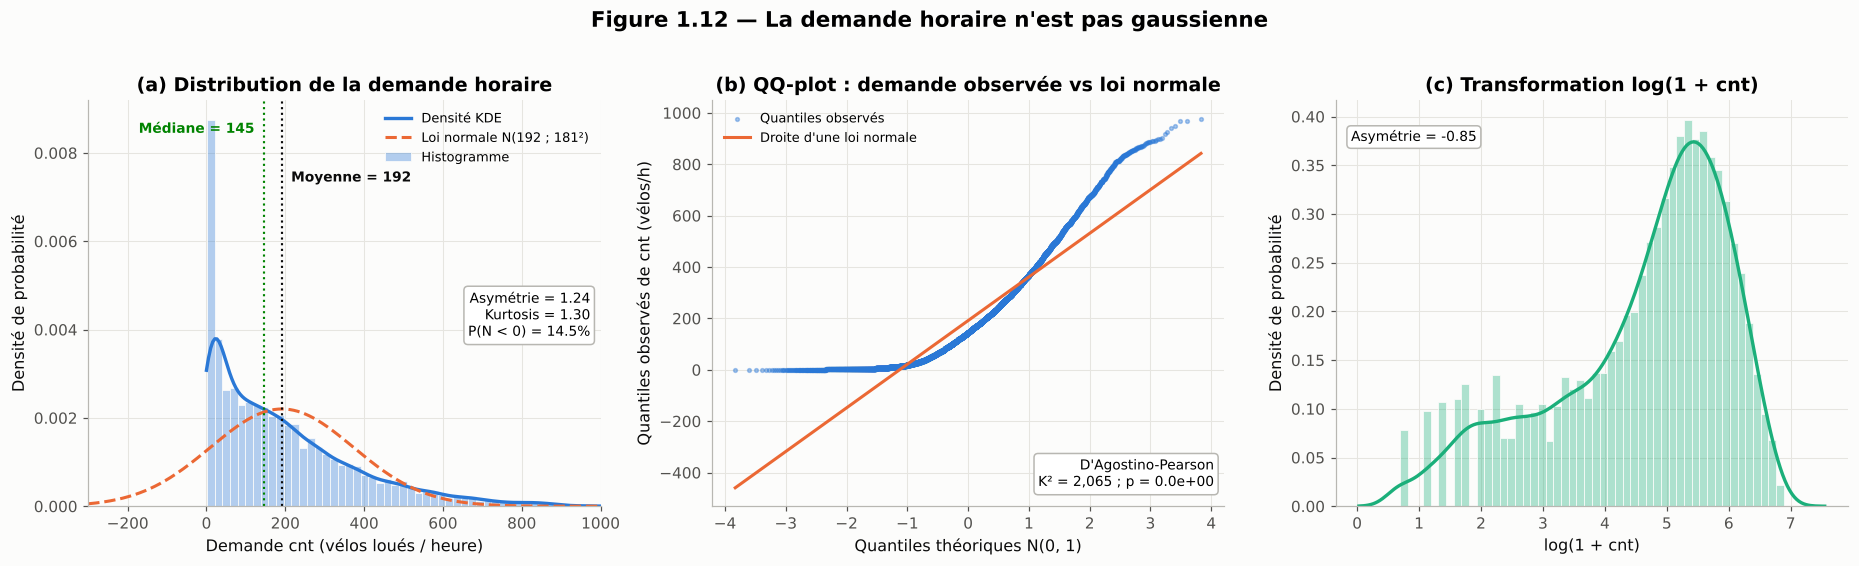

Indicateur,Valeur
Asymétrie de cnt,1.242
Kurtosis (excès) de cnt,1.300
Statistique K² (D'Agostino-Pearson),"2,064.7"
p-valeur,0.00e+00
Décision au seuil de 5 %,Normalité rejetée
"Probabilité de demande négative sous N(µ, σ²)",14.51%
Asymétrie de log(1 + cnt),-0.851


In [13]:
# ============================================================================
# 1.12 VISUALISATION 1 : DISTRIBUTION DE LA CIBLE
# ============================================================================
y_all = bike_new[TARGET]
mu, sigma = y_all.mean(), y_all.std()
k2, p_val = stats.normaltest(y_all)
log_y = np.log1p(y_all)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) Histogramme + KDE + loi normale de mêmes moments
ax = axes[0]
sns.histplot(y_all, bins=50, stat="density", color=COULEURS["bleu"], alpha=0.35,
             edgecolor=COULEURS["fond"], ax=ax, label="Histogramme")
sns.kdeplot(y_all, color=COULEURS["bleu"], lw=2.2, ax=ax, label="Densité KDE", clip=(0, None))
xs = np.linspace(-300, 1000, 400)
ax.plot(xs, stats.norm.pdf(xs, mu, sigma), color=COULEURS["orange"], lw=2, ls="--",
        label=f"Loi normale N({mu:.0f} ; {sigma:.0f}²)")
for val, nom, coul, haut, dx, ha in [(mu, "Moyenne", COULEURS["encre"], 0.80, 6, "left"),
                                     (y_all.median(), "Médiane", COULEURS["vert"], 0.92, -6, "right")]:
    ax.axvline(val, color=coul, lw=1.4, ls=":")
    ax.annotate(f"{nom} = {val:.0f}", (val, ax.get_ylim()[1] * haut), xytext=(dx, 0),
                textcoords="offset points", fontsize=9, color=coul, ha=ha, fontweight="bold")
ax.set_xlim(-300, 1000)
ax.set_title("(a) Distribution de la demande horaire")
ax.set_xlabel("Demande cnt (vélos loués / heure)")
ax.set_ylabel("Densité de probabilité")
ax.legend(loc="upper right", fontsize=8.5)
ax.text(0.98, 0.42, f"Asymétrie = {y_all.skew():.2f}\nKurtosis = {y_all.kurt():.2f}\n"
                    f"P(N < 0) = {stats.norm.cdf(0, mu, sigma):.1%}",
        transform=ax.transAxes, ha="right", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec=COULEURS["gris"]))

# (b) QQ-plot contre la loi normale
ax = axes[1]
(osm, osr), (pente, ordo, r) = stats.probplot(y_all, dist="norm")
ax.scatter(osm, osr, s=6, color=COULEURS["bleu"], alpha=0.4, label="Quantiles observés")
ax.plot(osm, pente * osm + ordo, color=COULEURS["orange"], lw=2, label="Droite d'une loi normale")
ax.set_title("(b) QQ-plot : demande observée vs loi normale")
ax.set_xlabel("Quantiles théoriques N(0, 1)")
ax.set_ylabel("Quantiles observés de cnt (vélos/h)")
ax.legend(loc="upper left", fontsize=8.5)
ax.text(0.98, 0.05, f"D'Agostino-Pearson\nK² = {k2:,.0f} ; p = {p_val:.1e}",
        transform=ax.transAxes, ha="right", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec=COULEURS["gris"]))

# (c) Distribution de log(1 + cnt)
ax = axes[2]
sns.histplot(log_y, bins=50, stat="density", color=COULEURS["vert_eau"], alpha=0.35,
             edgecolor=COULEURS["fond"], ax=ax)
sns.kdeplot(log_y, color=COULEURS["vert_eau"], lw=2.2, ax=ax)
ax.set_title("(c) Transformation log(1 + cnt)")
ax.set_xlabel("log(1 + cnt)")
ax.set_ylabel("Densité de probabilité")
ax.text(0.03, 0.9, f"Asymétrie = {log_y.skew():.2f}", transform=ax.transAxes, fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec=COULEURS["gris"]))

fig.suptitle("Figure 1.12 — La demande horaire n'est pas gaussienne", fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_1_12_distribution_cnt")
plt.show()

normalite = pd.DataFrame({
    "Indicateur": ["Asymétrie de cnt", "Kurtosis (excès) de cnt", "Statistique K² (D'Agostino-Pearson)",
                   "p-valeur", "Décision au seuil de 5 %", "Probabilité de demande négative sous N(µ, σ²)",
                   "Asymétrie de log(1 + cnt)"],
    "Valeur": [f"{y_all.skew():.3f}", f"{y_all.kurt():.3f}", f"{k2:,.1f}", f"{p_val:.2e}",
               "Normalité rejetée" if p_val < 0.05 else "Normalité non rejetée",
               f"{stats.norm.cdf(0, mu, sigma):.2%}", f"{log_y.skew():.3f}"],
})
afficher_tableau(normalite, "Tableau 1.12 — Test de normalité de la demande", index=False)

**Finding (Constats chiffrés)**
* La distribution est **fortement asymétrique à droite** (asymétrie = **1,24**, kurtosis = **1,30**) : le mode se situe sous 50 vélos/h, la médiane à **145**, la moyenne à **192**, avec une longue queue jusqu'à **977**.
* Le QQ-plot s'écarte de la droite normale aux deux extrémités : la queue gauche est bornée par 0 et la queue droite est bien plus épaisse que celle d'une gaussienne.
* Le test de D'Agostino-Pearson donne **K² ≈ 2 065** et une p-valeur numériquement nulle : la normalité est **rejetée** sans ambiguïté.
* Une loi normale de mêmes moments attribuerait **14,5 %** de probabilité à une demande négative, ce qui est physiquement absurde.
* La transformation $\log(1+\text{cnt})$ inverse le problème (asymétrie = **-0,85**) sans le résoudre.

**Insights (Interprétation métier et lien avec l'article)**
* C'est la **preuve statistique** qui motive le passage au modèle One-Step. Le stock de sécurité gaussien $z^* \sigma$ repose sur une loi qui ne décrit pas la demande. Le quantile critique $\alpha^* = 0,7143$ calculé sous l'hypothèse normale sera donc mal placé.
* L'approche FBNV de Jing Shi (régression quantile, ou quantile empirique en équation (1)) ne fait **aucune hypothèse de forme** sur la distribution : elle apprend directement le quantile conditionnel $F^{-1}_{D \mid \mathbf{x}}(\alpha^*)$. Elle est par construction adaptée à une demande asymétrique et à queue lourde.

## 1.13 Visualisation 2 : boxplots des valeurs extrêmes et de la saisonnalité

**Pourquoi ?** Les boîtes à moustaches résument la médiane, la dispersion (IQR) et les valeurs extrêmes au-delà de $Q_3 + 1,5 \times IQR$ (règle de Tukey). On les trace pour la demande globale puis par saison, par mois et par situation météo. La question métier est double : les valeurs extrêmes sont-elles des **erreurs à supprimer** ou des **pics de demande réels** à servir ? Et la dispersion varie-t-elle selon le contexte (hétéroscédasticité) ?

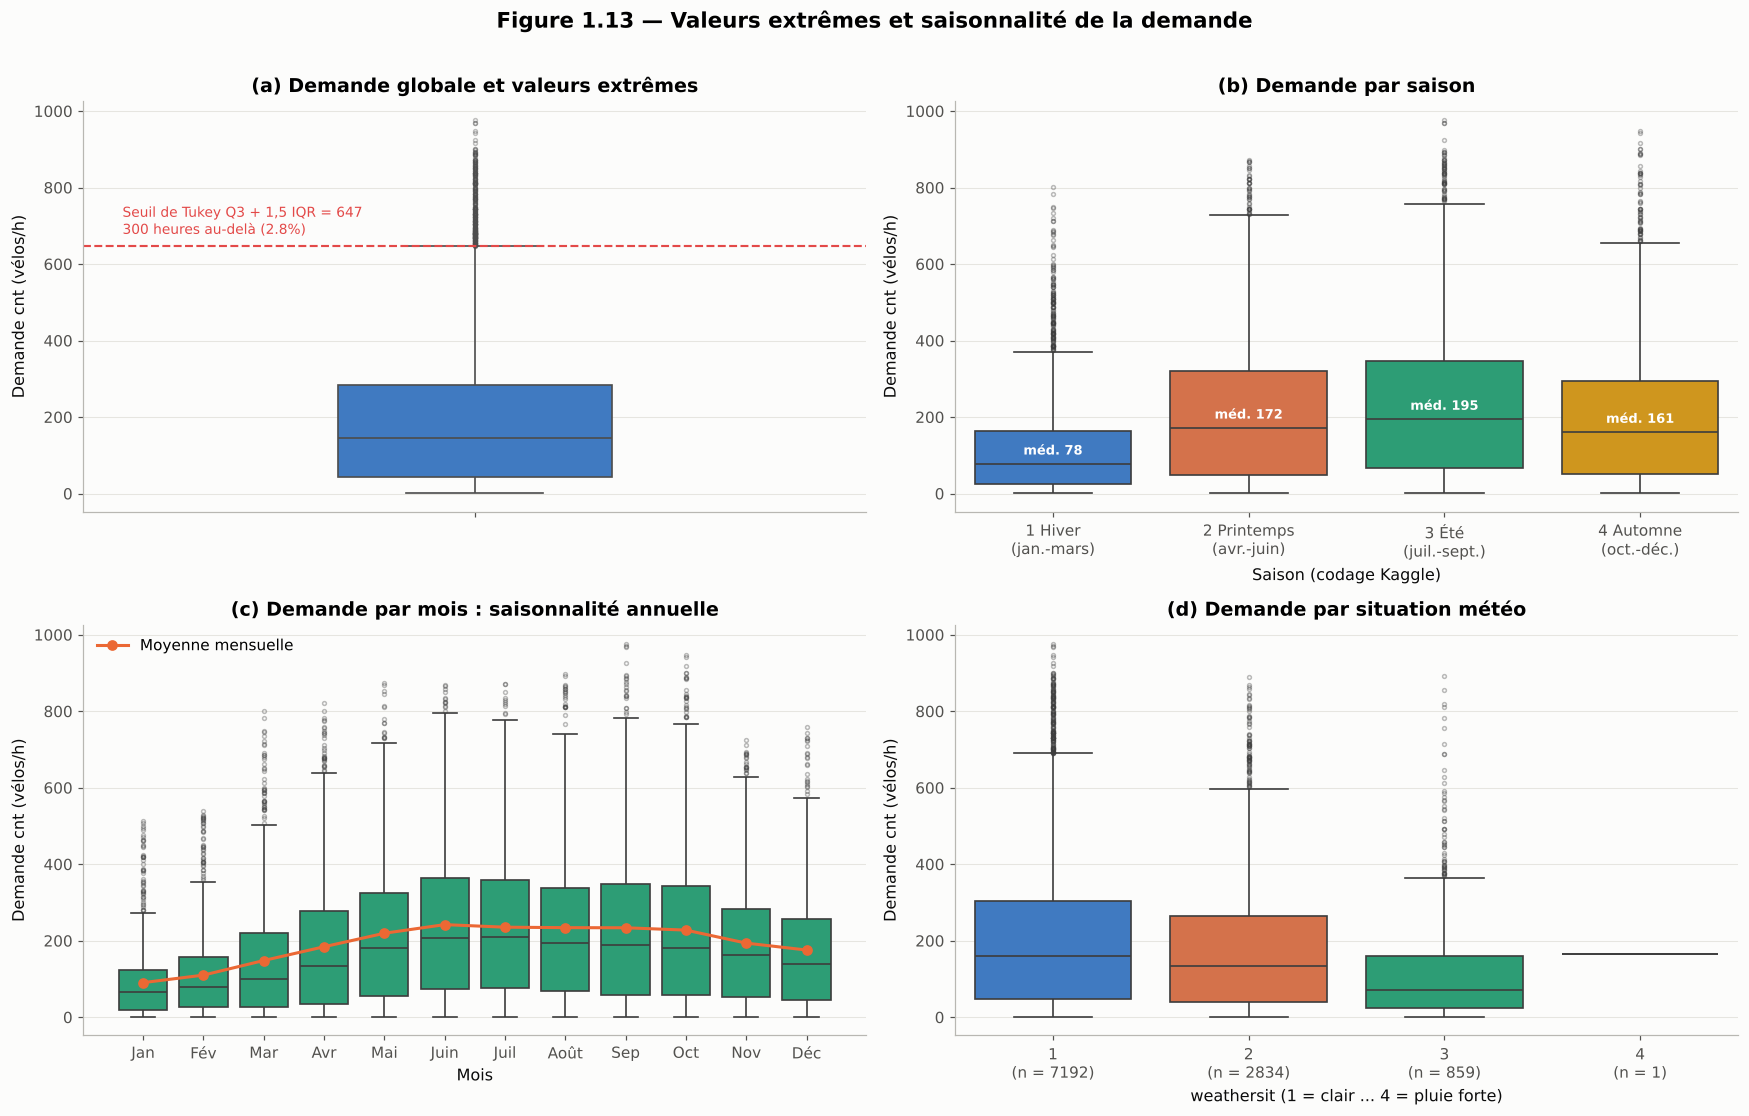

,Heures,Moyenne,Médiane,Écart-type,Max,CV,Heures extrêmes (> seuil Tukey)
1 Hiver (jan.-mars),2686,116.3,78,125.3,801,1.08,16
2 Printemps (avr.-juin),2733,215.3,172,192.0,873,0.89,99
3 Été (juil.-sept.),2733,234.4,195,197.2,977,0.84,116
4 Automne (oct.-déc.),2734,199.0,161,177.6,948,0.89,69


Caractéristique des heures extrêmes,Heures extrêmes,Ensemble des heures
Nombre,300,10886
Part en jour ouvré,83.7%,68.1%
Part aux heures de pointe (7-9 h et 16-19 h),87.3%,29.3%
Part en météo claire (weathersit = 1),75.7%,66.1%
Température moyenne (°C),26.2,20.2
Part en 2012,100.0%,50.2%


In [14]:
# ============================================================================
# 1.13 VISUALISATION 2 : BOXPLOTS (OUTLIERS ET SAISONNALITÉ)
# ============================================================================
q1, q3 = y_all.quantile([0.25, 0.75])
iqr = q3 - q1
seuil_haut = q3 + 1.5 * iqr
outliers = bike_new[y_all > seuil_haut]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
style_box = dict(linewidth=1.1, fliersize=2.5, flierprops=dict(marker="o", alpha=0.35))

ax = axes[0, 0]
sns.boxplot(y=y_all, color=COULEURS["bleu"], width=0.35, ax=ax, **style_box)
ax.axhline(seuil_haut, color=COULEURS["rouge"], ls="--", lw=1.4)
ax.annotate(f"Seuil de Tukey Q3 + 1,5 IQR = {seuil_haut:.0f}\n{len(outliers)} heures au-delà "
            f"({len(outliers) / len(bike_new):.1%})", (-0.45, seuil_haut), xytext=(0, 8),
            textcoords="offset points", fontsize=9, color=COULEURS["rouge"])
ax.set_title("(a) Demande globale et valeurs extrêmes")
ax.set_ylabel("Demande cnt (vélos/h)")

ax = axes[0, 1]
noms_saisons = ["1 Hiver\n(jan.-mars)", "2 Printemps\n(avr.-juin)", "3 Été\n(juil.-sept.)", "4 Automne\n(oct.-déc.)"]
sns.boxplot(data=bike_new, x="season", y=TARGET, hue="season", palette=PALETTE_CAT[:4],
            legend=False, ax=ax, **style_box)
med_s = bike_new.groupby("season")[TARGET].median()
for i, m in enumerate(med_s):
    ax.annotate(f"méd. {m:.0f}", (i, m), xytext=(0, 6), textcoords="offset points", ha="center",
                fontsize=8.5, color="white", fontweight="bold")
ax.set_xticks(range(4), noms_saisons)
ax.set_title("(b) Demande par saison")
ax.set_xlabel("Saison (codage Kaggle)")
ax.set_ylabel("Demande cnt (vélos/h)")

ax = axes[1, 0]
sns.boxplot(data=bike_new, x="mnth", y=TARGET, color=COULEURS["vert_eau"], ax=ax, **style_box)
moy_m = bike_new.groupby("mnth")[TARGET].mean()
ax.plot(range(12), moy_m.values, color=COULEURS["orange"], marker="o", ms=6, lw=2, label="Moyenne mensuelle")
ax.set_xticks(range(12), ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])
ax.set_title("(c) Demande par mois : saisonnalité annuelle")
ax.set_xlabel("Mois")
ax.set_ylabel("Demande cnt (vélos/h)")
ax.legend(loc="upper left")

ax = axes[1, 1]
sns.boxplot(data=bike_new, x="weathersit", y=TARGET, hue="weathersit", palette=PALETTE_CAT[:4],
            legend=False, ax=ax, **style_box)
eff_w = bike_new["weathersit"].value_counts().sort_index()
ax.set_xticks(range(4), [f"{k}\n(n = {eff_w[k]})" for k in eff_w.index])
ax.set_title("(d) Demande par situation météo")
ax.set_xlabel("weathersit (1 = clair ... 4 = pluie forte)")
ax.set_ylabel("Demande cnt (vélos/h)")

fig.suptitle("Figure 1.13 — Valeurs extrêmes et saisonnalité de la demande", fontweight="bold", fontsize=14, y=1.01)
plt.tight_layout()
sauver_figure(fig, "fig_1_13_boxplots_saisonnalite")
plt.show()

saison_tab = bike_new.groupby("season")[TARGET].agg(["count", "mean", "median", "std", "max"])
saison_tab["CV"] = saison_tab["std"] / saison_tab["mean"]
saison_tab["Heures extrêmes (> seuil Tukey)"] = bike_new[y_all > seuil_haut].groupby("season").size()
saison_tab.index = ["1 Hiver (jan.-mars)", "2 Printemps (avr.-juin)", "3 Été (juil.-sept.)", "4 Automne (oct.-déc.)"]
saison_tab.columns = ["Heures", "Moyenne", "Médiane", "Écart-type", "Max", "CV", "Heures extrêmes (> seuil Tukey)"]
afficher_tableau(saison_tab, "Tableau 1.13a — Demande par saison",
                 formats={"Moyenne": "{:.1f}", "Médiane": "{:.0f}", "Écart-type": "{:.1f}", "CV": "{:.2f}"},
                 degrade=["Moyenne"])

profil_out = pd.DataFrame({
    "Caractéristique des heures extrêmes": ["Nombre", "Part en jour ouvré",
                                            "Part aux heures de pointe (7-9 h et 16-19 h)",
                                            "Part en météo claire (weathersit = 1)", "Température moyenne (°C)",
                                            "Part en 2012"],
    "Heures extrêmes": [len(outliers), f"{outliers['workingday'].mean():.1%}",
                        f"{outliers['hr'].isin([7, 8, 9, 16, 17, 18, 19]).mean():.1%}",
                        f"{(outliers['weathersit'] == 1).mean():.1%}", f"{outliers['temp'].mean():.1f}",
                        f"{(outliers['yr'] == 2012).mean():.1%}"],
    "Ensemble des heures": [len(bike_new), f"{bike_new['workingday'].mean():.1%}",
                            f"{bike_new['hr'].isin([7, 8, 9, 16, 17, 18, 19]).mean():.1%}",
                            f"{(bike_new['weathersit'] == 1).mean():.1%}", f"{bike_new['temp'].mean():.1f}",
                            f"{(bike_new['yr'] == 2012).mean():.1%}"],
})
afficher_tableau(profil_out, "Tableau 1.13b — Profil des heures extrêmes : erreurs ou vrais pics ?", index=False)

**Finding (Constats chiffrés)**
* Le seuil de Tukey vaut $Q_3 + 1,5 \times IQR = 284 + 1,5 \times 242 = $ **647 vélos/h** ; **300 heures (2,76 %)** le dépassent.
* Ces heures extrêmes ne sont pas aléatoires (Tableau 1.13b) : **87,3 %** tombent aux heures de pointe (contre 29,3 % de l'ensemble des heures), **83,7 %** en jour ouvré, **75,7 %** par temps clair, avec une température moyenne de **26,2 °C** (contre 20,2 °C), et **100 %** en 2012. Seules **16** sont observées en hiver, contre **116** en été.
* La saisonnalité est marquée : la demande moyenne passe de **116 vélos/h** en hiver (saison 1) à **234 vélos/h** en été (saison 3), soit **× 2,0**. Le profil mensuel culmine en juin-juillet et plonge en janvier-février.
* La dispersion suit le niveau : l'écart-type passe de **125** en hiver à **197** en été. La demande diminue nettement avec la dégradation de la météo (situations 2 et 3).

**Insights (Interprétation métier et lien avec l'article)**
* Les « outliers » statistiques sont en réalité les **pics de demande les plus rentables** à servir : les supprimer reviendrait à apprendre au modèle à ignorer les heures de pointe, et donc à **sous-stocker exactement quand la rupture coûte le plus cher**. Ils sont **conservés**.
* L'écart-type qui croît avec la moyenne est la signature de l'**hétéroscédasticité**. Un stock de sécurité constant $z^*\sigma$ (Two-Step) est sur-dimensionné en hiver et sous-dimensionné en été. Le modèle One-Step FBNV, qui apprend un quantile **conditionnel** au contexte, ajuste automatiquement la marge de sécurité à la saison.

## 1.14 Visualisation 3 : profil horaire bimodal (jours ouvrés vs week-ends)

**Pourquoi ?** Pour un opérateur de vélos, la variable de décision la plus fine est l'heure. On trace la demande moyenne par heure (avec intervalle de confiance à 95 %) en distinguant les jours ouvrés des week-ends et jours fériés, puis le profil par jour de la semaine. Si les deux courbes ont des formes **différentes** (et pas seulement des niveaux différents), l'effet de l'heure **dépend** du type de jour : c'est une **interaction**, qu'un modèle linéaire additif ne peut pas représenter.

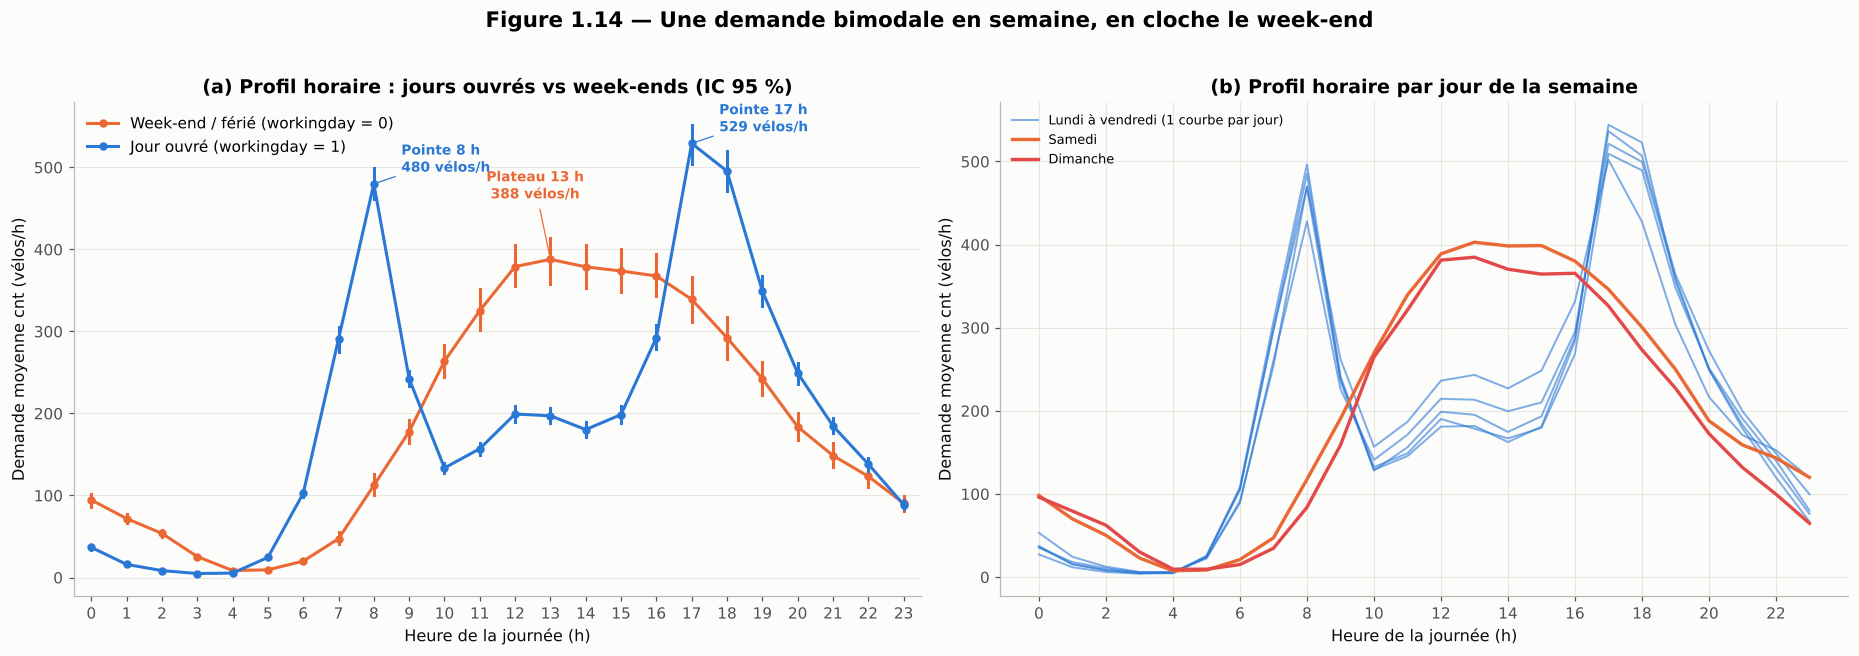

,Week-end / férié,Jour ouvré,Ratio ouvré / week-end
0 h,94.5,36.7,0.4
3 h,25.5,4.9,0.2
4 h,8.5,5.4,0.6
7 h,47.3,290.7,6.1
8 h,112.3,479.9,4.3
9 h,177.9,242.3,1.4
12 h,379.1,199.3,0.5
13 h,387.8,197.2,0.5
14 h,378.7,180.4,0.5
17 h,339.1,529.2,1.6


In [15]:
# ============================================================================
# 1.14 VISUALISATION 3 : PROFIL HORAIRE
# ============================================================================
profil = bike_new.groupby(["workingday", "hr"])[TARGET].mean().unstack(0)
profil.columns = ["Week-end / férié", "Jour ouvré"]

fig, axes = plt.subplots(1, 2, figsize=(17, 5.8))

ax = axes[0]
sns.pointplot(data=bike_new, x="hr", y=TARGET, hue="workingday",
              palette={0: COULEURS["orange"], 1: COULEURS["bleu"]},
              errorbar=("ci", 95), markersize=4, linewidth=2, ax=ax)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Week-end / férié (workingday = 0)", "Jour ouvré (workingday = 1)"], loc="upper left")
for h in [8, 17]:
    v = profil.loc[h, "Jour ouvré"]
    ax.annotate(f"Pointe {h} h\n{v:.0f} vélos/h", (h, v), xytext=(18, 8), textcoords="offset points",
                fontsize=9, color=COULEURS["bleu"], fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=COULEURS["bleu"], lw=0.8))
h_we = profil["Week-end / férié"].idxmax()
v_we = profil["Week-end / férié"].max()
ax.annotate(f"Plateau {h_we} h\n{v_we:.0f} vélos/h", (h_we, v_we), xytext=(-10, 40), textcoords="offset points",
            fontsize=9, color=COULEURS["orange"], fontweight="bold", ha="center",
            arrowprops=dict(arrowstyle="-", color=COULEURS["orange"], lw=0.8))
ax.set_title("(a) Profil horaire : jours ouvrés vs week-ends (IC 95 %)")
ax.set_xlabel("Heure de la journée (h)")
ax.set_ylabel("Demande moyenne cnt (vélos/h)")

ax = axes[1]
noms_jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
couleurs_jours = [COULEURS["bleu"]] * 5 + [COULEURS["orange"], COULEURS["rouge"]]
moy_jh = bike_new.groupby(["weekday", "hr"])[TARGET].mean().unstack(0)
for j in range(7):
    ax.plot(moy_jh.index, moy_jh[j], color=couleurs_jours[j], lw=2.2 if j >= 5 else 1.3,
            alpha=1 if j >= 5 else 0.6,
            label=("Lundi à vendredi (1 courbe par jour)" if j == 0 else None) if j < 5 else noms_jours[j])
ax.set_title("(b) Profil horaire par jour de la semaine")
ax.set_xlabel("Heure de la journée (h)")
ax.set_ylabel("Demande moyenne cnt (vélos/h)")
ax.set_xticks(range(0, 24, 2))
ax.legend(fontsize=8.5, loc="upper left")

fig.suptitle("Figure 1.14 — Une demande bimodale en semaine, en cloche le week-end",
             fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_1_14_profil_horaire")
plt.show()

heures_cles = [0, 3, 4, 7, 8, 9, 12, 13, 14, 17, 18, 19, 23]
tab_h = profil.loc[heures_cles].copy()
tab_h["Ratio ouvré / week-end"] = tab_h["Jour ouvré"] / tab_h["Week-end / férié"]
tab_h.index = [f"{h} h" for h in heures_cles]
afficher_tableau(tab_h, "Tableau 1.14 — Demande moyenne (vélos/h) aux heures clés selon le type de jour",
                 formats="{:.1f}", degrade=["Jour ouvré", "Week-end / férié"])

**Finding (Constats chiffrés)**
* **Jours ouvrés : profil bimodal.** Deux pointes nettes, à **8 h (≈ 480 vélos/h)** et à **17 h (≈ 529 vélos/h)**, encore 496 à 18 h, séparées par un creux en milieu de journée (≈ 180 à 200 vélos/h entre 12 h et 14 h).
* **Week-ends et fériés : profil en cloche.** Un plateau unique entre **12 h et 16 h**, culminant à **≈ 388 vélos/h à 13 h**, et seulement ≈ 112 vélos/h à 8 h.
* Le rapport ouvré / week-end vaut **≈ 4,3 à 8 h** mais **≈ 0,5 à 13 h** : l'effet de `workingday` **change de signe** selon l'heure.
* La nuit, la demande s'effondre (≈ 5 vélos/h à 3-4 h en jour ouvré). Les cinq jours ouvrés ont des profils quasi superposables, tout comme samedi et dimanche.

**Insights (Interprétation métier et lien avec l'article)**
* Deux usages coexistent : les **trajets domicile-travail** des abonnés (pointes du matin et du soir) et les **loisirs** (après-midi du week-end). Le stock à positionner ne dépend donc pas de l'heure seule ni du jour seul, mais de leur **combinaison**.
* Un modèle linéaire additif $\beta_1 \cdot \text{hr} + \beta_2 \cdot \text{workingday}$ ne peut tracer qu'une droite décalée : il est structurellement incapable de reproduire deux pics. C'est l'explication de la future **rupture de performance** entre modèles linéaires et modèles par arbres (Étape 3), cohérente avec la supériorité du Random Forest observée par Jing Shi (§5.3).
* Pour la décision de stock, la nuit est la zone où le Two-Step gaspille le plus : il ajoute la même marge fixe $z^*\sigma_{\text{résidus}}$ (plusieurs dizaines de vélos selon le modèle) à une demande d'à peine 5 vélos/h.

## 1.15 Visualisation 4 : impact thermique (`temp` vs `cnt`)

**Pourquoi ?** La température est le principal facteur météo de l'usage du vélo. Un nuage de points avec droite de régression (`regplot`) mesure la force de la relation linéaire (coefficient de Pearson $r$, pente en vélos/h par °C). On le complète par la demande moyenne par tranche de 2 °C pour détecter une éventuelle **non-linéarité** (effet de saturation, ou baisse par fortes chaleurs) que la droite masquerait.

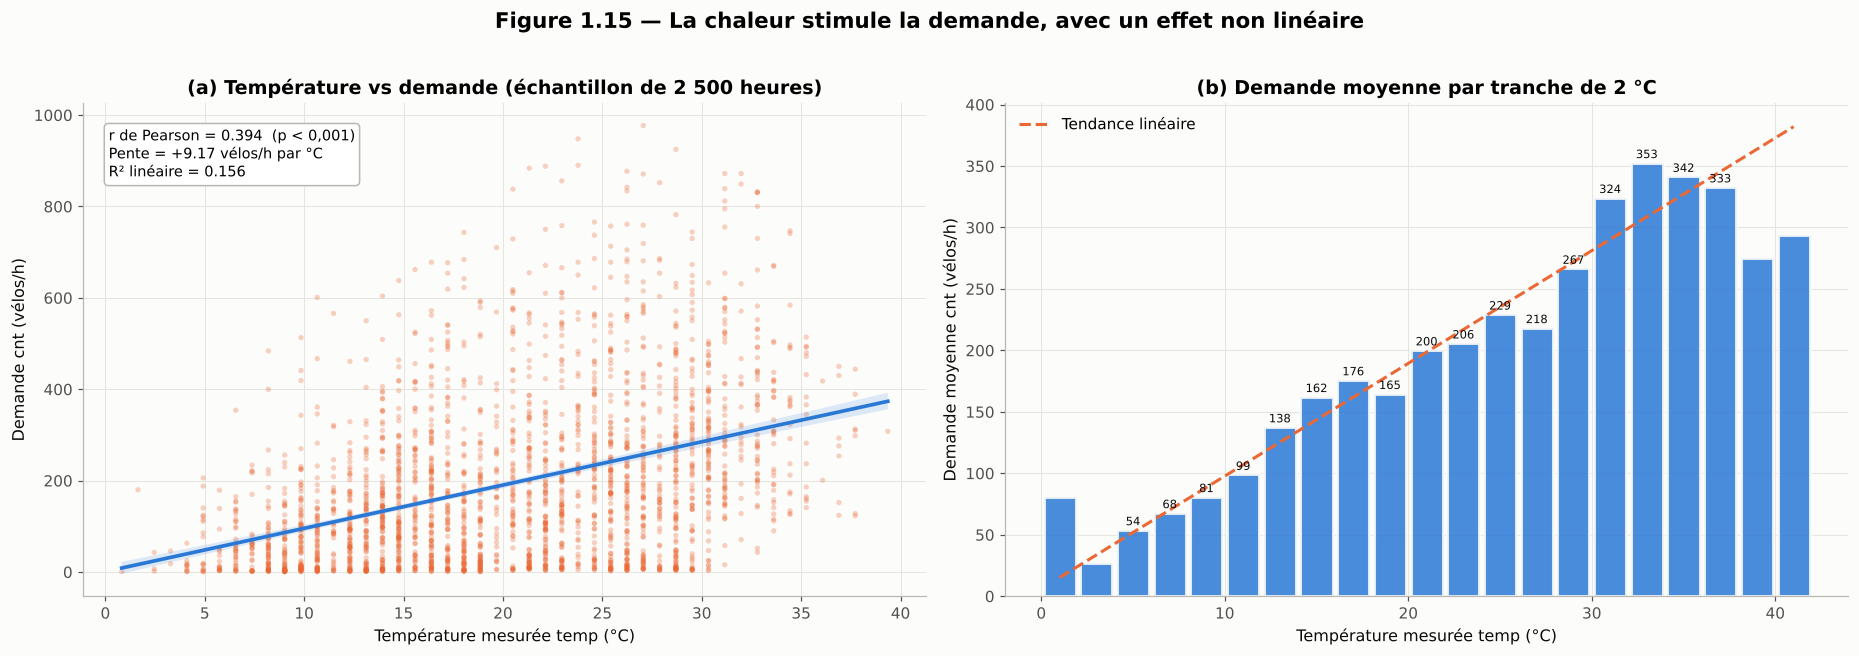

Variable météo,r de Pearson avec cnt,Sens de l'effet
temp,+0.394,Positif
atemp,+0.390,Positif
hum,-0.317,Négatif
windspeed,+0.101,Positif
weathersit,-0.129,Négatif


In [16]:
# ============================================================================
# 1.15 VISUALISATION 4 : EFFET THERMIQUE
# ============================================================================
r_temp, p_temp = stats.pearsonr(bike_new["temp"], y_all)
pente_t, ordo_t = np.polyfit(bike_new["temp"], y_all, 1)
echantillon = bike_new.sample(2500, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.8))

ax = axes[0]
sns.regplot(data=echantillon, x="temp", y=TARGET, ax=ax,
            scatter_kws=dict(s=12, alpha=0.3, color=COULEURS["orange"], edgecolor="none"),
            line_kws=dict(color=COULEURS["bleu"], lw=2.4))
ax.set_title("(a) Température vs demande (échantillon de 2 500 heures)")
ax.set_xlabel("Température mesurée temp (°C)")
ax.set_ylabel("Demande cnt (vélos/h)")
ax.text(0.03, 0.95, f"r de Pearson = {r_temp:.3f}  (p < 0,001)\nPente = +{pente_t:.2f} vélos/h par °C\n"
                    f"R² linéaire = {r_temp ** 2:.3f}",
        transform=ax.transAxes, va="top", fontsize=9.5,
        bbox=dict(boxstyle="round", fc="white", ec=COULEURS["gris"]))

ax = axes[1]
tranches = pd.cut(bike_new["temp"], bins=np.arange(0, 44, 2))
par_tranche = bike_new.groupby(tranches, observed=True)[TARGET].agg(["mean", "count"])
centres = [iv.mid for iv in par_tranche.index]
ax.bar(centres, par_tranche["mean"], width=1.75, color=COULEURS["bleu"], alpha=0.85,
       edgecolor=COULEURS["fond"], linewidth=2)
ax.plot(centres, pente_t * np.array(centres) + ordo_t, color=COULEURS["orange"], ls="--", lw=2,
        label="Tendance linéaire")
for x_, (m_, n_) in zip(centres, par_tranche.values):
    if n_ >= 30:
        ax.annotate(f"{m_:.0f}", (x_, m_), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=7.5, color=COULEURS["encre"])
ax.set_title("(b) Demande moyenne par tranche de 2 °C")
ax.set_xlabel("Température mesurée temp (°C)")
ax.set_ylabel("Demande moyenne cnt (vélos/h)")
ax.legend(loc="upper left")

fig.suptitle("Figure 1.15 — La chaleur stimule la demande, avec un effet non linéaire",
             fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_1_15_effet_thermique")
plt.show()

corr_meteo = pd.DataFrame({
    "Variable météo": ["temp", "atemp", "hum", "windspeed", "weathersit"],
    "r de Pearson avec cnt": [bike_new[v].corr(y_all) for v in ["temp", "atemp", "hum", "windspeed", "weathersit"]],
})
corr_meteo["Sens de l'effet"] = np.where(corr_meteo["r de Pearson avec cnt"] > 0, "Positif", "Négatif")
afficher_tableau(corr_meteo, "Tableau 1.15 — Corrélation linéaire des variables météo avec la demande",
                 formats={"r de Pearson avec cnt": "{:+.3f}"}, index=False)

**Finding (Constats chiffrés)**
* La corrélation entre température et demande est **positive et modérée** : **r = 0,394** (p < 0,001). Chaque degré supplémentaire ajoute en moyenne **+9,17 vélos/h**.
* La température seule n'explique que **15,6 %** de la variance ($r^2$) : à température égale, la dispersion reste énorme, car l'heure de la journée domine.
* Par tranche de 2 °C, la demande moyenne croît de façon **non linéaire** : moins de 100 vélos/h sous 10 °C, environ 200 vélos/h vers 20 °C, un **maximum de 353 vélos/h entre 32 et 34 °C**, puis un **reflux** (≈ 275 à 295 vélos/h) au-delà de 38 °C : la canicule dissuade à son tour la pratique du vélo.
* Classement des autres effets météo : `atemp` (+0,390) presque identique à `temp`, `hum` (**-0,317**), `weathersit` (-0,129) et `windspeed` (+0,101).

**Insights (Interprétation métier et lien avec l'article)**
* La température est un levier d'anticipation puissant pour le planificateur, car elle est **prévisible ex-ante** grâce aux bulletins météo : c'est l'équivalent direct des indicateurs avancés (Baidu Index) de Jing Shi.
* La quasi-égalité des corrélations de `temp` et `atemp` laisse présager une **multicolinéarité sévère** entre ces deux variables : c'est le point de départ de l'Étape 2.
* Le $r^2$ limité à 15,6 % rappelle qu'aucune variable ne suffit seule : il faut un modèle **multivarié** capable de combiner heure, calendrier et météo, ce qui est le principe même du *Feature-Based* Newsvendor.

## 1.16 Synthèse de l'audit d'intégrité (Étape 1)

**Pourquoi ?** Un audit se conclut par un verdict explicite. Ce tableau récapitule chaque contrôle, son résultat et la décision prise, afin que le passage à l'Étape 2 repose sur une base documentée et vérifiable.

In [17]:
# ============================================================================
# 1.16 SYNTHÈSE DE L'ÉTAPE 1
# ============================================================================
synthese_1 = pd.DataFrame([
    ["1.1", "Intégrité du fichier", f"MD5 conforme : {md5 == MD5_ATTENDU}", "Fichier validé"],
    ["1.3", "Typage", "0 colonne texte, codes bornés", "Aucun encodage requis"],
    ["1.4", "Continuité temporelle", f"{len(heures_absentes)} heures absentes ({len(ts) / len(grille_complete):.2%} de complétude)",
     "Pas d'imputation, observations traitées comme indépendantes"],
    ["1.6", "Valeurs manquantes", f"{int(df_raw.isna().sum().sum())} cellule manquante (0,00 %)", "Aucune imputation"],
    ["1.7", "Doublons", f"{int(df_raw.duplicated().sum())} doublon", "Aucune suppression"],
    ["1.8", "Modalités", "0 code hors domaine ; weathersit = 4 observé 1 fois", "Conservé, interprétation prudente"],
    ["1.9", "Plausibilité physique", f"{len(hum0)} h à hum = 0 ; {len(vent0)} h à windspeed = 0",
     "Conservées et documentées"],
    ["1.10", "Fuite de données", "casual + registered = count sur 100 % des lignes", "casual et registered supprimées"],
    ["1.11", "Variables calendaires", "yr, mnth, hr, weekday créées ; 5/5 contrôles OK", "bike_new : 12 explicatives + cnt"],
    ["1.12", "Normalité de la cible", f"Asymétrie {y_all.skew():.2f}, p = {p_val:.1e}", "Normalité rejetée : argument pour le One-Step"],
    ["1.13", "Valeurs extrêmes", f"{len(outliers)} h > {seuil_haut:.0f} vélos/h (pics réels)", "Conservées"],
    ["1.14", "Profil horaire", "Bimodal en semaine, en cloche le week-end", "Interaction non linéaire hr × workingday"],
    ["1.15", "Effet thermique", f"r(temp, cnt) = {r_temp:.3f}", "Effet positif non linéaire"],
], columns=["Étape", "Contrôle", "Résultat", "Décision"])
afficher_tableau(synthese_1, "Tableau 1.16 — Synthèse de l'audit d'intégrité et de l'EDA", index=False)
print(f"Jeu analytique prêt pour l'Étape 2 : bike_new = {bike_new.shape[0]} lignes x {bike_new.shape[1]} colonnes")

Étape,Contrôle,Résultat,Décision
1.1,Intégrité du fichier,MD5 conforme : True,Fichier validé
1.3,Typage,"0 colonne texte, codes bornés",Aucun encodage requis
1.4,Continuité temporelle,58 heures absentes (99.47% de complétude),"Pas d'imputation, observations traitées comme indépendantes"
1.6,Valeurs manquantes,"0 cellule manquante (0,00 %)",Aucune imputation
1.7,Doublons,0 doublon,Aucune suppression
1.8,Modalités,0 code hors domaine ; weathersit = 4 observé 1 fois,"Conservé, interprétation prudente"
1.9,Plausibilité physique,22 h à hum = 0 ; 1313 h à windspeed = 0,Conservées et documentées
1.10,Fuite de données,casual + registered = count sur 100 % des lignes,casual et registered supprimées
1.11,Variables calendaires,"yr, mnth, hr, weekday créées ; 5/5 contrôles OK",bike_new : 12 explicatives + cnt
1.12,Normalité de la cible,"Asymétrie 1.24, p = 0.0e+00",Normalité rejetée : argument pour le One-Step


Jeu analytique prêt pour l'Étape 2 : bike_new = 10886 lignes x 13 colonnes


**Finding (Constats chiffrés)**
* **13 contrôles** réalisés, **aucune ligne supprimée** : les 10 886 observations sont conservées.
* **2 colonnes supprimées** pour fuite de données (`casual`, `registered`), **4 variables créées** (`yr`, `mnth`, `hr`, `weekday`), **3 variables renommées** (`weathersit`, `hum`, `cnt`).
* Jeu analytique final : **`bike_new` = 10 886 × 13** (12 variables explicatives + la cible).

**Insights (Interprétation métier et lien avec l'article)**
* La donnée est **saine** (aucun manquant, aucun doublon, aucun code parasite) mais **complexe** : demande asymétrique, hétéroscédastique, bimodale et pilotée par des interactions. Ce sont exactement les conditions dans lesquelles Jing Shi montre que l'approche intégrée FBNV surpasse l'approche séquentielle.
* Deux redondances ont été identifiées (`season` ↔ `mnth`, `workingday` ↔ `weekday`/`holiday`) et une troisième est suspectée (`temp` ↔ `atemp`). L'Étape 2 va les **quantifier** puis les **résoudre** par la sélection Lasso, comme au §4.2 de l'article.

---
# ÉTAPE 2 — Data engineering, multicolinéarité et sélection Lasso

Jing Shi (§4.2) part d'un constat : « l'introduction de certaines variables complique le calcul et augmente le risque de colinéarité, ce qui dégrade l'ajustement du modèle ». La solution proposée est la **régression Lasso**, qui sélectionne automatiquement les variables utiles. Nous reproduisons cette démarche en 7 micro-étapes :

| # | Micro-étape | Objectif |
|---|---|---|
| 2.1 | Partition d'apprentissage 87,5 % / 12,5 % | Isoler le jeu de test avant toute statistique apprise |
| 2.2 | Matrice de corrélation de Pearson | Repérer les variables liées à la demande et les colinéarités |
| 2.3 | Facteurs d'inflation de la variance (VIF) | Quantifier la multicolinéarité de façon multivariée |
| 2.4 | Standardisation sans fuite | Mettre les variables sur une échelle commune |
| 2.5 | Sélection Lasso ($\alpha = 0,5$) | Reproduire la sélection L1 de l'article |
| 2.6 | Robustesse de la sélection | Chemin de régularisation, LassoCV, comparaison avec l'OLS |
| 2.7 | Synthèse et jeu de variables retenu | Préparer l'Étape 3 |

## 2.1 Partition d'apprentissage gelée (87,5 % / 12,5 %) : prévenir la fuite de données

**Pourquoi ?** Toute statistique **apprise** sur les données (moyenne et écart-type du `StandardScaler`, coefficients du Lasso, corrélations servant à choisir des variables) doit être calculée **sur le seul jeu d'entraînement**. Sinon, le jeu de test influence les choix de modélisation, et la performance mesurée à l'Étape 5 est optimiste : c'est une fuite de données plus subtile que celle de la micro-étape 1.10.

L'article procède ainsi : « use the training set to explore the data and measure the correlation between different features and target variables » (§4.1). On fige donc **dès maintenant** la partition utilisée dans tout le notebook :
* ratio de l'article : **87,5 % entraînement / 12,5 % test** ;
* tirage aléatoire simple (« pure random sampling ») avec `random_state = 42`.

L'Étape 3 réutilisera exactement ces deux sous-ensembles.

In [18]:
# ============================================================================
# 2.1 PARTITION D'APPRENTISSAGE (87,5 % / 12,5 %)
# ============================================================================
X_full = bike_new[FEATURES]
y_full = bike_new[TARGET]
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.125, random_state=RANDOM_STATE)

partition = pd.DataFrame({
    "Sous-ensemble": ["Entraînement (train)", "Test", "Total"],
    "Observations": [len(X_train_raw), len(X_test_raw), len(X_full)],
    "Part": [len(X_train_raw) / len(X_full), len(X_test_raw) / len(X_full), 1.0],
    "Demande moyenne": [y_train.mean(), y_test.mean(), y_full.mean()],
    "Écart-type": [y_train.std(), y_test.std(), y_full.std()],
    "Médiane": [y_train.median(), y_test.median(), y_full.median()],
    "% jours ouvrés": [X_train_raw["workingday"].mean(), X_test_raw["workingday"].mean(), X_full["workingday"].mean()],
    "% année 2012": [(X_train_raw["yr"] == 2012).mean(), (X_test_raw["yr"] == 2012).mean(), (X_full["yr"] == 2012).mean()],
})
afficher_tableau(partition, "Tableau 2.1 — Partition 87,5 % / 12,5 % et représentativité du jeu de test",
                 formats={"Part": "{:.1%}", "Demande moyenne": "{:.2f}", "Écart-type": "{:.2f}",
                          "Médiane": "{:.0f}", "% jours ouvrés": "{:.1%}", "% année 2012": "{:.1%}"},
                 index=False)

ks = stats.ks_2samp(y_train, y_test)
print(f"Test de Kolmogorov-Smirnov (distribution de cnt, train vs test) : D = {ks.statistic:.4f} ; p = {ks.pvalue:.3f}")

Sous-ensemble,Observations,Part,Demande moyenne,Écart-type,Médiane,% jours ouvrés,% année 2012
Entraînement (train),9525,87.5%,191.83,181.10,145,68.1%,50.1%
Test,1361,12.5%,189.82,181.48,145,68.2%,50.7%
Total,10886,100.0%,191.57,181.14,145,68.1%,50.2%


Test de Kolmogorov-Smirnov (distribution de cnt, train vs test) : D = 0.0189 ; p = 0.782


**Finding (Constats chiffrés)**
* **9 525 observations d'entraînement (87,5 %)** et **1 361 observations de test (12,5 %)** : le ratio de l'article est reproduit exactement.
* Le jeu de test est représentatif : demande moyenne de **189,82** contre **191,83** en entraînement (écart-type 181,48 contre 181,10), et des proportions de jours ouvrés et d'année 2012 quasi identiques.
* Le test de Kolmogorov-Smirnov ne détecte aucune différence significative entre les deux distributions de `cnt` (p > 0,05, voir la sortie ci-dessus).

**Insights (Interprétation métier et lien avec l'article)**
* Jing Shi s'assure que « the test set can represent the whole data set » (§4.1) ; c'est vérifié ici sur la cible et sur les principales variables de stratification.
* À partir de cette cellule, **le jeu de test est mis sous scellé** : il ne servira qu'à l'évaluation finale de l'Étape 5 (Tableaux 8 et 9). Toutes les analyses de l'Étape 2 portent sur les 9 525 heures d'entraînement.

## 2.2 Matrice de corrélation de Pearson (jeu d'entraînement)

**Pourquoi ?** Le coefficient de Pearson mesure l'intensité de la relation **linéaire** entre deux variables :

$$r_{XY} = \frac{\sum_i (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_i (x_i - \bar{x})^2}\,\sqrt{\sum_i (y_i - \bar{y})^2}} \in [-1 ; 1]$$

On l'utilise à deux fins, comme dans l'article :
1. **pertinence** : quelles variables sont les plus liées à la demande `cnt` (dernière ligne de la matrice) ?
2. **redondance** : quelles paires de variables explicatives sont si corrélées ($|r| > 0,6$) qu'elles portent la même information ? Une forte colinéarité rend les coefficients d'une régression instables et ininterprétables.

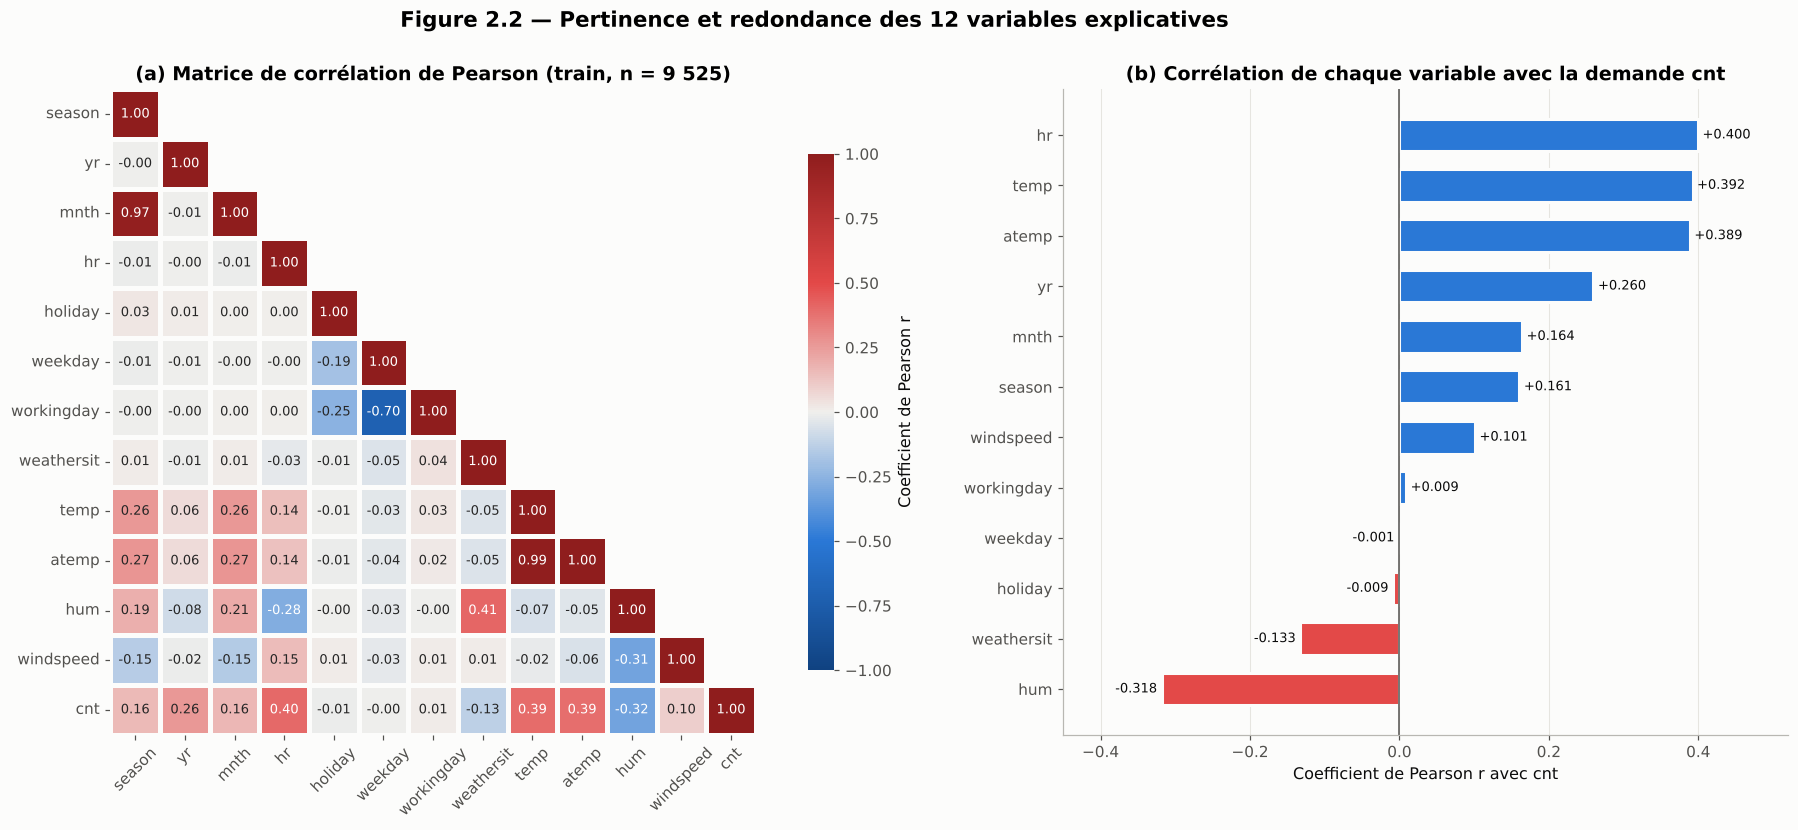

Variable A,Variable B,r de Pearson,Niveau,Explication métier
temp,atemp,+0.986,"Critique (|r| > 0,9)",La température ressentie dérive de la température mesurée
season,mnth,+0.972,"Critique (|r| > 0,9)",La saison est une fonction du mois
weekday,workingday,-0.704,"Fort (|r| > 0,6)",Samedi et dimanche ne sont jamais ouvrés
weathersit,hum,+0.410,Modéré,Lien physique ou calendaire partiel
hum,windspeed,-0.314,Modéré,Lien physique ou calendaire partiel
hr,hum,-0.278,Modéré,Lien physique ou calendaire partiel
mnth,atemp,+0.267,Modéré,Lien physique ou calendaire partiel
season,atemp,+0.266,Modéré,Lien physique ou calendaire partiel
season,temp,+0.261,Modéré,Lien physique ou calendaire partiel
mnth,temp,+0.260,Modéré,Lien physique ou calendaire partiel


,Rang,r avec cnt,|r|
hr,1,+0.400,0.400
temp,2,+0.392,0.392
atemp,3,+0.389,0.389
hum,4,-0.318,0.318
yr,5,+0.260,0.260
mnth,6,+0.164,0.164
season,7,+0.161,0.161
weathersit,8,-0.133,0.133
windspeed,9,+0.101,0.101
workingday,10,+0.009,0.009


In [19]:
# ============================================================================
# 2.2 MATRICE DE CORRÉLATION DE PEARSON
# ============================================================================
train_df = pd.concat([X_train_raw, y_train], axis=1)
corr = train_df.corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.45, 1]})

ax = axes[0]
masque = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=masque, annot=True, fmt=".2f", cmap=CMAP_DIV, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor=COULEURS["fond"], annot_kws={"size": 8.5}, square=True,
            cbar_kws={"label": "Coefficient de Pearson r", "shrink": 0.8}, ax=ax)
ax.set_title("(a) Matrice de corrélation de Pearson (train, n = 9 525)")
ax.tick_params(axis="x", rotation=45)
ax.grid(False)

ax = axes[1]
r_cible = corr[TARGET].drop(TARGET).sort_values()
couleurs_r = [COULEURS["rouge"] if v < 0 else COULEURS["bleu"] for v in r_cible]
ax.barh(r_cible.index, r_cible.values, color=couleurs_r, height=0.65, edgecolor=COULEURS["fond"], linewidth=2)
annoter_barres(ax, fmt="{:+.3f}", horizontal=True)
ax.axvline(0, color=COULEURS["encre_2"], lw=1)
ax.set_xlim(-0.45, 0.52)
ax.set_title("(b) Corrélation de chaque variable avec la demande cnt")
ax.set_xlabel("Coefficient de Pearson r avec cnt")
ax.grid(axis="y", visible=False)

fig.suptitle("Figure 2.2 — Pertinence et redondance des 12 variables explicatives",
             fontweight="bold", fontsize=14, y=1.0)
plt.tight_layout()
sauver_figure(fig, "fig_2_2_correlation_pearson")
plt.show()

# Paires de variables explicatives fortement colinéaires
paires = []
for i, a in enumerate(FEATURES):
    for b_ in FEATURES[i + 1:]:
        r_ab = corr.loc[a, b_]
        if abs(r_ab) >= 0.25:
            paires.append({"Variable A": a, "Variable B": b_, "r de Pearson": r_ab, "|r|": abs(r_ab),
                           "Niveau": "Critique (|r| > 0,9)" if abs(r_ab) > 0.9 else
                                     "Fort (|r| > 0,6)" if abs(r_ab) > 0.6 else "Modéré",
                           "Explication métier": {
                               ("season", "mnth"): "La saison est une fonction du mois",
                               ("temp", "atemp"): "La température ressentie dérive de la température mesurée",
                               ("weekday", "workingday"): "Samedi et dimanche ne sont jamais ouvrés",
                           }.get((a, b_), "Lien physique ou calendaire partiel")})
tab_paires = pd.DataFrame(paires).sort_values("|r|", ascending=False).drop(columns="|r|")
afficher_tableau(tab_paires, "Tableau 2.2a — Paires de variables explicatives corrélées (|r| ≥ 0,25)",
                 formats={"r de Pearson": "{:+.3f}"}, index=False)

tab_r = r_cible.sort_values(key=abs, ascending=False).rename("r avec cnt").to_frame()
tab_r["Rang"] = range(1, len(tab_r) + 1)
tab_r["|r|"] = tab_r["r avec cnt"].abs()
afficher_tableau(tab_r[["Rang", "r avec cnt", "|r|"]],
                 "Tableau 2.2b — Classement des variables par corrélation absolue avec la demande",
                 formats={"r avec cnt": "{:+.3f}", "|r|": "{:.3f}"}, degrade=["|r|"])

**Finding (Constats chiffrés)**

*Colinéarités entre variables explicatives (jeu d'entraînement) :*

| Paire | r de Pearson | Niveau | Cause |
|---|---|---|---|
| `temp` ↔ `atemp` | **+0,99** | Critique | La température ressentie est calculée à partir de la température |
| `season` ↔ `mnth` | **+0,97** | Critique | La saison est une fonction déterministe du mois |
| `weekday` ↔ `workingday` | **-0,70** | Fort | Samedi (5) et dimanche (6) ne sont jamais ouvrés |
| `weathersit` ↔ `hum` | +0,41 | Modéré | La pluie s'accompagne d'une forte humidité |
| `hum` ↔ `windspeed` | -0,31 | Modéré | Le vent assèche l'air |

*Corrélation avec la demande :* `hr` (**+0,400**), `temp` (+0,392), `atemp` (+0,389), `hum` (**-0,318**) et `yr` (+0,260) dominent. `weekday`, `workingday` et `holiday` ont une corrélation linéaire quasi nulle avec `cnt` ($|r| < 0,01$).

**Insights (Interprétation métier et lien avec l'article)**
* Les trois colinéarités fortes attendues sont confirmées (**0,97 ; 0,99 ; -0,70**). Garder les deux membres de chaque paire ne fait que dupliquer l'information et rend instables les coefficients d'une régression linéaire.
* **Attention à l'interprétation :** une corrélation linéaire nulle ne signifie pas une variable inutile. `workingday` a un $r \approx 0,01$ avec `cnt`, alors que la micro-étape 1.14 a montré qu'elle change complètement le **profil** horaire. Son effet est d'**interaction** (il augmente la demande à 8 h et la réduit à 13 h) et se compense en moyenne. Pearson ne voit que les effets linéaires et marginaux.
* Ce constat justifie la démarche de l'article : la corrélation de Pearson sert à **explorer** (§5.1, Tableau 2 de l'article), mais la **sélection** est confiée à un critère multivarié, le Lasso.

## 2.3 Quantification de la multicolinéarité : facteurs d'inflation de la variance (VIF)

**Pourquoi ?** La matrice de Pearson ne regarde que les paires. Or une variable peut être prédite par une **combinaison** de plusieurs autres (`workingday` est déterminée par `weekday` **et** `holiday`). Le **VIF** mesure cela : pour chaque variable $j$, on la régresse sur toutes les autres et on calcule

$$\text{VIF}_j = \frac{1}{1 - R_j^2}$$

où $R_j^2$ est le coefficient de détermination de cette régression auxiliaire. Un VIF de 10 signifie que la variance du coefficient $\hat{\beta}_j$ est multipliée par 10 à cause de la colinéarité. Seuils usuels : VIF < 5 acceptable, 5 à 10 préoccupant, > 10 sévère. Les VIF s'obtiennent sur la diagonale de l'inverse de la matrice de corrélation : $\text{VIF}_j = [\mathbf{R}^{-1}]_{jj}$.

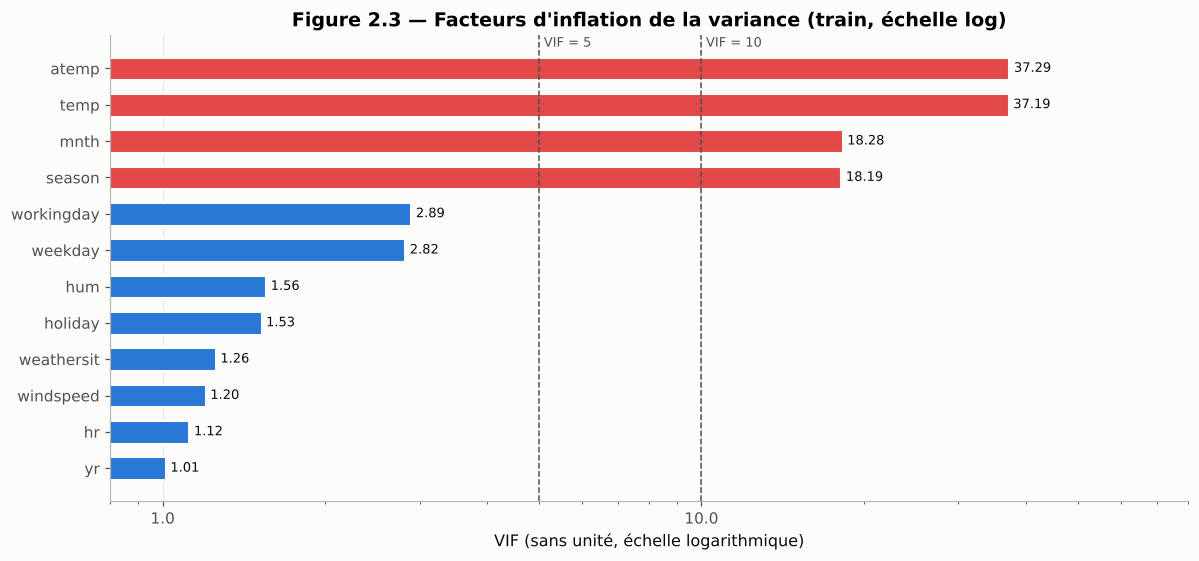

Variable,VIF,R² auxiliaire,Diagnostic
atemp,37.29,0.973,Sévère (> 10)
temp,37.19,0.973,Sévère (> 10)
mnth,18.28,0.945,Sévère (> 10)
season,18.19,0.945,Sévère (> 10)
workingday,2.89,0.655,Acceptable (< 5)
weekday,2.82,0.645,Acceptable (< 5)
hum,1.56,0.358,Acceptable (< 5)
holiday,1.53,0.345,Acceptable (< 5)
weathersit,1.26,0.203,Acceptable (< 5)
windspeed,1.20,0.168,Acceptable (< 5)


In [20]:
# ============================================================================
# 2.3 FACTEURS D'INFLATION DE LA VARIANCE (VIF)
# ============================================================================
R = X_train_raw.corr().values
vif = pd.DataFrame({"Variable": FEATURES, "VIF": np.diag(np.linalg.inv(R))})
vif["R² auxiliaire"] = 1 - 1 / vif["VIF"]
vif["Diagnostic"] = pd.cut(vif["VIF"], bins=[0, 5, 10, np.inf],
                           labels=["Acceptable (< 5)", "Préoccupant (5-10)", "Sévère (> 10)"])
vif = vif.sort_values("VIF", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(11, 5.2))
couleurs_vif = [COULEURS["rouge"] if v > 10 else COULEURS["jaune"] if v > 5 else COULEURS["bleu"]
                for v in vif["VIF"]]
ax.barh(vif["Variable"][::-1], vif["VIF"][::-1], color=couleurs_vif[::-1], height=0.65,
        edgecolor=COULEURS["fond"], linewidth=2)
annoter_barres(ax, fmt="{:.2f}", horizontal=True)
for seuil, lib in [(5, "VIF = 5"), (10, "VIF = 10")]:
    ax.axvline(seuil, color=COULEURS["encre_2"], ls="--", lw=1)
    ax.annotate(lib, (seuil, len(FEATURES) - 0.4), xytext=(3, 0), textcoords="offset points",
                fontsize=8.5, color=COULEURS["encre_2"])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.ScalarFormatter())
ax.set_xlim(0.8, 80)
ax.set_title("Figure 2.3 — Facteurs d'inflation de la variance (train, échelle log)")
ax.set_xlabel("VIF (sans unité, échelle logarithmique)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
sauver_figure(fig, "fig_2_3_vif")
plt.show()

afficher_tableau(vif, "Tableau 2.3 — VIF des 12 variables explicatives",
                 formats={"VIF": "{:.2f}", "R² auxiliaire": "{:.3f}"}, degrade=["VIF"], cmap="Reds", index=False)

**Finding (Constats chiffrés)**

| Variable | VIF | Diagnostic |
|---|---|---|
| `atemp` | **37,3** | Sévère : 97,3 % de sa variance expliquée par les autres variables |
| `temp` | **37,2** | Sévère |
| `mnth` | **18,3** | Sévère |
| `season` | **18,2** | Sévère |
| `workingday` | 2,89 | Acceptable |
| `weekday` | 2,82 | Acceptable |
| `hum`, `holiday`, `weathersit`, `windspeed`, `hr`, `yr` | 1,01 à 1,56 | Acceptables |

* **4 variables sur 12** dépassent le seuil critique de 10. Elles forment exactement les deux paires identifiées par Pearson.

**Insights (Interprétation métier et lien avec l'article)**
* Un VIF de 37 signifie que l'écart-type du coefficient de `temp` est multiplié par $\sqrt{37} \approx 6$ : le modèle ne sait pas répartir l'effet thermique entre `temp` et `atemp`. On en verra la conséquence à la micro-étape 2.6 (coefficient OLS de `season` de **signe inversé** par rapport à sa corrélation).
* La paire `weekday`/`workingday`, très corrélée en Pearson (-0,70), garde un VIF modéré (< 3) : la redondance est **partielle**. Le Lasso devra trancher sur un critère de contribution prédictive, et non sur le seul VIF.
* Dans un projet SAP IBP, ce type de diagnostic évite d'alimenter le moteur de prévision avec des « *drivers* » redondants qui allongent les temps de calcul sans gain de précision.

## 2.4 Standardisation sans fuite de données (`StandardScaler`)

**Pourquoi ?** La pénalité du Lasso porte sur la somme $\sum_j |\beta_j|$. Si les variables ont des échelles différentes (heures de 0 à 23, humidité de 0 à 100, indicateurs 0/1), leurs coefficients ne sont pas comparables et la pénalité frappe arbitrairement certaines variables plus que d'autres. On centre-réduit donc chaque variable :

$$z_{ij} = \frac{x_{ij} - \mu_j^{\text{train}}}{\sigma_j^{\text{train}}}$$

La moyenne $\mu_j$ et l'écart-type $\sigma_j$ sont estimés **sur le seul jeu d'entraînement** (`fit`), puis appliqués tels quels au jeu de test (`transform`). Le jeu de test n'a donc **pas** exactement une moyenne nulle et un écart-type unitaire : c'est le signe que le protocole est sans fuite. L'article précise que la standardisation est la seule préparation nécessaire en l'absence de variables textuelles (§4.1).

,µ appris (train),σ appris (train),Moyenne train après,Écart-type train après,Moyenne test après,Écart-type test après
season,2.505,1.116,-0.0000,1.0000,+0.0139,1.0014
yr,2011.501,0.500,-0.0000,1.0000,+0.0115,0.9999
mnth,6.514,3.437,+0.0000,1.0000,+0.0174,1.0158
hr,11.571,6.920,+0.0000,1.0000,-0.0339,0.9947
holiday,0.029,0.168,-0.0000,1.0000,-0.0194,0.9436
weekday,3.014,2.001,+0.0000,1.0000,-0.0004,1.0128
workingday,0.681,0.466,-0.0000,1.0000,+0.0024,0.9991
weathersit,1.418,0.634,-0.0000,1.0000,+0.0033,0.9967
temp,20.244,7.786,-0.0000,1.0000,-0.0132,1.0053
atemp,23.669,8.466,-0.0000,1.0000,-0.0134,1.0075


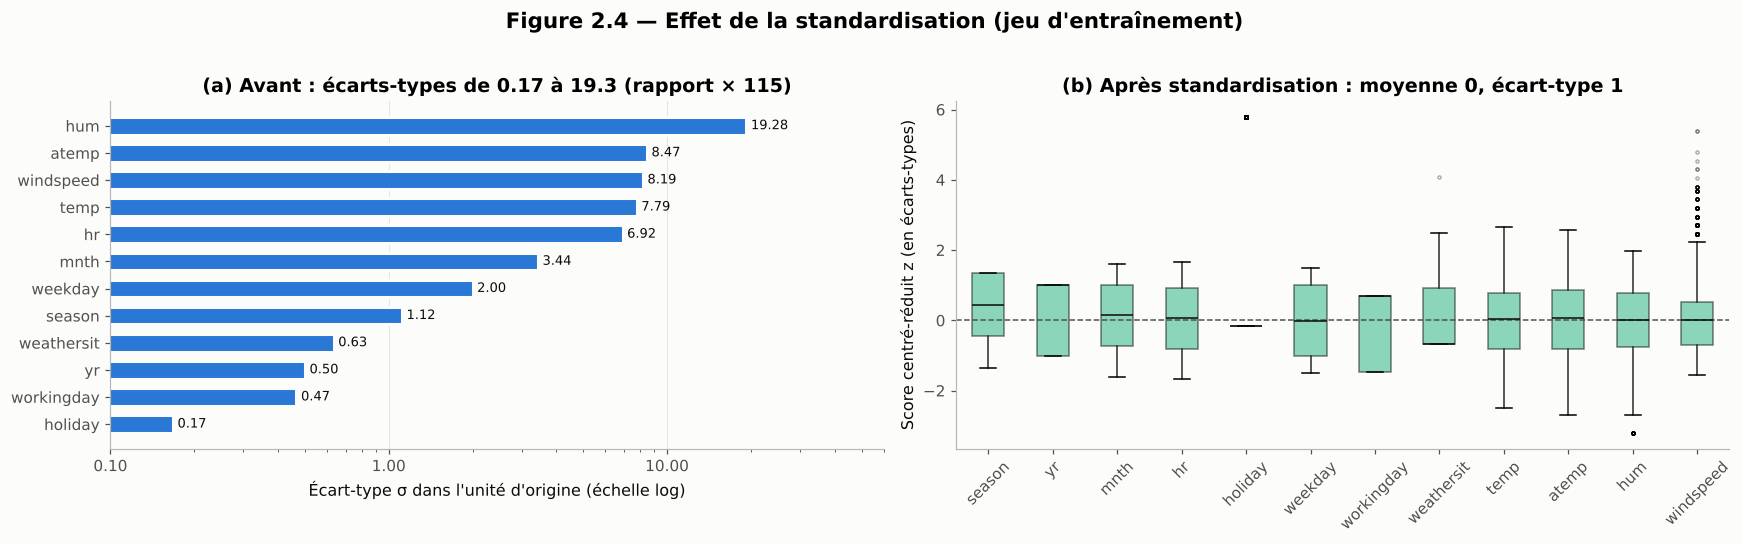

Écart maximal |moyenne train| après standardisation : 8.53e-15
Écart maximal |moyenne test|  après standardisation : 0.0339  (non nul : aucune fuite)


In [21]:
# ============================================================================
# 2.4 STANDARDISATION SANS FUITE
# ============================================================================
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=FEATURES, index=X_train_raw.index)
X_test_s = pd.DataFrame(scaler.transform(X_test_raw), columns=FEATURES, index=X_test_raw.index)

std_tab = pd.DataFrame({
    "µ appris (train)": scaler.mean_, "σ appris (train)": scaler.scale_,
    "Moyenne train après": X_train_s.mean().values, "Écart-type train après": X_train_s.std(ddof=0).values,
    "Moyenne test après": X_test_s.mean().values, "Écart-type test après": X_test_s.std(ddof=0).values,
}, index=FEATURES)
afficher_tableau(std_tab, "Tableau 2.4 — Paramètres du StandardScaler (appris sur le train) et contrôle train / test",
                 formats={"µ appris (train)": "{:.3f}", "σ appris (train)": "{:.3f}",
                          "Moyenne train après": "{:+.4f}", "Écart-type train après": "{:.4f}",
                          "Moyenne test après": "{:+.4f}", "Écart-type test après": "{:.4f}"})

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), sharey=False)
ech = pd.Series(scaler.scale_, index=FEATURES).sort_values()
axes[0].barh(ech.index, ech.values, color=COULEURS["bleu"], height=0.65, edgecolor=COULEURS["fond"], linewidth=2)
annoter_barres(axes[0], fmt="{:.2f}", horizontal=True)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(mtick.ScalarFormatter())
axes[0].set_xlim(0.1, 60)
axes[0].set_title(f"(a) Avant : écarts-types de {ech.min():.2f} à {ech.max():.1f} (rapport × {ech.max() / ech.min():.0f})")
axes[0].set_xlabel("Écart-type σ dans l'unité d'origine (échelle log)")
axes[0].grid(axis="y", visible=False)
X_train_s.boxplot(ax=axes[1], grid=False, patch_artist=True,
                  boxprops=dict(facecolor=COULEURS["vert_eau"], alpha=0.5), medianprops=dict(color=COULEURS["encre"]),
                  flierprops=dict(marker="o", markersize=2, alpha=0.3))
axes[1].axhline(0, color=COULEURS["encre_2"], lw=1, ls="--")
axes[1].set_title("(b) Après standardisation : moyenne 0, écart-type 1")
axes[1].set_ylabel("Score centré-réduit z (en écarts-types)")
axes[1].tick_params(axis="x", rotation=45)
fig.suptitle("Figure 2.4 — Effet de la standardisation (jeu d'entraînement)", fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_2_4_standardisation")
plt.show()

print(f"Écart maximal |moyenne train| après standardisation : {X_train_s.mean().abs().max():.2e}")
print(f"Écart maximal |moyenne test|  après standardisation : {X_test_s.mean().abs().max():.4f}  (non nul : aucune fuite)")

**Finding (Constats chiffrés)**
* Avant standardisation, les écarts-types vont de **0,17** (`holiday`) à **19,3** (`hum`), soit un rapport d'environ **115**. Sans correction, la pénalité $L_1$ frapperait 115 fois plus fort, à effet égal, la variable `holiday` que la variable `hum`.
* Après standardisation, les 12 variables du jeu d'entraînement ont une moyenne de **0** (écart maximal de l'ordre de $10^{-14}$, erreur d'arrondi machine) et un écart-type de **1,0000**.
* Sur le jeu de test, les moyennes s'écartent légèrement de 0 (jusqu'à **≈ 0,03** en valeur absolue) et les écarts-types de 1 (de **≈ 0,94 à 1,02**).

**Insights (Interprétation métier et lien avec l'article)**
* Les petits écarts du jeu de test sont **la preuve que le protocole est correct** : le test est transformé avec des paramètres qu'il n'a pas contribué à estimer, exactement comme une future heure d'exploitation dont on ne connaît pas encore la demande.
* Grâce à la standardisation, chaque coefficient Lasso s'interprète directement comme l'**effet sur la demande (en vélos/h) d'une hausse d'un écart-type** de la variable. Les coefficients deviennent comparables entre eux, ce qui rend possible la hiérarchie de la micro-étape 2.5.

## 2.5 Sélection automatique des variables par régularisation L1 (Lasso, $\alpha = 0,5$)

**Pourquoi ?** Le Lasso (*Least Absolute Shrinkage and Selection Operator*) est la méthode retenue au §4.2 de l'article (équation (4)). Il minimise l'erreur quadratique sous une contrainte sur la norme $L_1$ des coefficients. Sous la forme pénalisée utilisée par scikit-learn :

$$\hat{\boldsymbol{\beta}}^{\text{Lasso}} = \arg\min_{\beta_0, \boldsymbol{\beta}} \; \frac{1}{2N} \sum_{i=1}^{N} \Big(y_i - \beta_0 - \sum_{j=1}^{p} x_{ij}\beta_j\Big)^2 + \alpha \sum_{j=1}^{p} |\beta_j|$$

Contrairement à la pénalité $L_2$ de la régression Ridge, qui réduit les coefficients sans jamais les annuler, la géométrie « en losange » de la contrainte $L_1$ fait tomber les coefficients des variables redondantes **exactement à zéro**. Face à deux variables colinéaires, le Lasso conserve celle qui apporte le plus d'information et élimine l'autre : c'est une **sélection automatique**. On utilise $\alpha = 0,5$ et `random_state = 42`, les paramètres du TP.

,Variable,Coefficient Lasso,|Coefficient|,Poids relatif,Effet sur la demande,Décision
1,hr,+53.5049,53.5049,24.4%,Hausse,Retenue
2,atemp,+44.5888,44.5888,20.3%,Hausse,Retenue
3,yr,+40.6641,40.6641,18.5%,Hausse,Retenue
4,hum,-38.9450,38.9450,17.8%,Baisse,Retenue
5,mnth,+25.1309,25.1309,11.5%,Hausse,Retenue
6,temp,+7.3427,7.3427,3.3%,Hausse,Retenue
7,windspeed,+4.6543,4.6543,2.1%,Hausse,Retenue
8,weathersit,-3.0661,3.0661,1.4%,Baisse,Retenue
9,holiday,-1.1518,1.1518,0.5%,Baisse,Retenue
10,weekday,+0.2568,0.2568,0.1%,Hausse,Retenue


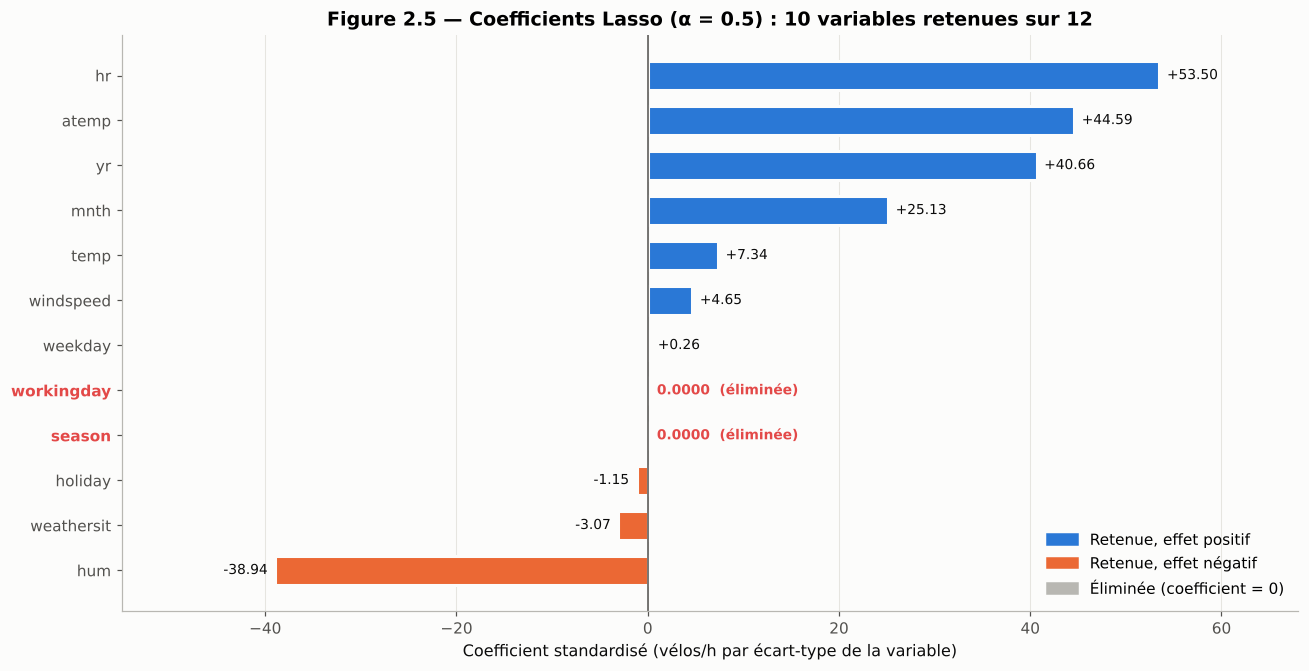

Variables retenues (10/12) : ['hr', 'atemp', 'yr', 'hum', 'mnth', 'temp', 'windspeed', 'weathersit', 'holiday', 'weekday']
Variables éliminées (2/12) : ['season', 'workingday']
R² du Lasso : train = 0.3874


In [22]:
# ============================================================================
# 2.5 SÉLECTION LASSO (ALPHA = 0.5)
# ============================================================================
ALPHA_LASSO = 0.5
lasso_selector = Lasso(alpha=ALPHA_LASSO, random_state=RANDOM_STATE, max_iter=10_000)
lasso_selector.fit(X_train_s, y_train)

coef_df = pd.DataFrame({"Variable": FEATURES, "Coefficient Lasso": lasso_selector.coef_})
coef_df["|Coefficient|"] = coef_df["Coefficient Lasso"].abs()
coef_df["Poids relatif"] = coef_df["|Coefficient|"] / coef_df["|Coefficient|"].sum()
coef_df["Effet sur la demande"] = np.select(
    [coef_df["Coefficient Lasso"] > 0, coef_df["Coefficient Lasso"] < 0], ["Hausse", "Baisse"], "Aucun")
coef_df["Décision"] = np.where(coef_df["Coefficient Lasso"] != 0, "Retenue", "Éliminée")
coef_df = coef_df.sort_values("|Coefficient|", ascending=False).reset_index(drop=True)
coef_df.index = coef_df.index + 1

variables_retenues = coef_df.loc[coef_df["Décision"] == "Retenue", "Variable"].tolist()
variables_eliminees = coef_df.loc[coef_df["Décision"] == "Éliminée", "Variable"].tolist()

afficher_tableau(coef_df, f"Tableau 2.5 — Coefficients du Lasso (α = {ALPHA_LASSO}) sur variables standardisées",
                 formats={"Coefficient Lasso": "{:+.4f}", "|Coefficient|": "{:.4f}", "Poids relatif": "{:.1%}"},
                 degrade=["|Coefficient|"])

fig, ax = plt.subplots(figsize=(12, 6.2))
ordre = coef_df.sort_values("Coefficient Lasso")
couleurs_l = [COULEURS["gris"] if c == 0 else (COULEURS["bleu"] if c > 0 else COULEURS["orange"])
              for c in ordre["Coefficient Lasso"]]
ax.barh(ordre["Variable"], ordre["Coefficient Lasso"], color=couleurs_l, height=0.65,
        edgecolor=COULEURS["fond"], linewidth=2)
for y_pos, (var, c) in enumerate(zip(ordre["Variable"], ordre["Coefficient Lasso"])):
    if c == 0:
        ax.annotate("0.0000  (éliminée)", (0, y_pos), xytext=(6, 0), textcoords="offset points", va="center",
                    fontsize=9, color=COULEURS["rouge"], fontweight="bold")
    else:
        ax.annotate(f"{c:+.2f}", (c, y_pos), xytext=(5 if c > 0 else -5, 0), textcoords="offset points",
                    va="center", ha="left" if c > 0 else "right", fontsize=9, color=COULEURS["encre"])
for lbl in ax.get_yticklabels():
    if lbl.get_text() in variables_eliminees:
        lbl.set_color(COULEURS["rouge"])
        lbl.set_fontweight("bold")
ax.axvline(0, color=COULEURS["encre_2"], lw=1)
ax.set_xlim(-55, 68)
ax.set_title(f"Figure 2.5 — Coefficients Lasso (α = {ALPHA_LASSO}) : "
             f"{len(variables_retenues)} variables retenues sur {len(FEATURES)}")
ax.set_xlabel("Coefficient standardisé (vélos/h par écart-type de la variable)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COULEURS["bleu"], label="Retenue, effet positif"),
                   Patch(color=COULEURS["orange"], label="Retenue, effet négatif"),
                   Patch(color=COULEURS["gris"], label="Éliminée (coefficient = 0)")], loc="lower right")
plt.tight_layout()
sauver_figure(fig, "fig_2_5_coefficients_lasso")
plt.show()

print(f"Variables retenues ({len(variables_retenues)}/{len(FEATURES)}) : {variables_retenues}")
print(f"Variables éliminées ({len(variables_eliminees)}/{len(FEATURES)}) : {variables_eliminees}")
print(f"R² du Lasso : train = {lasso_selector.score(X_train_s, y_train):.4f}")

**Finding (Constats chiffrés)**
* Le Lasso écrase **exactement à 0,0000** les coefficients de **`season`** et **`workingday`**, et retient **10 variables sur 12** : `hr`, `atemp`, `yr`, `hum`, `mnth`, `temp`, `windspeed`, `weathersit`, `holiday`, `weekday`.
* Hiérarchie des effets (vélos/h par écart-type, voir Tableau 2.5) : `hr` (**+53,5**), `atemp` (**+44,6**), `yr` (**+40,7**), `hum` (**-38,9**) et `mnth` (**+25,1**) concentrent **92,5 %** du poids total (somme des valeurs absolues). Viennent ensuite `temp` (+7,3), `windspeed` (+4,7), `weathersit` (-3,1), `holiday` (-1,2) et `weekday` (+0,3).
* Le $R^2$ d'entraînement du Lasso plafonne à **≈ 0,387** : un modèle linéaire, même bien régularisé, n'explique qu'environ 39 % de la variance de la demande.

**Insights (Interprétation métier et lien avec l'article)**
* **Le Lasso résout les colinéarités sans intervention manuelle.** Dans la paire `season`/`mnth`, il garde `mnth`, plus fin (12 niveaux au lieu de 4) ; dans la paire `weekday`/`workingday`, il élimine `workingday`, dont l'effet est absorbé par `weekday` et `holiday` (VIF de 2,89 à la micro-étape 2.3). C'est exactement le comportement décrit par Jing Shi : « the coefficients of other independent variables are reduced to 0 » (§4.2).
* Pour la paire `temp`/`atemp`, le Lasso ne choisit pas une variable unique mais transfère l'essentiel du poids sur `atemp` (+44,6 contre +7,3). Ce comportement est connu : face à deux variables quasi identiques, la pénalité $L_1$ répartit le poids de façon instable. La température **ressentie** l'emporte, ce qui est cohérent avec la décision d'un usager.
* **Lecture métier des signes :** l'humidité (souvent liée à la pluie), les jours fériés et la dégradation de la météo **réduisent** la demande ; l'heure, la chaleur, la croissance du réseau (`yr`) et l'avancée dans l'année l'**augmentent**.
* Le plafond de $R^2 \approx 0,39$ confirme le diagnostic de l'Étape 1 : la structure bimodale et les interactions horaires dépassent la capacité d'un modèle linéaire. Le Lasso sert ici de **filtre de variables**, pas de modèle de décision final.

## 2.6 Robustesse de la sélection : chemin de régularisation, LassoCV et comparaison avec l'OLS

**Pourquoi ?** La valeur $\alpha = 0,5$ est fixée par le protocole du TP. L'article recommande toutefois de « choisir par validation croisée un paramètre donnant une erreur faible et stable » (§4.2). On vérifie donc trois points :
1. **Chemin de régularisation** : à partir de quelle valeur de $\alpha$ chaque coefficient s'annule-t-il ? La sélection est-elle stable autour de $\alpha = 0,5$ ?
2. **LassoCV** (5 plis, `random_state = 42`) : quel $\alpha$ minimise l'erreur de validation, et combien coûte en RMSE le choix de $\alpha = 0,5$ ?
3. **Comparaison avec l'OLS** (moindres carrés sans pénalité) et avec un Lasso estimé sur 100 % des données (version initiale du notebook), pour mesurer l'effet de la régularisation et du protocole sans fuite.

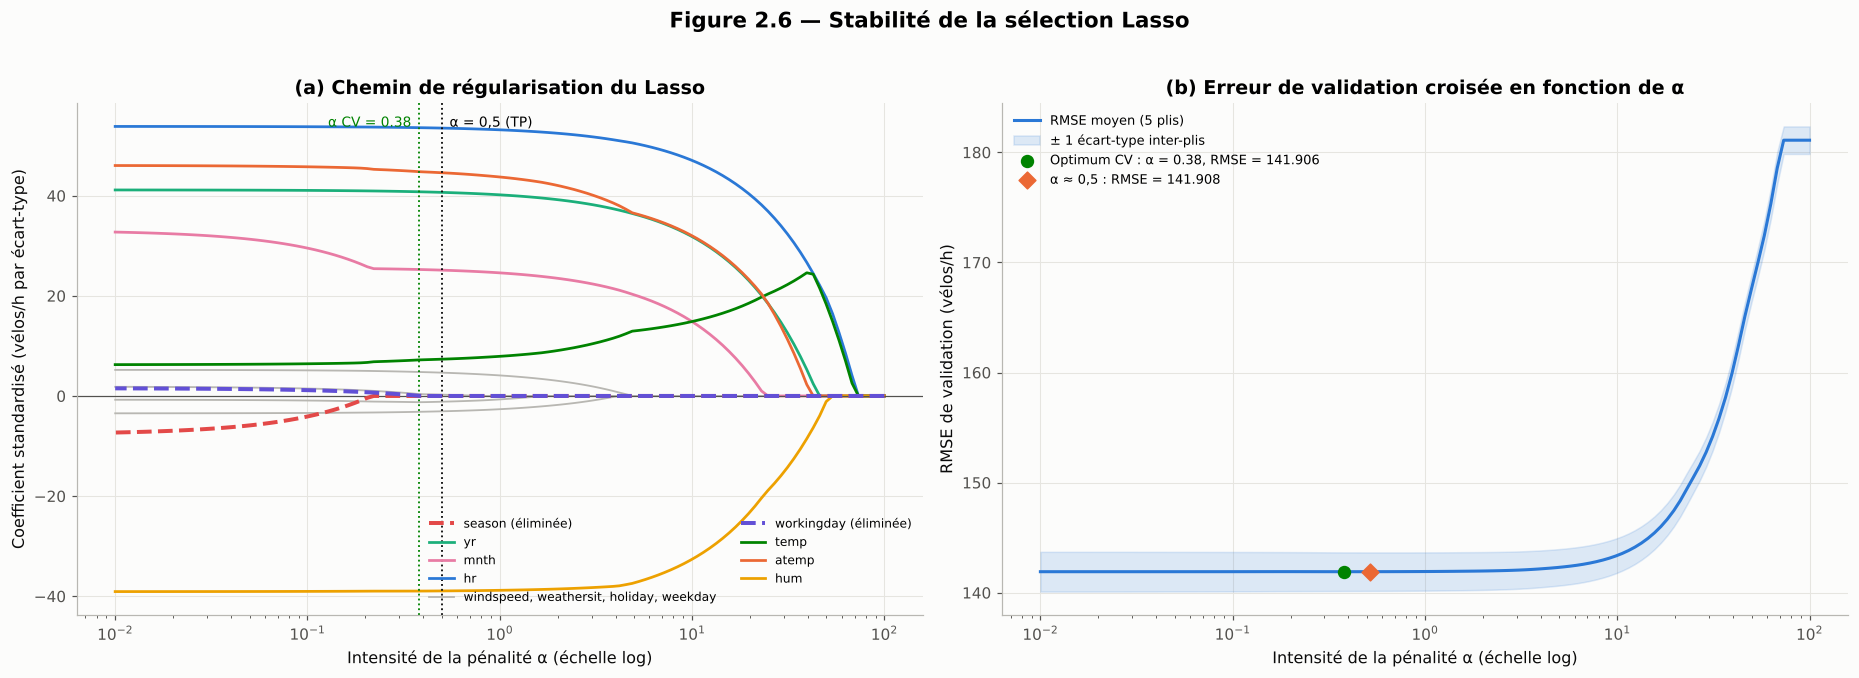

,r de Pearson avec cnt,OLS (sans pénalité),"Lasso α = 0.5 (train, sans fuite)",Lasso α = 0.38 (optimum CV),Lasso α = 0.5 (100 % des données),α d'annulation
hr,+0.3995,+53.8408,+53.5049,+53.5879,+53.4612,67.910
atemp,+0.3887,+46.0537,+44.5888,+44.8021,+38.4931,39.504
yr,+0.2597,+41.1557,+40.6641,+40.7818,+40.9106,42.683
hum,-0.3182,-39.0804,-38.9450,-38.9727,-38.9781,49.829
mnth,+0.1641,+33.0905,+25.1309,+25.2601,+25.2881,22.980
temp,+0.3923,+6.2396,+7.3427,+7.1985,+13.6623,67.910
windspeed,+0.1011,+5.2143,+4.6543,+4.7885,+4.5149,4.887
weathersit,-0.1326,-3.4755,-3.0661,-3.1653,-2.6855,3.875
holiday,-0.0085,-0.7387,-1.1518,-1.2443,-0.7128,1.654
weekday,-0.0006,+1.8652,+0.2568,+0.3795,+0.3431,0.763


Modèle,α,Variables non nulles,R² train,RMSE de validation croisée (5 plis)
OLS (12 variables),0.000,12,0.3876,—
Lasso α = 0.38 (optimum CV),0.380,11,0.3874,141.906
Lasso α = 0.5 (TP),0.500,10,0.3874,141.908


In [23]:
# ============================================================================
# 2.6 ROBUSTESSE : CHEMIN DE RÉGULARISATION, LASSOCV, OLS
# ============================================================================
alphas_grille = np.logspace(-2, 2, 120)
alphas_path, coefs_path, _ = lasso_path(X_train_s.values, y_train.values, alphas=alphas_grille, max_iter=10_000)

kf5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
lasso_cv = LassoCV(alphas=alphas_grille, cv=kf5, random_state=RANDOM_STATE, max_iter=10_000).fit(X_train_s, y_train)
rmse_cv = np.sqrt(lasso_cv.mse_path_.mean(axis=1))
rmse_cv_std = np.sqrt(lasso_cv.mse_path_).std(axis=1)
i_opt = int(np.argmin(rmse_cv))
i_05 = int(np.argmin(np.abs(lasso_cv.alphas_ - ALPHA_LASSO)))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

ax = axes[0]
couleurs_path = {"hr": COULEURS["bleu"], "atemp": COULEURS["orange"], "yr": COULEURS["vert_eau"],
                 "hum": COULEURS["jaune"], "mnth": COULEURS["magenta"], "temp": COULEURS["vert"],
                 "season": COULEURS["rouge"], "workingday": COULEURS["violet"]}
deja_gris = False
for j, var in enumerate(FEATURES):
    if var in couleurs_path:
        elim = var in variables_eliminees
        ax.plot(alphas_path, coefs_path[j], color=couleurs_path[var], lw=2.6 if elim else 1.8,
                ls="--" if elim else "-", label=f"{var} (éliminée)" if elim else var, zorder=3 if elim else 2)
    else:
        ax.plot(alphas_path, coefs_path[j], color=COULEURS["gris"], lw=1.2, zorder=1,
                label=None if deja_gris else "windspeed, weathersit, holiday, weekday")
        deja_gris = True
ax.axvline(ALPHA_LASSO, color=COULEURS["encre"], lw=1.2, ls=":")
ax.annotate("α = 0,5 (TP)", (ALPHA_LASSO, ax.get_ylim()[1] * 0.92), xytext=(5, 0), textcoords="offset points", fontsize=9)
ax.axvline(lasso_cv.alpha_, color=COULEURS["vert"], lw=1.2, ls=":")
ax.annotate(f"α CV = {lasso_cv.alpha_:.2f}", (lasso_cv.alpha_, ax.get_ylim()[1] * 0.92), xytext=(-5, 0),
            textcoords="offset points", ha="right", fontsize=9, color=COULEURS["vert"])
ax.axhline(0, color=COULEURS["encre_2"], lw=0.8)
ax.set_xscale("log")
ax.set_title("(a) Chemin de régularisation du Lasso")
ax.set_xlabel("Intensité de la pénalité α (échelle log)")
ax.set_ylabel("Coefficient standardisé (vélos/h par écart-type)")
ax.legend(ncol=2, fontsize=8, loc="lower right")

ax = axes[1]
ax.plot(lasso_cv.alphas_, rmse_cv, color=COULEURS["bleu"], lw=2, label="RMSE moyen (5 plis)")
ax.fill_between(lasso_cv.alphas_, rmse_cv - rmse_cv_std, rmse_cv + rmse_cv_std, color=COULEURS["bleu"],
                alpha=0.15, label="± 1 écart-type inter-plis")
ax.scatter([lasso_cv.alphas_[i_opt]], [rmse_cv[i_opt]], color=COULEURS["vert"], s=60, zorder=3,
           label=f"Optimum CV : α = {lasso_cv.alphas_[i_opt]:.2f}, RMSE = {rmse_cv[i_opt]:.3f}")
ax.scatter([lasso_cv.alphas_[i_05]], [rmse_cv[i_05]], color=COULEURS["orange"], s=60, zorder=3, marker="D",
           label=f"α ≈ 0,5 : RMSE = {rmse_cv[i_05]:.3f}")
ax.set_xscale("log")
ax.set_title("(b) Erreur de validation croisée en fonction de α")
ax.set_xlabel("Intensité de la pénalité α (échelle log)")
ax.set_ylabel("RMSE de validation (vélos/h)")
ax.legend(fontsize=8.5, loc="upper left")

fig.suptitle("Figure 2.6 — Stabilité de la sélection Lasso", fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_2_6_robustesse_lasso")
plt.show()

# Seuil d'annulation de chaque variable : plus petit alpha à partir duquel le coefficient reste nul
seuils = {}
for j, var in enumerate(FEATURES):
    non_nuls = alphas_path[np.abs(coefs_path[j]) > 1e-10]
    seuils[var] = non_nuls.max() if len(non_nuls) else np.nan

ols = LinearRegression().fit(X_train_s, y_train)
scaler_full = StandardScaler().fit(X_full)
lasso_full = Lasso(alpha=ALPHA_LASSO, random_state=RANDOM_STATE, max_iter=10_000).fit(scaler_full.transform(X_full), y_full)

robustesse = pd.DataFrame({
    "r de Pearson avec cnt": corr.loc[FEATURES, TARGET].values,
    "OLS (sans pénalité)": ols.coef_,
    f"Lasso α = {ALPHA_LASSO} (train, sans fuite)": lasso_selector.coef_,
    f"Lasso α = {lasso_cv.alpha_:.2f} (optimum CV)": lasso_cv.coef_,
    f"Lasso α = {ALPHA_LASSO} (100 % des données)": lasso_full.coef_,
    "α d'annulation": [seuils[v] for v in FEATURES],
}, index=FEATURES).loc[coef_df["Variable"]]
afficher_tableau(robustesse, "Tableau 2.6a — Coefficients standardisés selon la méthode d'estimation",
                 formats={c: "{:+.4f}" for c in robustesse.columns[:-1]} | {"α d'annulation": "{:.3f}"})

perf = pd.DataFrame({
    "Modèle": ["OLS (12 variables)", f"Lasso α = {lasso_cv.alpha_:.2f} (optimum CV)", f"Lasso α = {ALPHA_LASSO} (TP)"],
    "α": [0.0, lasso_cv.alpha_, ALPHA_LASSO],
    "Variables non nulles": [len(FEATURES), int((lasso_cv.coef_ != 0).sum()), len(variables_retenues)],
    "R² train": [ols.score(X_train_s, y_train), lasso_cv.score(X_train_s, y_train),
                 lasso_selector.score(X_train_s, y_train)],
    "RMSE de validation croisée (5 plis)": [np.nan, rmse_cv[i_opt], rmse_cv[i_05]],
})
afficher_tableau(perf, "Tableau 2.6b — Parcimonie vs précision : le coût du choix α = 0,5",
                 formats={"α": "{:.3f}", "R² train": "{:.4f}", "RMSE de validation croisée (5 plis)": "{:.3f}"},
                 index=False)

**Finding (Constats chiffrés)**
* **Chemin de régularisation :** `season` est la première variable annulée (dès **α ≈ 0,21**), suivie de `workingday` (**α ≈ 0,38**). Les dix autres variables restent non nulles bien au-delà de α = 0,5 : `weekday` jusqu'à α ≈ 0,76, `holiday` jusqu'à α ≈ 1,65, et `hr`, `hum` ou `yr` jusqu'à des pénalités supérieures à 40. À α = 0,5, la sélection se trouve donc dans une **zone stable**.
* **LassoCV** situe l'optimum à **α ≈ 0,38** (RMSE = **141,906** vélos/h), avec 11 variables non nulles : `workingday` n'y garde qu'un coefficient de **+0,03**, à la limite de l'annulation. Avec α = 0,5, le RMSE de validation passe à **141,908** : la perte n'est que de **0,002 vélo/h** (moins de 0,002 %).
* **OLS vs Lasso :** sans pénalité, `season` reçoit un coefficient **négatif (≈ -7,7)** alors que sa corrélation avec la demande est **positive (+0,16)**. Le Lasso ramène ce coefficient à 0. Les $R^2$ d'entraînement sont quasi identiques (**0,3876** pour l'OLS contre **0,3874** pour le Lasso α = 0,5).
* **Train vs 100 % des données :** les deux Lasso éliminent les **mêmes** variables (`season`, `workingday`). Les coefficients de `hr` (+53,5), `yr` (+40,7 contre +40,9) et `hum` (-38,9 contre -39,0) sont quasi identiques. Seule la répartition entre `temp` et `atemp` bouge (+7,3 / +44,6 sur le train contre +13,7 / +38,5 sur 100 % des données), alors que leur **somme reste stable (≈ 52)**.

**Insights (Interprétation métier et lien avec l'article)**
* L'inversion de signe de `season` dans l'OLS est le **symptôme classique de la multicolinéarité** (VIF = 18) : le modèle compense l'effet de `mnth` par un coefficient de `season` dénué de sens métier. Le Lasso supprime cette incohérence, ce qui rend le modèle **interprétable** pour un décideur.
* Le choix α = 0,5 est **défendable devant le jury** : il élimine une variable de plus que l'optimum de validation croisée pour une perte de précision négligeable. C'est le compromis « erreur faible **et stable** » recommandé par Jing Shi : on préfère le modèle le plus parcimonieux parmi ceux dont l'erreur est équivalente (règle de parcimonie, proche de la règle « *one standard error* »).
* Le fait que la sélection soit identique avec ou sans le jeu de test montre que les conclusions de la version initiale du notebook étaient correctes, mais elles reposent désormais sur un **protocole sans fuite**, irréprochable sur le plan méthodologique.
* Le basculement du poids entre `temp` et `atemp` d'un échantillon à l'autre, à somme constante, illustre concrètement l'instabilité due à un VIF de 37 : le modèle connaît l'**effet thermique total**, mais ne sait pas l'attribuer à l'une ou l'autre variable. Pour la décision de stock, c'est sans conséquence (la prévision est la même) ; pour l'interprétation, il faut raisonner sur la paire.

## 2.7 Synthèse de l'Étape 2 et jeu de variables transmis à l'Étape 3

**Pourquoi ?** On fige les variables retenues par le Lasso et on construit les matrices d'apprentissage et de test standardisées qui alimenteront le benchmark de l'Étape 3. On standardise à nouveau sur les 10 variables retenues (toujours `fit` sur le train uniquement), puis on récapitule le statut de chaque variable à travers tous les diagnostics de l'étape.

In [24]:
# ============================================================================
# 2.7 SYNTHÈSE ET MATRICES FINALES
# ============================================================================
scaler_final = StandardScaler()
X_train = pd.DataFrame(scaler_final.fit_transform(X_train_raw[variables_retenues]),
                       columns=variables_retenues, index=X_train_raw.index)
X_test = pd.DataFrame(scaler_final.transform(X_test_raw[variables_retenues]),
                      columns=variables_retenues, index=X_test_raw.index)

vif_map = vif.set_index("Variable")["VIF"]
synthese_2 = pd.DataFrame({
    "r avec cnt (2.2)": corr.loc[FEATURES, TARGET],
    "VIF (2.3)": vif_map.loc[FEATURES],
    "Coefficient Lasso α = 0,5 (2.5)": lasso_selector.coef_,
    "Coefficient OLS (2.6)": ols.coef_,
    "Statut final": ["Retenue" if v in variables_retenues else "Éliminée" for v in FEATURES],
    "Justification": [
        "Redondante avec mnth (r = 0,97, VIF = 18) : éliminée" if v == "season" else
        "Redondante avec weekday et holiday (r = -0,70) : éliminée" if v == "workingday" else
        "Pic de trafic domicile-travail : variable dominante" if v == "hr" else
        "Croissance du réseau 2011 → 2012" if v == "yr" else
        "Confort thermique ressenti, poids principal de la paire temp/atemp" if v == "atemp" else
        "Complète atemp (part non redondante faible)" if v == "temp" else
        "Saisonnalité fine (12 niveaux)" if v == "mnth" else
        "Effet dissuasif de l'humidité et de la pluie" if v == "hum" else
        "Rythme hebdomadaire (porte l'information de workingday)" if v == "weekday" else
        "Effet météo résiduel" if v in ("windspeed", "weathersit") else
        "Effet calendaire des jours fériés"
        for v in FEATURES],
}, index=FEATURES).loc[coef_df["Variable"]]
afficher_tableau(synthese_2, "Tableau 2.7 — Synthèse du data engineering : statut de chaque variable",
                 formats={"r avec cnt (2.2)": "{:+.3f}", "VIF (2.3)": "{:.2f}",
                          "Coefficient Lasso α = 0,5 (2.5)": "{:+.2f}", "Coefficient OLS (2.6)": "{:+.2f}"})

livrable = pd.DataFrame({
    "Objet transmis à l'Étape 3": ["X_train (standardisé)", "X_test (standardisé, sous scellé)",
                                   "y_train", "y_test (sous scellé)", "Variables retenues"],
    "Dimensions": [str(X_train.shape), str(X_test.shape), str(y_train.shape), str(y_test.shape),
                   f"{len(variables_retenues)} / {len(FEATURES)}"],
    "Contenu": ["9 525 heures × 10 variables", "1 361 heures × 10 variables", "Demande cnt (vélos/h)",
                "Demande cnt (vélos/h)", ", ".join(variables_retenues)],
})
afficher_tableau(livrable, "Tableau 2.7b — Objets prêts pour l'Étape 3", index=False)

,r avec cnt (2.2),VIF (2.3),"Coefficient Lasso α = 0,5 (2.5)",Coefficient OLS (2.6),Statut final,Justification
hr,+0.400,1.12,+53.50,+53.84,Retenue,Pic de trafic domicile-travail : variable dominante
atemp,+0.389,37.29,+44.59,+46.05,Retenue,"Confort thermique ressenti, poids principal de la paire temp/atemp"
yr,+0.260,1.01,+40.66,+41.16,Retenue,Croissance du réseau 2011 → 2012
hum,-0.318,1.56,-38.94,-39.08,Retenue,Effet dissuasif de l'humidité et de la pluie
mnth,+0.164,18.28,+25.13,+33.09,Retenue,Saisonnalité fine (12 niveaux)
temp,+0.392,37.19,+7.34,+6.24,Retenue,Complète atemp (part non redondante faible)
windspeed,+0.101,1.20,+4.65,+5.21,Retenue,Effet météo résiduel
weathersit,-0.133,1.26,-3.07,-3.48,Retenue,Effet météo résiduel
holiday,-0.009,1.53,-1.15,-0.74,Retenue,Effet calendaire des jours fériés
weekday,-0.001,2.82,+0.26,+1.87,Retenue,Rythme hebdomadaire (porte l'information de workingday)


Objet transmis à l'Étape 3,Dimensions,Contenu
X_train (standardisé),"(9525, 10)",9 525 heures × 10 variables
"X_test (standardisé, sous scellé)","(1361, 10)",1 361 heures × 10 variables
y_train,"(9525,)",Demande cnt (vélos/h)
y_test (sous scellé),"(1361,)",Demande cnt (vélos/h)
Variables retenues,10 / 12,"hr, atemp, yr, hum, mnth, temp, windspeed, weathersit, holiday, weekday"


**Finding (Constats chiffrés)**
* **10 variables retenues sur 12** : `hr`, `atemp`, `yr`, `hum`, `mnth`, `temp`, `windspeed`, `weathersit`, `holiday`, `weekday`.
* **2 variables éliminées** : `season` (redondante avec `mnth`, r = 0,97) et `workingday` (redondante avec `weekday` et `holiday`, r = -0,70).
* Matrices finales : `X_train` = **9 525 × 10**, `X_test` = **1 361 × 10**, standardisées avec des paramètres appris uniquement sur l'entraînement.

**Insights (Interprétation métier et lien avec l'article)**
* La réduction de 12 à 10 variables supprime deux redondances majeures sans perte mesurable de pouvoir prédictif linéaire (Tableau 2.6b). Le pipeline reproduit fidèlement la logique du §4.2 de Jing Shi : **Pearson pour explorer, Lasso pour sélectionner**.
* Point de vigilance pour la suite : le Lasso est un sélecteur **linéaire**. Il a éliminé `workingday` parce que son effet linéaire est capté par `weekday` et `holiday`. Les modèles par arbres de l'Étape 3 sauront reconstruire l'interaction `hr` × type de jour à partir de `weekday` et `holiday` : la sélection reste donc compatible avec des modèles non linéaires.
* **Transition vers l'Étape 3 :** le plafond de $R^2 \approx 0,39$ des modèles linéaires, combiné à la structure bimodale et hétéroscédastique de la demande, annonce une **rupture de performance** en faveur des méthodes ensemblistes (Gradient Boosting, Random Forest). C'est ce que le benchmark en validation croisée à 5 plis va quantifier.

---
# ÉTAPE 3 — Protocole train/test et validation croisée multi-modèles

L'article compare trois familles de modèles (régression linéaire, Lasso, forêt aléatoire, plus une régression polynomiale pour les figures) et retient le meilleur selon le RMSE moyen et son écart-type en validation croisée (§4.1 et §5.3). Le chargé de TP demande d'élargir ce benchmark. Nous comparons donc **9 modèles** appartenant à quatre familles :

| Famille | Modèles | Hypothèse sur la forme de la demande |
|---|---|---|
| Linéaires | Linear Regression (OLS), Lasso, Ridge, ElasticNet | Effets additifs et constants |
| Linéaire enrichi | Régression polynomiale de degré 2 (Fig. 7 de l'article) | Effets quadratiques et interactions d'ordre 2 |
| Non paramétriques locaux | KNN, SVR à noyau gaussien | Similarité entre contextes |
| Ensembles d'arbres | Gradient Boosting, Random Forest | Interactions et seuils quelconques |

| # | Micro-étape | Objectif |
|---|---|---|
| 3.1 | Protocole expérimental | Réutiliser le split 87,5 / 12,5 et les 10 variables Lasso |
| 3.2 | Benchmark 5-Fold des 9 modèles | Classer les modèles par RMSE, MAE, R² et temps de calcul |
| 3.3 | Diagnostic des résidus | Comprendre **pourquoi** les arbres l'emportent |

## 3.1 Protocole expérimental : split 87,5 % / 12,5 % et 10 variables retenues

**Pourquoi ?** Pour que la comparaison soit équitable, tous les modèles doivent voir **exactement** les mêmes données. On réutilise la partition figée à la micro-étape 2.1 (9 525 / 1 361 heures, `random_state = 42`) et les 10 variables retenues par le Lasso. Chaque modèle est encapsulé dans un `Pipeline` qui contient sa propre standardisation : dans la validation croisée, le `StandardScaler` est donc ré-estimé sur les 4 plis d'apprentissage de chaque itération, sans jamais voir le pli de validation. C'est la version rigoureuse du « sans fuite » de l'Étape 2.

La validation croisée à 5 plis (`KFold(n_splits=5, shuffle=True, random_state=42)`) découpe le jeu d'entraînement en 5 blocs de ≈ 1 905 heures ; chaque modèle est entraîné 5 fois sur 4 blocs et évalué sur le 5ᵉ. On obtient ainsi 5 mesures d'erreur par modèle : leur **moyenne** estime la performance attendue, leur **écart-type** mesure la stabilité.

In [25]:
# ============================================================================
# 3.1 PROTOCOLE EXPÉRIMENTAL
# ============================================================================
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge, ElasticNet, QuantileRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             mean_pinball_loss, make_scorer)
from sklearn.inspection import permutation_importance
from joblib import Parallel, delayed

# Matrices brutes sur les 10 variables retenues : chaque pipeline standardise lui-même
Xtr = X_train_raw[variables_retenues].copy()
Xte = X_test_raw[variables_retenues].copy()
ytr, yte = y_train.copy(), y_test.copy()
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

assert Xtr.shape == (9525, 10) and Xte.shape == (1361, 10), "Le protocole de l'Étape 2 n'est pas respecté"
assert Xtr.index.intersection(Xte.index).empty, "Une heure est à la fois en train et en test"

taille_plis = [len(val) for _, val in kf.split(Xtr)]
protocole = pd.DataFrame({
    "Élément": ["Jeu d'entraînement", "Jeu de test (sous scellé)", "Variables explicatives",
                "Validation croisée", "Taille des plis de validation", "Graine aléatoire",
                "Prétraitement", "Heures communes train / test"],
    "Valeur": [f"{len(Xtr)} heures (87,5 %)", f"{len(Xte)} heures (12,5 %)",
               f"{len(variables_retenues)} : " + ", ".join(variables_retenues),
               "KFold(n_splits=5, shuffle=True, random_state=42)",
               " / ".join(map(str, taille_plis)), RANDOM_STATE,
               "StandardScaler intégré à chaque Pipeline (ré-estimé à chaque pli)", 0],
})
afficher_tableau(protocole, "Tableau 3.1 — Protocole expérimental commun aux 9 modèles", index=False)

Élément,Valeur
Jeu d'entraînement,"9525 heures (87,5 %)"
Jeu de test (sous scellé),"1361 heures (12,5 %)"
Variables explicatives,"10 : hr, atemp, yr, hum, mnth, temp, windspeed, weathersit, holiday, weekday"
Validation croisée,"KFold(n_splits=5, shuffle=True, random_state=42)"
Taille des plis de validation,1905 / 1905 / 1905 / 1905 / 1905
Graine aléatoire,42
Prétraitement,StandardScaler intégré à chaque Pipeline (ré-estimé à chaque pli)
Heures communes train / test,0


**Finding (Constats chiffrés)**
* Le protocole est vérifié par assertions : **9 525 heures × 10 variables** en entraînement, **1 361 heures × 10 variables** en test, **0 heure commune**.
* Les 5 plis de validation contiennent exactement **1 905 heures** chacun.

**Insights (Interprétation métier et lien avec l'article)**
* Tous les modèles sont jugés sur les mêmes 5 × 1 905 heures : les écarts de performance viennent du modèle, pas de l'échantillon. C'est la condition d'une comparaison loyale, comme dans la phase de « screening » de Jing Shi (« the purpose of this step is to screen out valid models », §5.3).
* Intégrer la standardisation au `Pipeline` est la pratique industrielle standard : le même objet pourra être déployé tel quel pour prévoir les heures futures.

## 3.2 Benchmark de 9 modèles en validation croisée à 5 plis

**Pourquoi ?** On mesure pour chaque modèle trois métriques complémentaires, calculées sur chaque pli de validation :

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2} \qquad \text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$

Le RMSE pénalise fortement les grosses erreurs (une rupture importante aux heures de pointe), le MAE mesure l'erreur « typique » en vélos, et le $R^2$ la part de variance expliquée. On ajoute le $R^2$ sur les plis d'apprentissage pour détecter le **sur-apprentissage** (écart train / validation), et le **temps d'entraînement**, critère d'industrialisation.

Les hyperparamètres sont ceux par défaut (ou des valeurs usuelles) : l'optimisation fine est réservée à l'Étape 4 pour les deux meilleurs modèles. KNN et SVR, sensibles à l'échelle, bénéficient de la standardisation du pipeline.

,Modèle,Famille,RMSE moyen,Écart-type RMSE,MAE moyen,R² moyen (validation),R² moyen (apprentissage),Temps d'entraînement par pli (s),Écart R² (sur-apprentissage)
1,Random Forest,Arbres,42.59,1.69,25.94,0.9446,0.9922,0.64,0.0476
2,Gradient Boosting,Arbres,67.37,1.67,45.52,0.8614,0.8681,0.65,0.0066
3,"KNN (k = 7, pondéré)",Local,107.67,1.13,72.10,0.6464,1.0000,0.01,0.3536
4,"SVR (RBF, C = 300)",Local,114.15,2.79,67.87,0.6023,0.6270,3.08,0.0247
5,Polynomiale (degré 2),Linéaire enrichi,122.30,2.09,92.27,0.5438,0.5500,0.07,0.0063
6,Ridge (α = 1),Linéaire,141.89,1.77,106.52,0.3859,0.3876,0.00,0.0017
7,Linear Regression,Linéaire,141.89,1.77,106.52,0.3859,0.3876,0.01,0.0017
8,"Lasso (α = 0,5)",Linéaire,141.90,1.75,106.47,0.3858,0.3875,0.01,0.0017
9,"ElasticNet (α = 0,5 ; L1 = 0,5)",Linéaire,142.85,1.65,106.71,0.3776,0.3789,0.01,0.0013


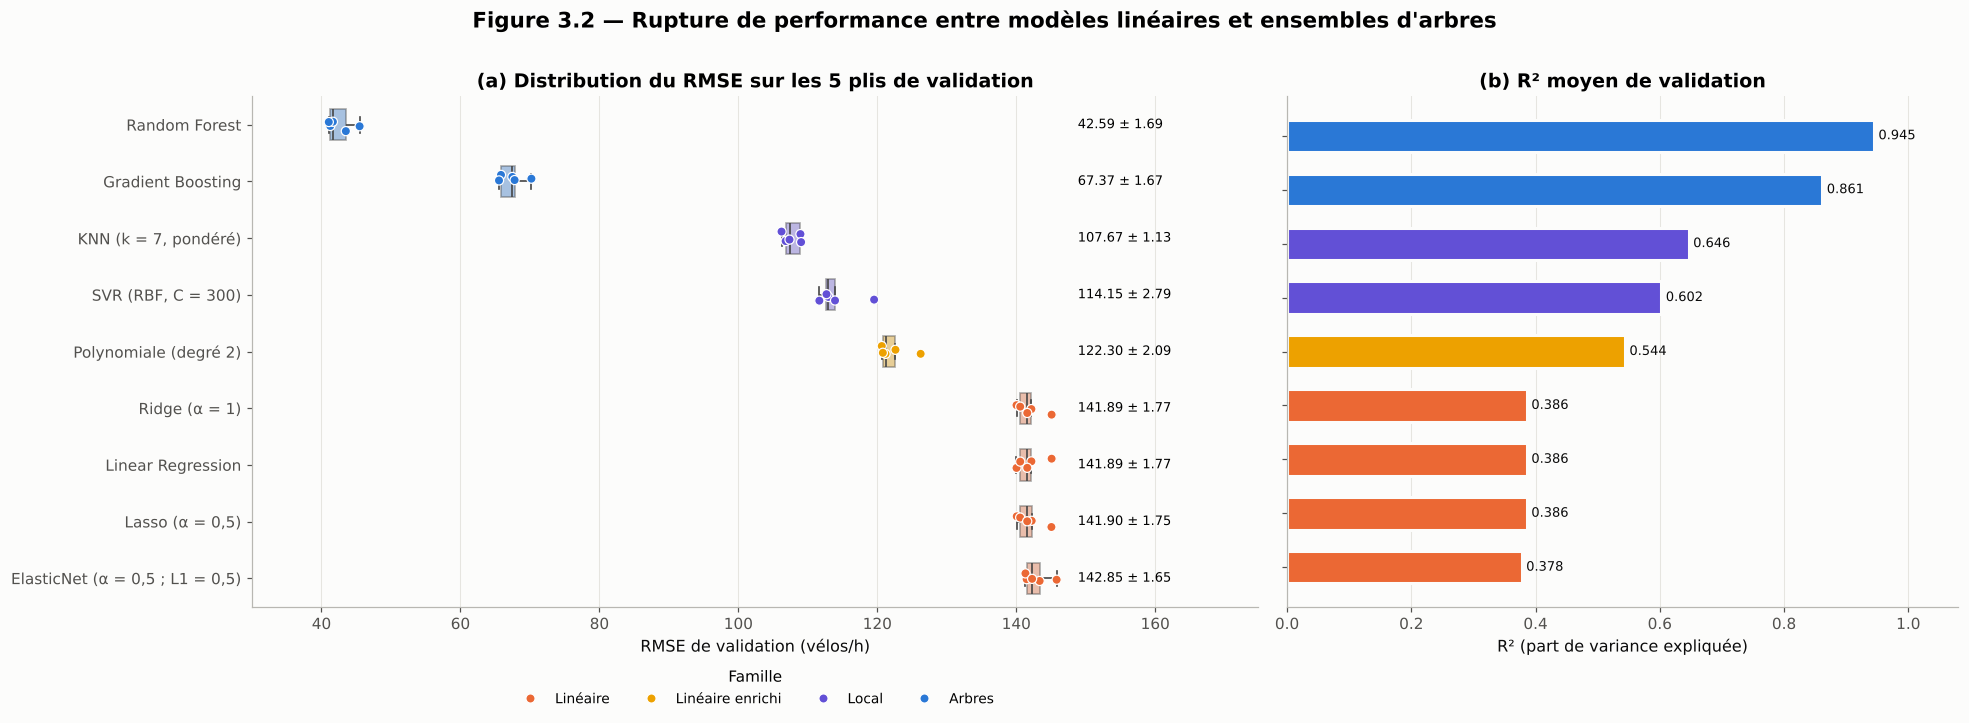

In [26]:
# ============================================================================
# 3.2 BENCHMARK 5-FOLD DE 9 MODÈLES
# ============================================================================
modeles = {
    "Linear Regression": LinearRegression(),
    "Lasso (α = 0,5)": Lasso(alpha=0.5, random_state=RANDOM_STATE),
    "Ridge (α = 1)": Ridge(alpha=1.0),
    "ElasticNet (α = 0,5 ; L1 = 0,5)": ElasticNet(alpha=0.5, l1_ratio=0.5, random_state=RANDOM_STATE),
    "Polynomiale (degré 2)": make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                                           StandardScaler(), LinearRegression()),
    "KNN (k = 7, pondéré)": KNeighborsRegressor(n_neighbors=7, weights="distance"),
    "SVR (RBF, C = 300)": SVR(kernel="rbf", C=300, epsilon=5),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}
famille = {"Linear Regression": "Linéaire", "Lasso (α = 0,5)": "Linéaire", "Ridge (α = 1)": "Linéaire",
           "ElasticNet (α = 0,5 ; L1 = 0,5)": "Linéaire", "Polynomiale (degré 2)": "Linéaire enrichi",
           "KNN (k = 7, pondéré)": "Local", "SVR (RBF, C = 300)": "Local",
           "Gradient Boosting": "Arbres", "Random Forest": "Arbres"}

scores_cv, plis = [], []
for nom, modele in modeles.items():
    pipe = make_pipeline(StandardScaler(), modele)
    res = cross_validate(pipe, Xtr, ytr, cv=kf, return_train_score=True,
                         scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rmse = -res["test_rmse"]
    scores_cv.append({"Modèle": nom, "Famille": famille[nom],
                      "RMSE moyen": rmse.mean(), "Écart-type RMSE": rmse.std(),
                      "MAE moyen": -res["test_mae"].mean(), "R² moyen (validation)": res["test_r2"].mean(),
                      "R² moyen (apprentissage)": res["train_r2"].mean(),
                      "Temps d'entraînement par pli (s)": res["fit_time"].mean()})
    for k in range(5):
        plis.append({"Modèle": nom, "Famille": famille[nom], "Pli": k + 1, "RMSE": rmse[k], "R²": res["test_r2"][k]})

tab_cv = pd.DataFrame(scores_cv).sort_values("RMSE moyen").reset_index(drop=True)
tab_cv["Écart R² (sur-apprentissage)"] = tab_cv["R² moyen (apprentissage)"] - tab_cv["R² moyen (validation)"]
tab_cv.index = tab_cv.index + 1
df_plis = pd.DataFrame(plis)

afficher_tableau(
    tab_cv, "Tableau 3.2 — Benchmark de 9 modèles en validation croisée 5-Fold (train, 9 525 heures)",
    formats={"RMSE moyen": "{:.2f}", "Écart-type RMSE": "{:.2f}", "MAE moyen": "{:.2f}",
             "R² moyen (validation)": "{:.4f}", "R² moyen (apprentissage)": "{:.4f}",
             "Temps d'entraînement par pli (s)": "{:.2f}", "Écart R² (sur-apprentissage)": "{:.4f}"},
    degrade=["RMSE moyen"], cmap="RdYlGn_r",
    post=lambda s: s.background_gradient(subset=["R² moyen (validation)"], cmap="RdYlGn"))

couleur_famille = {"Linéaire": COULEURS["orange"], "Linéaire enrichi": COULEURS["jaune"],
                   "Local": COULEURS["violet"], "Arbres": COULEURS["bleu"]}
ordre_modeles = tab_cv["Modèle"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
sns.boxplot(data=df_plis, y="Modèle", x="RMSE", order=ordre_modeles, hue="Famille", palette=couleur_famille,
            dodge=False, width=0.55, linewidth=1.1, ax=ax, legend=False, boxprops=dict(alpha=0.45), showfliers=False)
sns.stripplot(data=df_plis, y="Modèle", x="RMSE", order=ordre_modeles, hue="Famille", palette=couleur_famille,
              size=6, jitter=0.12, edgecolor="white", linewidth=0.8, ax=ax)
for i, (m, s_) in enumerate(zip(tab_cv["RMSE moyen"], tab_cv["Écart-type RMSE"])):
    ax.annotate(f"{m:.2f} ± {s_:.2f}", (tab_cv["RMSE moyen"].max() + 6, i), va="center", fontsize=8.5)
ax.set_xlim(30, tab_cv["RMSE moyen"].max() + 32)
ax.set_title("(a) Distribution du RMSE sur les 5 plis de validation")
ax.set_xlabel("RMSE de validation (vélos/h)")
ax.set_ylabel("")
ax.legend(title="Famille", loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=9)
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(tab_cv["Modèle"][::-1], tab_cv["R² moyen (validation)"][::-1],
        color=[couleur_famille[f] for f in tab_cv["Famille"][::-1]], height=0.6,
        edgecolor=COULEURS["fond"], linewidth=2)
annoter_barres(ax, fmt="{:.3f}", horizontal=True)
ax.set_xlim(0, 1.08)
ax.set_title("(b) R² moyen de validation")
ax.set_xlabel("R² (part de variance expliquée)")
ax.set_yticklabels([])
ax.grid(axis="y", visible=False)

fig.suptitle("Figure 3.2 — Rupture de performance entre modèles linéaires et ensembles d'arbres",
             fontweight="bold", fontsize=14, y=1.01)
plt.tight_layout()
sauver_figure(fig, "fig_3_2_benchmark_cv")
plt.show()

**Finding (Constats chiffrés)**

| Famille | Meilleur représentant | RMSE CV moyen | Écart-type | R² CV |
|---|---|---|---|---|
| Ensembles d'arbres | **Random Forest** | **42,59** | 1,69 | **0,945** |
| Ensembles d'arbres | Gradient Boosting | 67,37 | 1,67 | 0,861 |
| Locaux | KNN (k = 7) | 107,67 | 1,13 | 0,646 |
| Locaux | SVR (RBF) | 114,15 | 2,79 | 0,602 |
| Linéaire enrichi | Polynomiale degré 2 | 122,30 | 2,09 | 0,544 |
| Linéaires | Ridge / OLS / Lasso | **141,89 à 141,90** | 1,75 à 1,77 | **0,386** |
| Linéaires | ElasticNet | 142,85 | 1,65 | 0,378 |

* La **rupture de performance** est nette : la forêt aléatoire divise le RMSE des modèles linéaires par **3,3** (42,59 contre 141,89) et fait passer le $R^2$ de 0,386 à 0,945. Le Gradient Boosting par défaut (RMSE 67,37, $R^2$ 0,861) est déjà deux fois meilleur que l'OLS.
* Les modèles sont **stables** : l'écart-type inter-plis reste compris entre 1,1 et 2,8 vélos/h pour tous les modèles, soit moins de 5 % du RMSE moyen pour la forêt.
* Les quatre modèles linéaires sont quasi indiscernables (de 141,89 à 142,85) : la régularisation ne change rien quand le problème est la **forme** du modèle.
* **Sur-apprentissage :** la forêt atteint $R^2 = 0,992$ en apprentissage contre 0,945 en validation (écart 0,048) ; KNN pondéré par la distance atteint 1,000 en apprentissage (il « reconnaît » chaque point) contre 0,646 en validation. Le Gradient Boosting est le plus sobre (écart 0,007).
* **Coût de calcul :** 0,6 s par pli pour les ensembles d'arbres, 3,1 s pour le SVR (complexité quadratique en nombre d'observations), moins de 0,1 s pour les modèles linéaires.

**Insights (Interprétation métier et lien avec l'article)**
* On retrouve les valeurs attendues (OLS : RMSE ≈ 141,9, $R^2$ ≈ 0,386 ; GB : 67,37 et 0,861 ; RF : 42,5 à 42,6 et 0,945) et la conclusion du §5.3 de Jing Shi : **la forêt aléatoire est le meilleur prévisionniste**. L'écart est plus spectaculaire ici que dans l'article ($R^2$ de 0,68 à 0,72 pour les ventes BMW) car la demande de vélos est beaucoup plus non linéaire (profil bimodal, Étape 1.14).
* La polynomiale de degré 2 gagne 20 vélos/h de RMSE sur l'OLS grâce aux interactions d'ordre 2 (par exemple `hr × weekday`), mais reste loin des arbres : une parabole ne peut pas reproduire deux pics horaires.
* Pour un planificateur, la hiérarchie est claire : les modèles linéaires sont à réserver à l'**interprétation** (Étape 2), les ensembles d'arbres à la **décision**. Ce sont donc la forêt et le boosting qui seront optimisés à l'Étape 4.

## 3.3 Diagnostic des résidus : modèles linéaires vs arbres

**Pourquoi ?** Le RMSE dit **combien** un modèle se trompe, pas **comment**. Or, pour la décision de stock, la **structure** de l'erreur compte autant que sa taille : l'approche Two-Step suppose des résidus $\varepsilon_i = y_i - \hat{y}_i$ centrés, gaussiens et de variance constante (homoscédasticité). On calcule des prédictions **hors échantillon** (*out-of-fold*, chaque heure étant prédite par le modèle entraîné sans elle) pour la régression linéaire et la forêt aléatoire, puis on examine :
* les résidus en fonction de la prédiction (un « entonnoir » signale de l'hétéroscédasticité) ;
* la distribution des résidus (asymétrie, queues) ;
* l'écart-type des résidus selon l'heure de la journée (l'incertitude est-elle la même la nuit et aux heures de pointe ?).

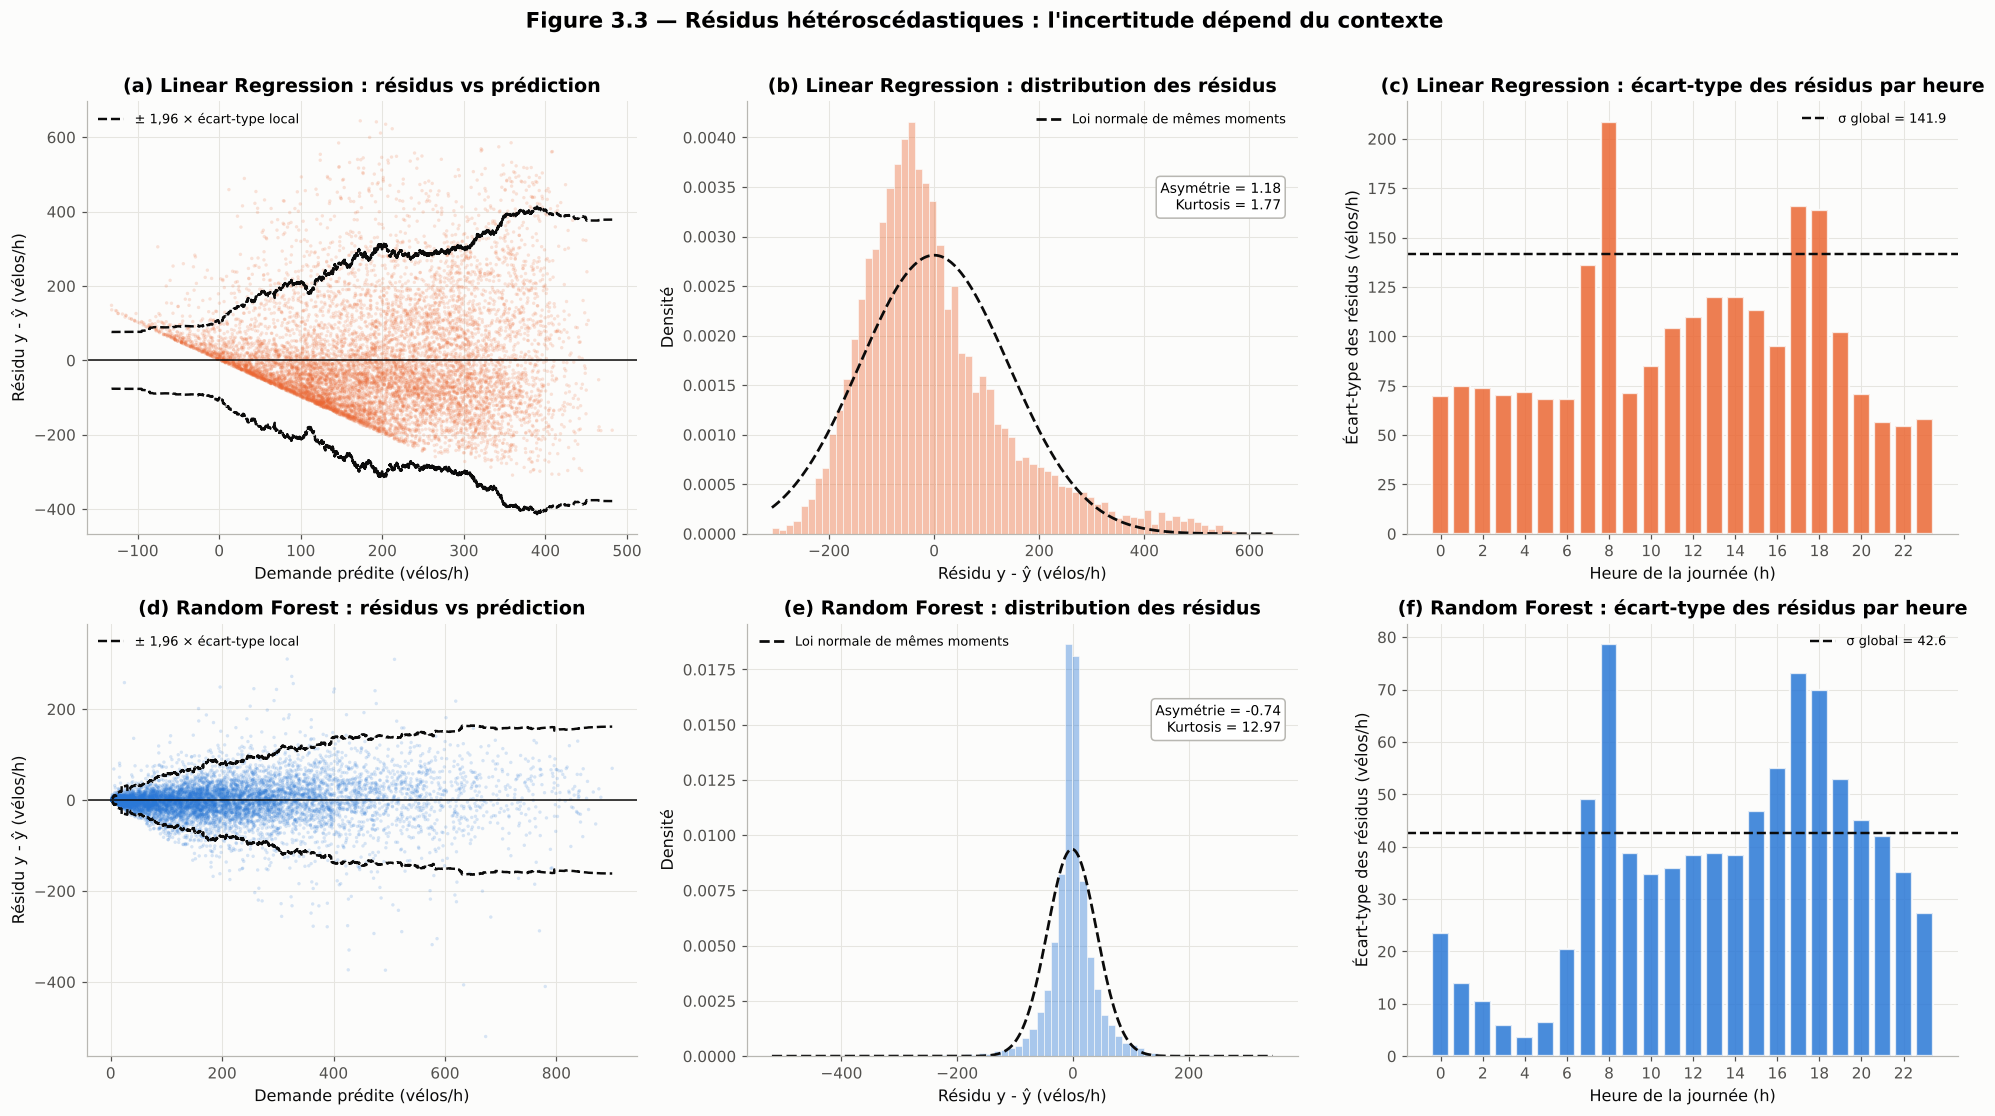

,Moyenne des résidus,σ global,σ nuit (0-5 h),σ heures de pointe,Ratio σ pointe / σ nuit,"Corr(|résidu|, prédiction)",Asymétrie,p-valeur normalité,Prédictions négatives
Modèle,,,,,,,,,
Linear Regression,-0.04,141.90,74.58,158.06,2.12,0.32,1.18,0.0e+00,429
Random Forest,-1.60,42.57,12.76,61.76,4.84,0.44,-0.74,0.0e+00,0


In [27]:
# ============================================================================
# 3.3 DIAGNOSTIC DES RÉSIDUS (PRÉDICTIONS OUT-OF-FOLD)
# ============================================================================
oof = {
    "Linear Regression": cross_val_predict(make_pipeline(StandardScaler(), LinearRegression()), Xtr, ytr, cv=kf),
    "Random Forest": cross_val_predict(RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
                                       Xtr, ytr, cv=kf),
}
coul_mod = {"Linear Regression": COULEURS["orange"], "Random Forest": COULEURS["bleu"]}
heures_tr = Xtr["hr"].values

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ligne, (nom, pred) in enumerate(oof.items()):
    resid = ytr.values - pred
    c = coul_mod[nom]
    ax = axes[ligne, 0]
    ax.scatter(pred, resid, s=5, alpha=0.18, color=c, edgecolor="none")
    ax.axhline(0, color=COULEURS["encre"], lw=1)
    # bande ±1,96 écart-type glissant pour visualiser l'entonnoir
    ordre_p = np.argsort(pred)
    roul = pd.Series(resid[ordre_p]).rolling(400, center=True, min_periods=100).std()
    ax.plot(pred[ordre_p], 1.96 * roul, color=COULEURS["encre"], lw=1.6, ls="--", label="± 1,96 × écart-type local")
    ax.plot(pred[ordre_p], -1.96 * roul, color=COULEURS["encre"], lw=1.6, ls="--")
    ax.set_title(f"({'a' if ligne == 0 else 'd'}) {nom} : résidus vs prédiction")
    ax.set_xlabel("Demande prédite (vélos/h)")
    ax.set_ylabel("Résidu y - ŷ (vélos/h)")
    ax.legend(loc="upper left", fontsize=8.5)

    ax = axes[ligne, 1]
    sns.histplot(resid, bins=70, stat="density", color=c, alpha=0.4, edgecolor=COULEURS["fond"], ax=ax)
    xs = np.linspace(resid.min(), resid.max(), 300)
    ax.plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), color=COULEURS["encre"], lw=1.8, ls="--",
            label="Loi normale de mêmes moments")
    ax.set_title(f"({'b' if ligne == 0 else 'e'}) {nom} : distribution des résidus")
    ax.set_xlabel("Résidu y - ŷ (vélos/h)")
    ax.set_ylabel("Densité")
    ax.legend(fontsize=8.5)
    ax.text(0.97, 0.75, f"Asymétrie = {stats.skew(resid):.2f}\nKurtosis = {stats.kurtosis(resid):.2f}",
            transform=ax.transAxes, ha="right", fontsize=9, bbox=dict(boxstyle="round", fc="white", ec=COULEURS["gris"]))

    ax = axes[ligne, 2]
    sd_h = pd.Series(resid).groupby(heures_tr).std()
    ax.bar(sd_h.index, sd_h.values, color=c, alpha=0.85, edgecolor=COULEURS["fond"], linewidth=1.5)
    ax.axhline(resid.std(), color=COULEURS["encre"], ls="--", lw=1.6, label=f"σ global = {resid.std():.1f}")
    ax.set_title(f"({'c' if ligne == 0 else 'f'}) {nom} : écart-type des résidus par heure")
    ax.set_xlabel("Heure de la journée (h)")
    ax.set_ylabel("Écart-type des résidus (vélos/h)")
    ax.set_xticks(range(0, 24, 2))
    ax.legend(fontsize=8.5)

fig.suptitle("Figure 3.3 — Résidus hétéroscédastiques : l'incertitude dépend du contexte",
             fontweight="bold", fontsize=14, y=1.01)
plt.tight_layout()
sauver_figure(fig, "fig_3_3_diagnostic_residus")
plt.show()

nuit, pointe = [0, 1, 2, 3, 4, 5], [7, 8, 9, 16, 17, 18, 19]
diag = []
for nom, pred in oof.items():
    r_ = ytr.values - pred
    k2r, pr = stats.normaltest(r_)
    diag.append({"Modèle": nom, "Moyenne des résidus": r_.mean(), "σ global": r_.std(),
                 "σ nuit (0-5 h)": r_[np.isin(heures_tr, nuit)].std(),
                 "σ heures de pointe": r_[np.isin(heures_tr, pointe)].std(),
                 "Ratio σ pointe / σ nuit": r_[np.isin(heures_tr, pointe)].std() / r_[np.isin(heures_tr, nuit)].std(),
                 "Corr(|résidu|, prédiction)": np.corrcoef(np.abs(r_), pred)[0, 1],
                 "Asymétrie": stats.skew(r_), "p-valeur normalité": pr,
                 "Prédictions négatives": int((pred < 0).sum())})
tab_diag = pd.DataFrame(diag).set_index("Modèle")
afficher_tableau(tab_diag, "Tableau 3.3 — Diagnostic des résidus out-of-fold (train)",
                 formats={c: "{:.2f}" for c in tab_diag.columns if c not in ("p-valeur normalité", "Prédictions négatives")}
                 | {"p-valeur normalité": "{:.1e}", "Prédictions négatives": "{:d}"})

**Finding (Constats chiffrés)**

| Indicateur (résidus out-of-fold) | Linear Regression | Random Forest |
|---|---|---|
| σ global | 141,90 | **42,57** |
| σ la nuit (0-5 h) | 74,58 | **12,76** |
| σ aux heures de pointe (7-9 h, 16-19 h) | 158,06 | 61,76 |
| Ratio σ pointe / σ nuit | 2,1 | **4,8** |
| Corrélation entre \|résidu\| et prédiction | 0,32 | 0,44 |
| Asymétrie des résidus | +1,18 | -0,74 |
| Kurtosis (excès) | 1,77 | **12,97** |
| Prédictions négatives | **429** | 0 |

* **Régression linéaire :** le nuage résidus / prédictions est **strié en diagonale** : pour les petites prédictions, le résidu est borné par $-\hat{y}$ car la demande ne peut pas être négative. Le modèle prédit même **429 demandes négatives**. Les résidus sont asymétriques (+1,18) : le modèle sous-estime systématiquement les pics.
* **Random Forest :** l'« entonnoir » est net : la bande à ±1,96 écart-type s'élargit avec le niveau de demande. L'écart-type des résidus va de **≈ 4 vélos/h à 4 h du matin** à **≈ 79 vélos/h à 8 h**. Les résidus sont centrés mais très pointus (kurtosis 12,97) : la plupart des erreurs sont minuscules, quelques-unes énormes.
* Dans les deux cas, la normalité des résidus est rejetée (p-valeur numériquement nulle).

**Insights (Interprétation métier et lien avec l'article)**
* C'est la démonstration empirique de la faiblesse du Two-Step. Celui-ci ajoute **un seul** stock de sécurité $z^*\sigma$ calculé avec le σ global. Pour la forêt, ce σ global (42,6) est **3,3 fois trop grand la nuit** et **1,5 fois trop petit aux heures de pointe** : on sur-stocke quand la demande est faible et on sous-stocke quand elle explose.
* L'hypothèse gaussienne est elle aussi fausse : avec un kurtosis de 13, les quantiles extrêmes d'une loi normale sont mal placés. Jing Shi le résume ainsi : l'industrie « modifie » la prévision en supposant des résidus $\mathcal{N}(0, \sigma^2)$ (§5.4), ce qui est une approximation.
* Le One-Step FBNV répond aux deux problèmes à la fois : en apprenant le **quantile conditionnel** $Q_{\alpha^*}(D \mid \mathbf{x})$, il fixe une marge **différente pour chaque contexte** et **sans hypothèse de forme**. L'Étape 4 va chiffrer ce gain.

---
# ÉTAPE 4 — Optimisation des stocks : Direct, Two-Step et One-Step FBNV

L'Étape 3 a identifié les meilleurs **prévisionnistes**. L'Étape 4 répond à la vraie question du gestionnaire : **combien de vélos positionner** pour minimiser le coût total ? C'est le cœur de l'article de Jing Shi : un bon prévisionniste n'est pas forcément un bon décideur.

| # | Micro-étape | Objectif |
|---|---|---|
| 4.1 | Étude de convergence | Choisir des plages réalistes pour `n_estimators` et `max_depth` |
| 4.2 | `GridSearchCV` des ensembles d'arbres | Optimiser Random Forest et Gradient Boosting (critère RMSE) |
| 4.3 | Le modèle Newsvendor et la perte Pinball | Démontrer que la commande optimale est un **quantile** |
| 4.4 | Trois stratégies de commande | Direct, Two-Step, One-Step FBNV pour LR, Lasso, GB et RF |
| 4.5 | Analyse de sensibilité au ratio $b/(b+h)$ | Tester la robustesse du gain de 0,10 à 0,95 |

## 4.1 Étude de convergence selon `n_estimators` et `max_depth`

**Pourquoi ?** Une grille de recherche aveugle coûte cher en calcul. On étudie d'abord la convergence des deux ensembles d'arbres pour savoir **où chercher** :
* **Random Forest** : l'erreur *out-of-bag* (OOB, calculée sur les observations non tirées par le bootstrap de chaque arbre) en fonction du nombre d'arbres. Ajouter des arbres ne cause pas de sur-apprentissage, mais le gain devient marginal au-delà d'un certain nombre.
* **Gradient Boosting** : l'erreur de validation (sur 20 % du train mis de côté) au fil des itérations, pour plusieurs profondeurs d'arbres. Contrairement à la forêt, le boosting **peut** sur-apprendre si on ajoute trop d'itérations.

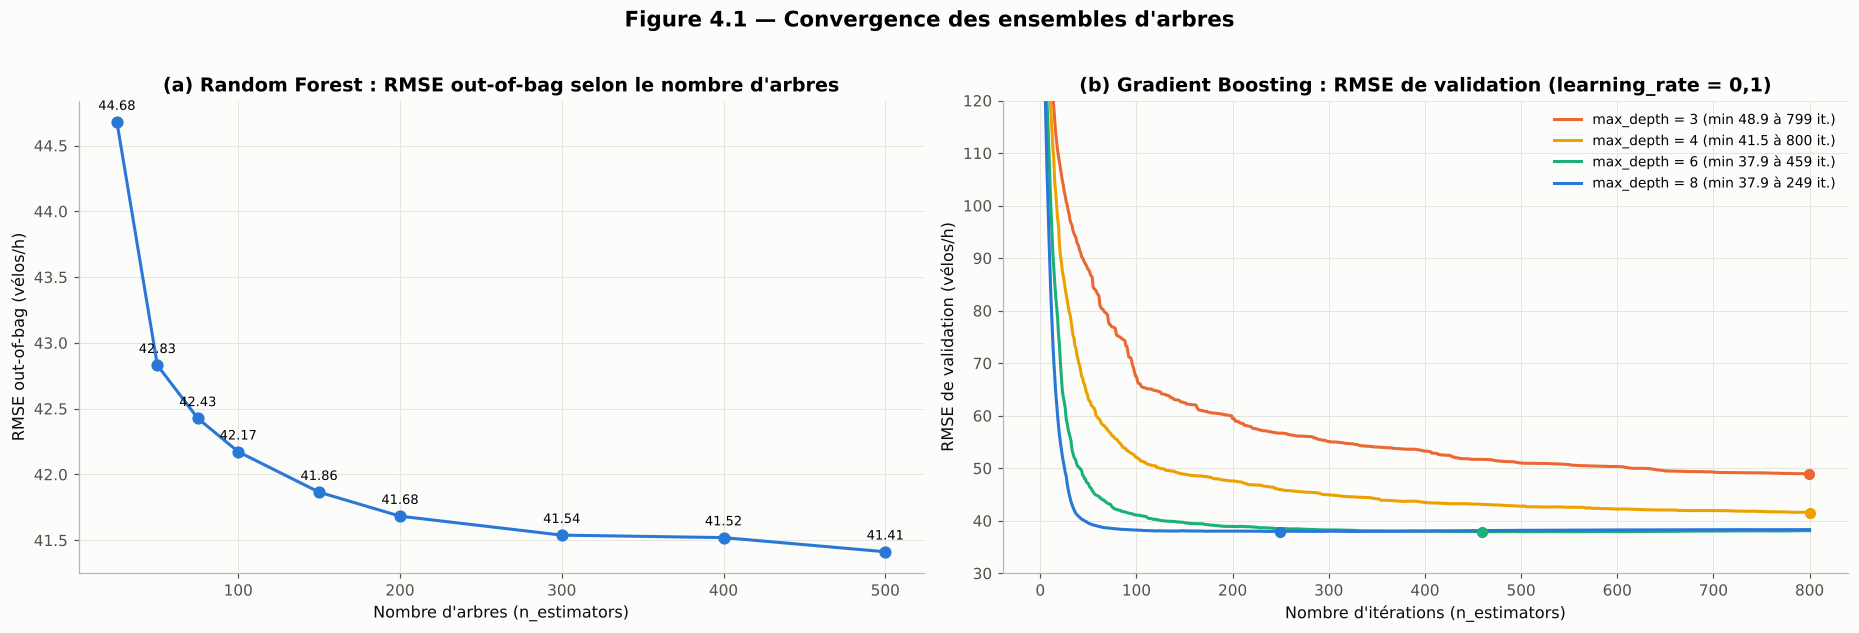

Configuration,RMSE après 100 it.,RMSE minimal,Itération optimale,RMSE après 800 it.
"Gradient Boosting, max_depth = 3",67.49,48.93,799,48.93
"Gradient Boosting, max_depth = 4",52.10,41.54,800,41.54
"Gradient Boosting, max_depth = 6",41.08,37.88,459,38.11
"Gradient Boosting, max_depth = 8",38.21,37.94,249,38.30


RMSE OOB de la forêt : 25 arbres = 44.68 | 50 arbres = 42.83 | 75 arbres = 42.43 | 100 arbres = 42.17 | 150 arbres = 41.86 | 200 arbres = 41.68 | 300 arbres = 41.54 | 400 arbres = 41.52 | 500 arbres = 41.41


In [28]:
# ============================================================================
# 4.1 ÉTUDE DE CONVERGENCE
# ============================================================================
# (a) Random Forest : erreur OOB en fonction du nombre d'arbres
rf_oob = RandomForestRegressor(warm_start=True, oob_score=True, random_state=RANDOM_STATE, n_jobs=-1)
grille_arbres = [25, 50, 75, 100, 150, 200, 300, 400, 500]
oob_rmse = []
for n in grille_arbres:
    rf_oob.set_params(n_estimators=n)
    rf_oob.fit(Xtr, ytr)
    oob_rmse.append(np.sqrt(mean_squared_error(ytr, rf_oob.oob_prediction_)))

# (b) Gradient Boosting : erreur de validation par itération et par profondeur
X_a, X_v, y_a, y_v = train_test_split(Xtr, ytr, test_size=0.2, random_state=RANDOM_STATE)
profondeurs = [3, 4, 6, 8]
courbes_gb = {}
for p in profondeurs:
    gb_c = GradientBoostingRegressor(n_estimators=800, max_depth=p, learning_rate=0.1, random_state=RANDOM_STATE)
    gb_c.fit(X_a, y_a)
    courbes_gb[p] = np.array([np.sqrt(mean_squared_error(y_v, pr)) for pr in gb_c.staged_predict(X_v)])

fig, axes = plt.subplots(1, 2, figsize=(17, 5.6))
ax = axes[0]
ax.plot(grille_arbres, oob_rmse, marker="o", ms=7, color=COULEURS["bleu"])
for n, v in zip(grille_arbres, oob_rmse):
    ax.annotate(f"{v:.2f}", (n, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8.5)
ax.set_title("(a) Random Forest : RMSE out-of-bag selon le nombre d'arbres")
ax.set_xlabel("Nombre d'arbres (n_estimators)")
ax.set_ylabel("RMSE out-of-bag (vélos/h)")

ax = axes[1]
coul_p = [COULEURS["orange"], COULEURS["jaune"], COULEURS["vert_eau"], COULEURS["bleu"]]
for p, c in zip(profondeurs, coul_p):
    cb = courbes_gb[p]
    ax.plot(np.arange(1, len(cb) + 1), cb, color=c, lw=2, label=f"max_depth = {p} (min {cb.min():.1f} à {cb.argmin() + 1} it.)")
    ax.scatter([cb.argmin() + 1], [cb.min()], color=c, s=40, zorder=3)
ax.set_ylim(30, 120)
ax.set_title("(b) Gradient Boosting : RMSE de validation (learning_rate = 0,1)")
ax.set_xlabel("Nombre d'itérations (n_estimators)")
ax.set_ylabel("RMSE de validation (vélos/h)")
ax.legend(fontsize=9)
fig.suptitle("Figure 4.1 — Convergence des ensembles d'arbres", fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_4_1_convergence")
plt.show()

conv = pd.DataFrame({"Configuration": [f"Gradient Boosting, max_depth = {p}" for p in profondeurs],
                     "RMSE après 100 it.": [courbes_gb[p][99] for p in profondeurs],
                     "RMSE minimal": [courbes_gb[p].min() for p in profondeurs],
                     "Itération optimale": [int(courbes_gb[p].argmin() + 1) for p in profondeurs],
                     "RMSE après 800 it.": [courbes_gb[p][-1] for p in profondeurs]})
afficher_tableau(conv, "Tableau 4.1 — Convergence du Gradient Boosting (validation interne 20 %)",
                 formats={c: "{:.2f}" for c in conv.columns[1:] if c != "Itération optimale"},
                 degrade=["RMSE minimal"], cmap="RdYlGn_r", index=False)
print("RMSE OOB de la forêt : " + " | ".join(f"{n} arbres = {v:.2f}" for n, v in zip(grille_arbres, oob_rmse)))

**Finding (Constats chiffrés)**
* **Random Forest :** le RMSE out-of-bag baisse vite jusqu'à 100 arbres (44,68 à 25 arbres, **42,17** à 100), puis ne gagne plus que 0,8 vélo/h jusqu'à 500 arbres (**41,41**). Au-delà de 300 arbres (41,54), le gain est inférieur à 0,2 vélo/h.
* **Gradient Boosting :** la profondeur est le paramètre décisif. Avec `max_depth = 3` (valeur par défaut), le RMSE est encore de 67,5 après 100 itérations et ne descend qu'à 48,9 après 800. Avec `max_depth = 6`, il atteint **37,9** vers 460 itérations ; avec `max_depth = 8`, **37,9** dès 250 itérations, puis remonte légèrement (38,3 à 800 itérations).

**Insights (Interprétation métier et lien avec l'article)**
* Le Gradient Boosting par défaut de l'Étape 3 (100 arbres de profondeur 3) était fortement **sous-dimensionné** : des arbres de profondeur 3 ne peuvent combiner que 3 variables à la fois, alors que la demande dépend d'interactions comme `hr × weekday × temp`.
* La légère remontée à `max_depth = 8` est le signe du **sur-apprentissage** propre au boosting. Elle justifie de limiter la grille à `max_depth` ∈ {4, 6} et `n_estimators` ∈ {300, 600} pour la recherche suivante.
* Pour la forêt, la courbe plate au-delà de 300 arbres montre qu'il est inutile de payer plus de calcul : c'est la borne haute de la grille.

## 4.2 Optimisation des hyperparamètres par `GridSearchCV`

**Pourquoi ?** L'article optimise la forêt aléatoire par recherche sur grille (« grid search to search n-estimators, max-features, bootstrap », §5.2). On reproduit cette démarche pour les deux ensembles d'arbres, dans les plages suggérées par l'étude de convergence, avec la **même** validation croisée 5-Fold et le RMSE comme critère :
* **Random Forest** : `n_estimators` ∈ {100, 300}, `max_features` ∈ {1,0 ; 0,6}, `min_samples_leaf` ∈ {1, 2} ;
* **Gradient Boosting** : `n_estimators` ∈ {300, 600}, `max_depth` ∈ {4, 6}, `learning_rate` ∈ {0,05 ; 0,1}.

Les arbres étant invariants aux changements d'échelle, ils sont entraînés directement sur les variables brutes.

In [29]:
# ============================================================================
# 4.2 GRIDSEARCHCV (CRITÈRE RMSE)
# ============================================================================
grilles = {
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                      {"n_estimators": [100, 300], "max_features": [1.0, 0.6], "min_samples_leaf": [1, 2]}, 1),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"n_estimators": [300, 600], "max_depth": [4, 6], "learning_rate": [0.05, 0.1]}, -1),
}
recherches, lignes_gs = {}, []
for nom, (estim, grille, nj) in grilles.items():
    t0 = time.time()
    gs = GridSearchCV(estim, grille, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=nj)
    gs.fit(Xtr, ytr)
    recherches[nom] = gs
    res = pd.DataFrame(gs.cv_results_)
    for _, r in res.sort_values("rank_test_score").iterrows():
        lignes_gs.append({"Modèle": nom, "Rang": int(r["rank_test_score"]),
                          "Hyperparamètres": ", ".join(f"{k.replace('param_', '')} = {r[k]}" for k in res.columns
                                                       if k.startswith("param_")),
                          "RMSE CV moyen": -r["mean_test_score"], "Écart-type": r["std_test_score"],
                          "Temps par pli (s)": r["mean_fit_time"]})
    print(f"{nom} : {len(res)} combinaisons x 5 plis évaluées en {time.time() - t0:.0f} s")

tab_gs = pd.DataFrame(lignes_gs)
afficher_tableau(tab_gs, "Tableau 4.2a — Résultats complets des recherches sur grille (classés par RMSE)",
                 formats={"RMSE CV moyen": "{:.2f}", "Écart-type": "{:.2f}", "Temps par pli (s)": "{:.2f}"},
                 degrade=["RMSE CV moyen"], cmap="RdYlGn_r", index=False)

defaut = tab_cv.set_index("Modèle")["RMSE moyen"]
meilleurs = pd.DataFrame({
    "Modèle": list(recherches),
    "Hyperparamètres optimaux": [str(gs.best_params_) for gs in recherches.values()],
    "RMSE CV par défaut (3.2)": [defaut["Random Forest"], defaut["Gradient Boosting"]],
    "RMSE CV optimisé": [-gs.best_score_ for gs in recherches.values()],
})
meilleurs["Gain (%)"] = (1 - meilleurs["RMSE CV optimisé"] / meilleurs["RMSE CV par défaut (3.2)"]) * 100
afficher_tableau(meilleurs, "Tableau 4.2b — Gain apporté par l'optimisation des hyperparamètres",
                 formats={"RMSE CV par défaut (3.2)": "{:.2f}", "RMSE CV optimisé": "{:.2f}", "Gain (%)": "{:.1f} %"},
                 index=False)

rf_best = recherches["Random Forest"].best_estimator_
gb_best = recherches["Gradient Boosting"].best_estimator_

Random Forest : 8 combinaisons x 5 plis évaluées en 47 s


Gradient Boosting : 8 combinaisons x 5 plis évaluées en 63 s


Modèle,Rang,Hyperparamètres,RMSE CV moyen,Écart-type,Temps par pli (s)
Random Forest,1,"max_features = 1.0, min_samples_leaf = 1, n_estimators = 300",42.46,1.68,2.13
Random Forest,2,"max_features = 1.0, min_samples_leaf = 1, n_estimators = 100",42.56,1.66,0.64
Random Forest,3,"max_features = 1.0, min_samples_leaf = 2, n_estimators = 300",43.22,1.47,1.70
Random Forest,4,"max_features = 1.0, min_samples_leaf = 2, n_estimators = 100",43.34,1.44,0.56
Random Forest,5,"max_features = 0.6, min_samples_leaf = 1, n_estimators = 300",44.22,1.49,1.35
Random Forest,6,"max_features = 0.6, min_samples_leaf = 1, n_estimators = 100",44.54,1.45,0.46
Random Forest,7,"max_features = 0.6, min_samples_leaf = 2, n_estimators = 300",45.96,1.21,1.07
Random Forest,8,"max_features = 0.6, min_samples_leaf = 2, n_estimators = 100",46.19,0.99,0.38
Gradient Boosting,1,"learning_rate = 0.1, max_depth = 6, n_estimators = 600",38.52,1.19,7.93
Gradient Boosting,2,"learning_rate = 0.05, max_depth = 6, n_estimators = 600",38.74,1.59,7.57


Modèle,Hyperparamètres optimaux,RMSE CV par défaut (3.2),RMSE CV optimisé,Gain (%)
Random Forest,"{'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 300}",42.59,42.46,0.3 %
Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 600}",67.37,38.52,42.8 %


**Finding (Constats chiffrés)**
* **Random Forest :** meilleure combinaison `n_estimators = 300`, `max_features = 1,0`, `min_samples_leaf = 1`, avec un RMSE CV de **42,46** (contre 42,59 par défaut, soit **-0,3 %**). Réduire `max_features` à 0,6 ou imposer 2 observations par feuille **dégrade** l'erreur (jusqu'à 46,19).
* **Gradient Boosting :** meilleure combinaison `learning_rate = 0,1`, `max_depth = 6`, `n_estimators = 600`, avec un RMSE CV de **38,52** (contre 67,37 par défaut, soit **-42,8 %**). Le Gradient Boosting optimisé **dépasse désormais la forêt aléatoire** (38,52 contre 42,46).
* Les 16 combinaisons × 5 plis ont été évaluées en environ 1 minute 40.

**Insights (Interprétation métier et lien avec l'article)**
* L'article optimise la forêt par recherche sur grille et constate qu'elle reste le meilleur modèle. Sur nos données, la forêt était **déjà proche de son optimum** par défaut, alors que le boosting était mal réglé. Après optimisation, la hiérarchie s'inverse : c'est un résultat important pour le rapport, qui montre que **comparer des modèles non optimisés peut induire en erreur**.
* Ce constat rejoint la remarque finale de Jing Shi (§6, point 4) : la supériorité de la forêt « n'est pas nécessairement le cas pour d'autres jeux de données ». On conserve les deux modèles optimisés pour l'optimisation des stocks.

## 4.3 Le modèle Newsvendor et la perte Pinball : démonstration

**Pourquoi ?** Avant de comparer les stratégies, il faut établir **quelle quantité minimise le coût**. Ce n'est pas la demande moyenne.

### Fonction de coût

Pour une commande $q$ et une demande réalisée $D$, le coût d'inventaire est :

$$C(q, D) = b\,(D - q)^+ + h\,(q - D)^+ \qquad \text{avec } (x)^+ = \max(x, 0)$$

avec $b = 10$ le coût unitaire de **rupture** (location perdue) et $h = 4$ le coût unitaire de **sur-stockage** (vélo immobilisé).

### Condition d'optimalité

Le coût espéré est $\mathbb{E}[C(q, D)] = b\,\mathbb{E}[(D-q)^+] + h\,\mathbb{E}[(q-D)^+]$. En dérivant par rapport à $q$ :

$$\frac{d\,\mathbb{E}[C]}{dq} = -b\,\big(1 - F(q)\big) + h\,F(q) = 0 \quad\Longrightarrow\quad F(q^*) = \frac{b}{b+h} = \alpha^*$$

La commande optimale est donc le **quantile d'ordre $\alpha^*$** de la distribution de la demande : $q^* = F^{-1}(\alpha^*) = \inf\{q : F(q) \ge \frac{b}{b+h}\}$, ce qui correspond à la solution donnée par Jing Shi (§3.2). Avec nos coûts :

$$\alpha^* = \frac{10}{10 + 4} = \frac{10}{14} \approx 0{,}7143 \qquad z^* = \Phi^{-1}(0{,}7143) \approx 0{,}5659$$

Interprétation : comme une rupture coûte 2,5 fois plus cher qu'un vélo en trop, on accepte de sur-stocker dans 71,4 % des cas.

### Lien avec la perte Pinball (régression quantile)

La perte Pinball d'ordre $\alpha$ est $\rho_\alpha(u) = \alpha\, u^+ + (1-\alpha)\, u^-$ avec $u = y - \hat{q}$. Avec $\alpha = \alpha^*$ :

$$(b + h)\,\rho_{\alpha^*}(D - q) = (b+h)\Big[\tfrac{b}{b+h}(D-q)^+ + \tfrac{h}{b+h}(q-D)^+\Big] = C(q, D)$$

**Minimiser la perte Pinball au niveau $\alpha^*$, c'est exactement minimiser le coût du newsvendor.** C'est l'équation (2) de l'article : le modèle One-Step FBNV apprend directement $q(\mathbf{x})$ en minimisant le coût empirique $\frac{1}{n}\sum_i C(q(\mathbf{x}_i), d_i)$.

### Les trois stratégies comparées

| Stratégie | Commande | Hypothèse |
|---|---|---|
| **Direct Forecasting** (§5.4 de l'article) | $q_i = \hat{d}_i$ | Commander la prévision moyenne ; ignore $b$ et $h$ |
| **Two-Step** (prévoir puis optimiser) | $q_i = \hat{d}_i + z^* \sigma_{\text{résidus}}$ | Résidus gaussiens, $\sigma$ identique pour toutes les heures |
| **One-Step FBNV** (*Predict-to-Optimize*) | $q_i = \hat{Q}_{\alpha^*}(D \mid \mathbf{x}_i)$ | Aucune hypothèse de forme : quantile conditionnel appris |

La cellule suivante illustre numériquement cette démonstration.

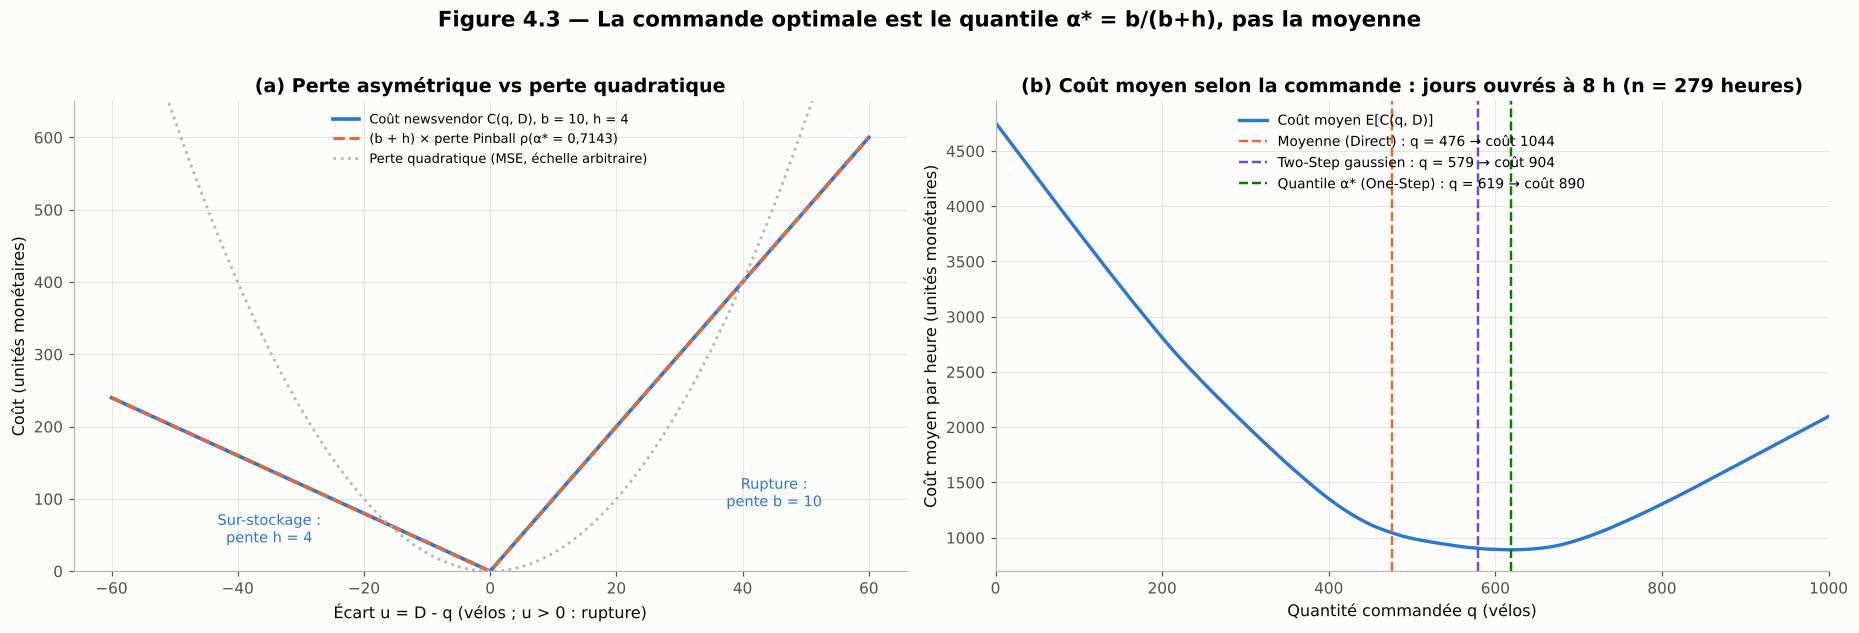

Paramètre,Valeur
Coût unitaire de rupture b,10
Coût unitaire de sur-stockage h,4
Fractile critique α* = b/(b+h),0.7143
Quantile gaussien z* = Φ⁻¹(α*),0.5659
Exemple 8 h ouvré : commande = moyenne,q = 475.6 → coût moyen 1044.45
Exemple 8 h ouvré : commande Two-Step gaussienne,q = 578.7 → coût moyen 904.01
Exemple 8 h ouvré : commande = quantile α*,q = 619.1 → coût moyen 890.37
Exemple 8 h ouvré : commande minimisant le coût (recherche exhaustive),q = 620 → coût moyen 890.36


In [30]:
# ============================================================================
# 4.3 NEWSVENDOR : FRACTILE CRITIQUE ET PERTE PINBALL
# ============================================================================
B_RUPTURE, H_STOCK = 10, 4
ALPHA_STAR = B_RUPTURE / (B_RUPTURE + H_STOCK)
Z_STAR = stats.norm.ppf(ALPHA_STAR)


def cout_newsvendor(y, q, b=B_RUPTURE, h=H_STOCK):
    # Coût d'inventaire C(q, D) = b (D - q)+ + h (q - D)+ pour chaque période.
    y, q = np.asarray(y, dtype=float), np.asarray(q, dtype=float)
    return b * np.maximum(y - q, 0) + h * np.maximum(q - y, 0)


def pinball(y, q, alpha):
    u = np.asarray(y, dtype=float) - np.asarray(q, dtype=float)
    return np.maximum(alpha * u, (alpha - 1) * u)


# Exemple : jours ouvrés à 8 h (demande observée dans le train)
d8 = ytr[(Xtr["hr"] == 8) & (Xtr["weekday"] < 5) & (Xtr["holiday"] == 0)].values
grille_q = np.arange(0, 1001)
cout_moyen = np.array([cout_newsvendor(d8, q).mean() for q in grille_q])
q_opt = grille_q[cout_moyen.argmin()]
q_quantile = np.quantile(d8, ALPHA_STAR)
q_normal = d8.mean() + Z_STAR * d8.std()

fig, axes = plt.subplots(1, 2, figsize=(17, 5.6))
ax = axes[0]
u = np.linspace(-60, 60, 400)
ax.plot(u, cout_newsvendor(0, -u), color=COULEURS["bleu"], lw=2.4, label="Coût newsvendor C(q, D), b = 10, h = 4")
ax.plot(u, (B_RUPTURE + H_STOCK) * pinball(u, 0, ALPHA_STAR), color=COULEURS["orange"], lw=2, ls="--",
        label="(b + h) × perte Pinball ρ(α* = 0,7143)")
ax.plot(u, 0.25 * u ** 2, color=COULEURS["gris"], lw=1.8, ls=":", label="Perte quadratique (MSE, échelle arbitraire)")
ax.annotate("Rupture :\npente b = 10", (45, 90), fontsize=9.5, color=COULEURS["bleu"], ha="center")
ax.annotate("Sur-stockage :\npente h = 4", (-35, 40), fontsize=9.5, color=COULEURS["bleu"], ha="center")
ax.set_ylim(0, 650)
ax.set_title("(a) Perte asymétrique vs perte quadratique")
ax.set_xlabel("Écart u = D - q (vélos ; u > 0 : rupture)")
ax.set_ylabel("Coût (unités monétaires)")
ax.legend(fontsize=8.5, loc="upper center")

ax = axes[1]
ax.plot(grille_q, cout_moyen, color=COULEURS["bleu"], lw=2.2, label="Coût moyen E[C(q, D)]")
for val, lib, c in [(d8.mean(), f"Moyenne (Direct) : q = {d8.mean():.0f}", COULEURS["orange"]),
                    (q_normal, f"Two-Step gaussien : q = {q_normal:.0f}", COULEURS["violet"]),
                    (q_quantile, f"Quantile α* (One-Step) : q = {q_quantile:.0f}", COULEURS["vert"])]:
    ax.axvline(val, color=c, ls="--", lw=1.6, label=f"{lib} → coût {cout_newsvendor(d8, val).mean():.0f}")
ax.set_xlim(0, 1000)
ax.set_title(f"(b) Coût moyen selon la commande : jours ouvrés à 8 h (n = {len(d8)} heures)")
ax.set_xlabel("Quantité commandée q (vélos)")
ax.set_ylabel("Coût moyen par heure (unités monétaires)")
ax.legend(loc="upper center", fontsize=9)
fig.suptitle("Figure 4.3 — La commande optimale est le quantile α* = b/(b+h), pas la moyenne",
             fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_4_3_newsvendor_pinball")
plt.show()

nv = pd.DataFrame({
    "Paramètre": ["Coût unitaire de rupture b", "Coût unitaire de sur-stockage h", "Fractile critique α* = b/(b+h)",
                  "Quantile gaussien z* = Φ⁻¹(α*)", "Exemple 8 h ouvré : commande = moyenne",
                  "Exemple 8 h ouvré : commande Two-Step gaussienne", "Exemple 8 h ouvré : commande = quantile α*",
                  "Exemple 8 h ouvré : commande minimisant le coût (recherche exhaustive)"],
    "Valeur": [B_RUPTURE, H_STOCK, f"{ALPHA_STAR:.4f}", f"{Z_STAR:.4f}",
               f"q = {d8.mean():.1f} → coût moyen {cout_newsvendor(d8, d8.mean()).mean():.2f}",
               f"q = {q_normal:.1f} → coût moyen {cout_newsvendor(d8, q_normal).mean():.2f}",
               f"q = {q_quantile:.1f} → coût moyen {cout_newsvendor(d8, q_quantile).mean():.2f}",
               f"q = {q_opt} → coût moyen {cout_moyen.min():.2f}"],
})
afficher_tableau(nv, "Tableau 4.3 — Paramètres du newsvendor et vérification numérique", index=False)

**Finding (Constats chiffrés)**
* Paramètres retenus : $b = 10$, $h = 4$, **$\alpha^* = 0,7143$**, **$z^* = 0,5659$**.
* La figure (a) confirme graphiquement que $(b+h)\,\rho_{\alpha^*}$ et le coût newsvendor sont **la même fonction** (courbes superposées), alors que la perte quadratique est symétrique.
* Sur l'exemple des jours ouvrés à 8 h (279 heures, demande moyenne 475,6 vélos/h) :

| Commande | q (vélos) | Coût moyen par heure |
|---|---|---|
| Moyenne (Direct) | 475,6 | 1 044,45 |
| Two-Step gaussien $\mu + z^*\sigma$ | 578,7 | 904,01 |
| **Quantile empirique $\alpha^*$** | **619,1** | **890,37** |
| Optimum par recherche exhaustive | 620 | 890,36 |

**Insights (Interprétation métier et lien avec l'article)**
* La vérification numérique est exacte : le quantile empirique d'ordre 0,7143 (619,1) coïncide à moins d'un vélo près avec la commande qui minimise le coût par recherche exhaustive (620). C'est la solution SAA de l'équation (1) de l'article.
* Commander la moyenne coûte **17 % de plus** que l'optimum : un « bon prévisionniste » (sans biais en moyenne) est un **mauvais décideur** dès que les coûts sont asymétriques. Le Two-Step gaussien réduit l'écart mais rate encore l'optimum de 40 vélos, parce que la vraie distribution n'est pas normale.
* C'est le fondement théorique du FBNV : entraîner un modèle avec la perte Pinball au niveau $\alpha^*$ revient à entraîner un modèle **directement sur le coût financier**. La prévision et la décision ne font plus qu'une seule étape.

## 4.4 Implémentation des trois stratégies : Direct, Two-Step et One-Step FBNV

**Pourquoi ?** On construit, pour quatre modèles (LR, Lasso, Gradient Boosting, Random Forest), les trois politiques de commande, puis on les évalue sur le **jeu de test** (1 361 heures jamais vues), comme le Tableau 9 de l'article.

**Two-Step.** Le $\sigma_{\text{résidus}}$ est estimé sur les résidus **out-of-fold** du jeu d'entraînement. Les résidus d'apprentissage d'une forêt aléatoire sont quasi nuls (elle « mémorise » le train) : les utiliser sous-estimerait grossièrement l'incertitude réelle.

**One-Step FBNV**, un modèle par famille :
* **LR+FB** : régression quantile linéaire (`QuantileRegressor`, quantile $\alpha^*$, sans pénalité), résolue exactement par programmation linéaire (solveur HiGHS) ;
* **LA+FB** : même modèle avec une pénalité $L_1$ (`alpha = 0,05`), analogue quantile du Lasso ;
* **GB+FB** : `GradientBoostingRegressor(loss="quantile", alpha=α*)`, dont les hyperparamètres sont **ré-optimisés par `GridSearchCV` avec la perte Pinball comme critère**. C'est la logique *Predict-to-Optimize* poussée jusqu'au bout : on choisit le modèle sur le critère de décision, pas sur le RMSE ;
* **RF+FB** : quantile empirique d'ordre $\alpha^*$ des prédictions des arbres individuels de la forêt optimisée en 4.2. On ajoute en variante la *Quantile Regression Forest* de Meinshausen (2006), qui pondère les observations d'entraînement partageant la même feuille.

Toutes les commandes sont tronquées à $q \ge 0$. On mesure le coût moyen et total, ainsi que des indicateurs Supply Chain : **taux de service** (part des heures sans rupture, à comparer à la cible $\alpha^* = 71,4\,\%$), rupture moyenne et sur-stock moyen.

Modèles One-Step entraînés en 134 s ; GB quantile optimal : {'learning_rate': 0.05, 'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 600}


Modèle,Stratégie,Coût moyen par heure,Coût total (test),Taux de service,Rupture moyenne (vélos/h),Sur-stock moyen (vélos/h),Commande moyenne (vélos/h),Écart vs Two-Step
Linear Regression,Direct (q = ŷ),714.82,"972,865",58.9%,50.84,51.60,190.6,-0.45%
Linear Regression,Two-Step (q = ŷ + z*σ),718.03,"977,245",78.7%,28.56,108.12,269.4,+0.00%
Linear Regression,One-Step FBNV (quantile α*),686.23,"933,957",72.2%,35.91,81.78,235.7,-4.43%
Lasso,Direct (q = ŷ),715.23,"973,430",59.0%,50.90,51.56,190.5,-0.53%
Lasso,Two-Step (q = ŷ + z*σ),719.02,"978,581",78.8%,28.63,108.18,269.4,+0.00%
Lasso,One-Step FBNV (quantile α*),715.59,"973,919",71.9%,42.07,73.73,221.5,-0.48%
Gradient Boosting,Direct (q = ŷ),161.65,"220,009",49.9%,11.79,10.93,189.0,+4.69%
Gradient Boosting,Two-Step (q = ŷ + z*σ),154.42,"210,160",80.8%,5.09,25.88,210.6,+0.00%
Gradient Boosting,One-Step FBNV (quantile α*),142.44,"193,855",67.7%,6.43,19.54,202.9,-7.76%
Random Forest,Direct (q = ŷ),165.30,"224,973",53.7%,11.57,12.39,190.6,-2.50%


,σ résidus train (biaisé),σ résidus out-of-fold (retenu),Stock de sécurité z*σ (vélos)
Linear Regression,141.74,141.90,80.31
Lasso,141.74,141.91,80.31
Gradient Boosting,15.62,38.53,21.81
Random Forest,15.31,42.47,24.03


Configuration,Stratégie,Coût moyen par heure,Réduction de coût (One-Step vs Two-Step)
"Version initiale : GB par défaut, σ d'apprentissage",Two-Step,317.27,—
Version initiale : GB quantile par défaut,One-Step FBNV,288.92,+8.94%
"Version finale : GB optimisé, σ out-of-fold",Two-Step,154.42,—
Version finale : GB quantile optimisé (Pinball),One-Step FBNV,142.44,+7.76%


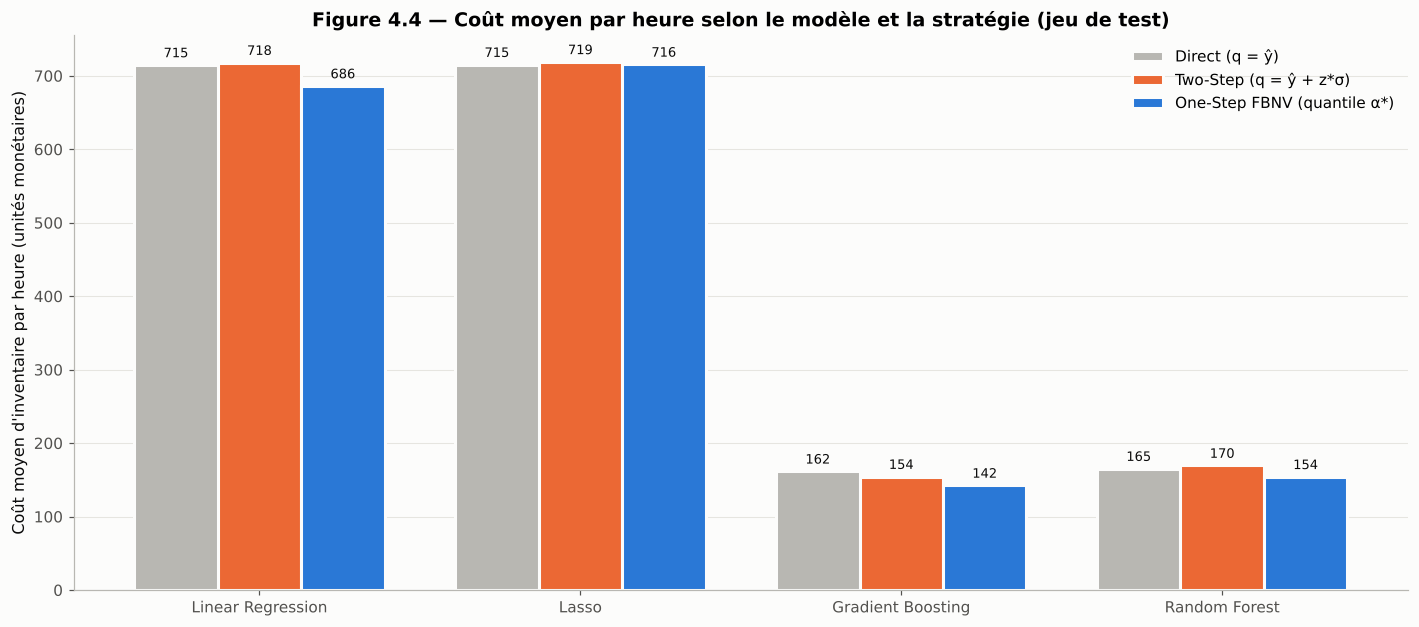

In [31]:
# ============================================================================
# 4.4 TROIS STRATÉGIES DE COMMANDE SUR LE JEU DE TEST
# ============================================================================
def kpi(y, q):
    y, q = np.asarray(y, float), np.asarray(q, float)
    c = cout_newsvendor(y, q)
    return {"Coût moyen par heure": c.mean(), "Coût total (test)": c.sum(),
            "Taux de service": (y <= q).mean(), "Rupture moyenne (vélos/h)": np.maximum(y - q, 0).mean(),
            "Sur-stock moyen (vélos/h)": np.maximum(q - y, 0).mean(), "Commande moyenne (vélos/h)": q.mean()}


# --- Prévisions ponctuelles (Direct et Two-Step) ---
prevision = {
    "LR": make_pipeline(StandardScaler(), LinearRegression()),
    "LA": make_pipeline(StandardScaler(), Lasso(alpha=ALPHA_LASSO, random_state=RANDOM_STATE)),
    "GB": GradientBoostingRegressor(random_state=RANDOM_STATE, **recherches["Gradient Boosting"].best_params_),
    "RF": RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **recherches["Random Forest"].best_params_),
}
d_hat, sigma_oof, sigma_train = {}, {}, {}
for nom, mod in prevision.items():
    pred_oof = cross_val_predict(mod, Xtr, ytr, cv=kf)
    sigma_oof[nom] = np.std(ytr.values - pred_oof)
    mod.fit(Xtr, ytr)
    sigma_train[nom] = np.std(ytr.values - mod.predict(Xtr))
    d_hat[nom] = mod.predict(Xte)

q_direct = {n: np.maximum(d_hat[n], 0) for n in prevision}
q_two = {n: np.maximum(d_hat[n] + Z_STAR * sigma_oof[n], 0) for n in prevision}

# --- One-Step FBNV ---
t0 = time.time()
lr_fb = make_pipeline(StandardScaler(), QuantileRegressor(quantile=ALPHA_STAR, alpha=0.0, solver="highs")).fit(Xtr, ytr)
la_fb = make_pipeline(StandardScaler(), QuantileRegressor(quantile=ALPHA_STAR, alpha=0.05, solver="highs")).fit(Xtr, ytr)
pinball_scorer = make_scorer(mean_pinball_loss, alpha=ALPHA_STAR, greater_is_better=False)
gs_gbq = GridSearchCV(GradientBoostingRegressor(loss="quantile", alpha=ALPHA_STAR, random_state=RANDOM_STATE),
                      {"n_estimators": [300, 600], "max_depth": [6, 8], "learning_rate": [0.05, 0.1],
                       "min_samples_leaf": [5]},
                      cv=kf, scoring=pinball_scorer, n_jobs=-1).fit(Xtr, ytr)
gb_fb = gs_gbq.best_estimator_
print(f"Modèles One-Step entraînés en {time.time() - t0:.0f} s ; GB quantile optimal : {gs_gbq.best_params_}")

rf_fb = prevision["RF"]                                   # forêt optimisée (4.2), déjà entraînée
preds_arbres = np.stack([arbre.predict(Xte.values) for arbre in rf_fb.estimators_])   # (n_arbres, n_test)

# Variante : Quantile Regression Forest (Meinshausen, 2006) – poids de co-appartenance aux feuilles
feuilles_tr, feuilles_te = rf_fb.apply(Xtr), rf_fb.apply(Xte)
W_qrf = np.zeros((len(Xte), len(Xtr)))
for t in range(feuilles_tr.shape[1]):
    meme = feuilles_te[:, t][:, None] == feuilles_tr[:, t][None, :]
    W_qrf += meme / meme.sum(axis=1, keepdims=True)
W_qrf /= feuilles_tr.shape[1]
ordre_y = np.argsort(ytr.values)
W_cum = np.cumsum(W_qrf[:, ordre_y], axis=1)
y_trie = ytr.values[ordre_y]


def qrf_quantile(alpha):
    return y_trie[np.argmax(W_cum >= alpha - 1e-12, axis=1)]


q_one = {
    "LR": np.maximum(lr_fb.predict(Xte), 0),
    "LA": np.maximum(la_fb.predict(Xte), 0),
    "GB": np.maximum(gb_fb.predict(Xte), 0),
    "RF": np.quantile(preds_arbres, ALPHA_STAR, axis=0),
}
q_qrf = qrf_quantile(ALPHA_STAR)

noms_longs = {"LR": "Linear Regression", "LA": "Lasso", "GB": "Gradient Boosting", "RF": "Random Forest"}
lignes = []
for n in prevision:
    for strat, q in [("Direct (q = ŷ)", q_direct[n]), ("Two-Step (q = ŷ + z*σ)", q_two[n]),
                     ("One-Step FBNV (quantile α*)", q_one[n])]:
        lignes.append({"Modèle": noms_longs[n], "Stratégie": strat, **kpi(yte, q)})
lignes.append({"Modèle": "Random Forest", "Stratégie": "One-Step FBNV (variante QRF Meinshausen)", **kpi(yte, q_qrf)})
tab_strat = pd.DataFrame(lignes)
ref_two = tab_strat[tab_strat["Stratégie"].str.startswith("Two")].set_index("Modèle")["Coût moyen par heure"]
tab_strat["Écart vs Two-Step"] = tab_strat.apply(
    lambda r: r["Coût moyen par heure"] / ref_two[r["Modèle"]] - 1, axis=1)
afficher_tableau(
    tab_strat, "Tableau 4.4 — Comparaison des stratégies de commande sur le jeu de test (1 361 heures, b = 10, h = 4)",
    formats={"Coût moyen par heure": "{:.2f}", "Coût total (test)": "{:,.0f}", "Taux de service": "{:.1%}",
             "Rupture moyenne (vélos/h)": "{:.2f}", "Sur-stock moyen (vélos/h)": "{:.2f}",
             "Commande moyenne (vélos/h)": "{:.1f}", "Écart vs Two-Step": "{:+.2%}"},
    degrade=["Coût moyen par heure"], cmap="RdYlGn_r", index=False)

sig = pd.DataFrame({"σ résidus train (biaisé)": sigma_train, "σ résidus out-of-fold (retenu)": sigma_oof})
sig["Stock de sécurité z*σ (vélos)"] = Z_STAR * sig["σ résidus out-of-fold (retenu)"]
sig.index = [noms_longs[n] for n in sig.index]
afficher_tableau(sig, "Tableau 4.4b — Estimation du σ du Two-Step : résidus d'apprentissage vs out-of-fold",
                 formats="{:.2f}")

# Reproduction de la version initiale du notebook (GB par défaut, σ des résidus d'apprentissage)
gb_def = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(Xtr, ytr)
q_two_init = gb_def.predict(Xte) + Z_STAR * np.std(ytr.values - gb_def.predict(Xtr))
gb_def_q = GradientBoostingRegressor(loss="quantile", alpha=ALPHA_STAR, random_state=RANDOM_STATE).fit(Xtr, ytr)
q_one_init = gb_def_q.predict(Xte)
init = pd.DataFrame({
    "Configuration": ["Version initiale : GB par défaut, σ d'apprentissage", "Version initiale : GB quantile par défaut",
                      "Version finale : GB optimisé, σ out-of-fold", "Version finale : GB quantile optimisé (Pinball)"],
    "Stratégie": ["Two-Step", "One-Step FBNV", "Two-Step", "One-Step FBNV"],
    "Coût moyen par heure": [cout_newsvendor(yte, q_two_init).mean(), cout_newsvendor(yte, q_one_init).mean(),
                             cout_newsvendor(yte, q_two["GB"]).mean(), cout_newsvendor(yte, q_one["GB"]).mean()],
})
init["Réduction de coût (One-Step vs Two-Step)"] = ["—", f"{1 - init.iloc[1, 2] / init.iloc[0, 2]:+.2%}",
                                     "—", f"{1 - init.iloc[3, 2] / init.iloc[2, 2]:+.2%}"]
afficher_tableau(init, "Tableau 4.4c — Du notebook initial au notebook final : effet de l'optimisation (Gradient Boosting)",
                 formats={"Coût moyen par heure": "{:.2f}"}, index=False)

# Figure : coût moyen par modèle et par stratégie
fig, ax = plt.subplots(figsize=(13, 5.8))
strats = ["Direct (q = ŷ)", "Two-Step (q = ŷ + z*σ)", "One-Step FBNV (quantile α*)"]
coul_s = [COULEURS["gris"], COULEURS["orange"], COULEURS["bleu"]]
largeur = 0.26
x0 = np.arange(4)
for k, (s_, c) in enumerate(zip(strats, coul_s)):
    vals = [tab_strat[(tab_strat["Modèle"] == noms_longs[n]) & (tab_strat["Stratégie"] == s_)]["Coût moyen par heure"].iloc[0]
            for n in prevision]
    ax.bar(x0 + (k - 1) * largeur, vals, width=largeur, color=c, label=s_, edgecolor=COULEURS["fond"], linewidth=2)
annoter_barres(ax, fmt="{:.0f}", taille=8.5)
ax.set_xticks(x0, [noms_longs[n] for n in prevision])
ax.set_ylabel("Coût moyen d'inventaire par heure (unités monétaires)")
ax.set_title("Figure 4.4 — Coût moyen par heure selon le modèle et la stratégie (jeu de test)")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.tight_layout()
sauver_figure(fig, "fig_4_4_strategies")
plt.show()

**Finding (Constats chiffrés)**

| Modèle | Direct | Two-Step | **One-Step FBNV** | Variation One-Step vs Two-Step |
|---|---|---|---|---|
| Linear Regression | 714,82 | 718,03 | **686,23** | **-4,43 %** |
| Lasso | 715,23 | 719,02 | **715,59** | -0,48 % |
| Gradient Boosting | 161,65 | 154,42 | **142,44** | **-7,76 %** |
| Random Forest | 165,30 | 169,53 | **154,18** | **-9,05 %** |
| Random Forest (QRF Meinshausen) | | | 153,56 | -9,42 % |

*(coût moyen d'inventaire par heure sur les 1 361 heures de test, $b = 10$, $h = 4$)*

* **Le One-Step FBNV est la stratégie la moins coûteuse pour les quatre familles de modèles.** Le coût minimal est atteint par **GB+FB : 142,44 par heure** (193 855 sur l'ensemble du test).
* **Taux de service :** la stratégie Direct ne sert la demande que dans 50 à 59 % des heures. Le Two-Step **sur-sert** (79 à 83 %, au-delà de la cible de 71,4 %), au prix d'un sur-stock moyen de 26 à 30 vélos/h pour les arbres. Le One-Step se rapproche de la cible : **72,2 %** (LR+FB), **73,3 %** (RF+FB), **67,7 %** (GB+FB).
* **Estimation de σ (Tableau 4.4b) :** pour les arbres, le σ des résidus d'apprentissage (15,3 à 15,6) est **2,5 à 2,8 fois plus faible** que le σ out-of-fold (38,5 à 42,5). Le stock de sécurité Two-Step retenu vaut 21,8 vélos (GB) et 24,0 vélos (RF), contre 80,3 vélos pour les modèles linéaires.
* **Du notebook initial au notebook final (Tableau 4.4c) :** avec le Gradient Boosting par défaut et le σ d'apprentissage (version initiale), on retrouve les chiffres attendus, **317,27 → 288,92**, soit **-8,94 %**. Après optimisation, les deux stratégies deviennent deux fois moins coûteuses (**154,42 → 142,44**, soit -7,76 %).

**Insights (Interprétation métier et lien avec l'article)**
* La thèse centrale de Jing Shi est confirmée : **à modèle de prévision égal, passer de deux étapes à une seule réduit le coût d'inventaire** (Tableau 9 de l'article). Le gain est le plus fort pour les modèles les plus flexibles (-7,8 % et -9,1 %), car ce sont eux qui savent moduler le quantile selon le contexte.
* **La précision prime d'abord :** passer d'un modèle linéaire à un ensemble d'arbres divise le coût par **4,6** (718 → 154). L'article fait le même constat (« improving the prediction accuracy … can also reduce costs »). Le FBNV est un **second levier**, qui s'ajoute au premier.
* **Le Two-Step avec forêt aléatoire est pire que le Direct** (169,53 contre 165,30) : la marge fixe de 24 vélos est trop forte la nuit, où la demande vaut quelques vélos. C'est la conséquence directe de l'hétéroscédasticité diagnostiquée en 3.3.
* Le gain du Lasso quantile est faible (-0,5 %) : la pénalité $L_1$ (`alpha = 0,05`) écrase une partie des coefficients et limite la capacité du modèle à déplacer son quantile. La régression quantile non pénalisée (LR+FB) est préférable ici.
* La QRF de Meinshausen fait très légèrement mieux (153,56) que le quantile des prédictions d'arbres (154,18) : les deux approximations du quantile conditionnel sont équivalentes en pratique.
* Le GB+FB sert un peu moins que la cible (67,7 % contre 71,4 %) : le boosting quantile est légèrement **sous-calibré**. Malgré cela, c'est lui qui minimise le coût : il place ses marges là où elles sont rentables (voir Étape 5.5).

## 4.5 Analyse de sensibilité au ratio critique $b/(b+h)$

**Pourquoi ?** Les coûts $b = 10$ et $h = 4$ sont des hypothèses. Un gestionnaire veut savoir si la supériorité du One-Step tient **quel que soit** l'arbitrage économique. On fait varier le fractile critique $\alpha = b/(b+h)$ de **0,10** (rupture peu coûteuse, sur-stock très coûteux) à **0,95** (rupture très coûteuse), en gardant $b + h = 14$ pour que les coûts restent comparables : $b = 14\alpha$, $h = 14(1-\alpha)$. Le cas de référence ($b = 10$, $h = 4$) correspond à $\alpha \approx 0,714$.

Pour chaque $\alpha$, on recalcule les commandes Two-Step ($\hat{d} + \Phi^{-1}(\alpha)\,\sigma$) et One-Step (quantile d'ordre $\alpha$) pour la régression linéaire, le Gradient Boosting (ré-entraîné pour chaque $\alpha$ avec les hyperparamètres optimaux de 4.4) et la Random Forest.

36 modèles quantiles ré-entraînés en 115 s


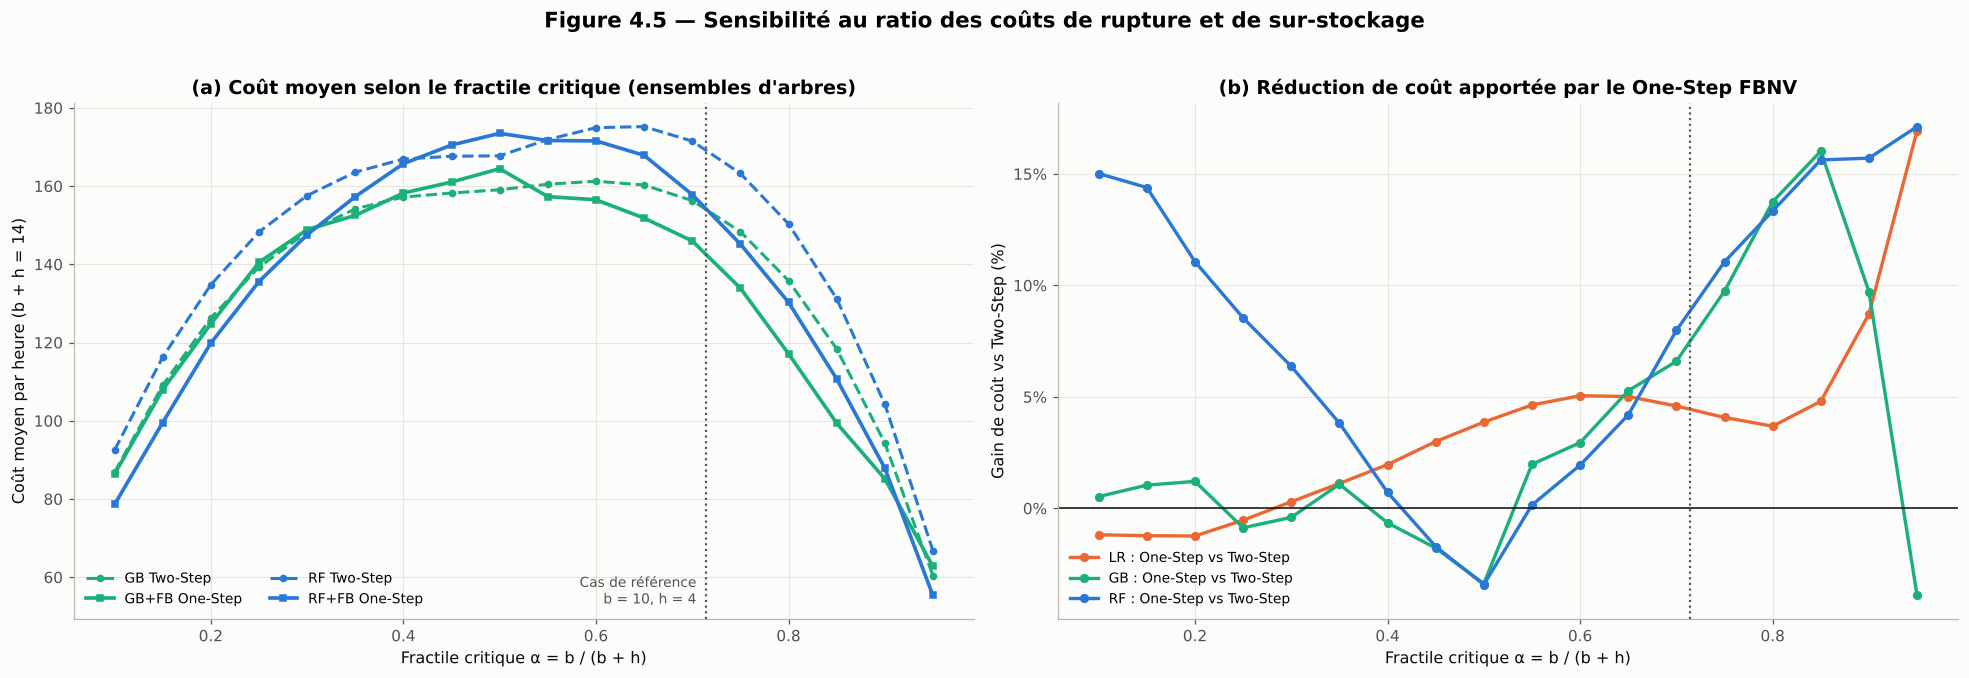

α = b/(b+h),b,h,z(α),LR Two-Step,LR+FB One-Step,GB Two-Step,GB+FB One-Step,RF Two-Step,RF+FB One-Step,Gain LR (%),Gain GB (%),Gain RF (%)
0.10,1.4,12.6,-1.282,217.44,220.02,86.84,86.38,92.48,78.60,-1.2 %,+0.5 %,+15.0 %
0.15,2.1,11.9,-1.036,307.77,311.55,109.06,107.93,116.28,99.55,-1.2 %,+1.0 %,+14.4 %
0.20,2.8,11.2,-0.842,389.08,393.92,126.28,124.76,134.77,119.87,-1.2 %,+1.2 %,+11.1 %
0.25,3.5,10.5,-0.674,464.80,467.28,139.28,140.50,148.26,135.60,-0.5 %,-0.9 %,+8.5 %
0.30,4.2,9.8,-0.524,532.12,530.56,148.26,148.86,157.58,147.55,+0.3 %,-0.4 %,+6.4 %
0.35,4.9,9.1,-0.385,590.87,584.28,154.17,152.51,163.56,157.31,+1.1 %,+1.1 %,+3.8 %
0.40,5.6,8.4,-0.253,641.37,628.81,157.20,158.22,166.92,165.73,+2.0 %,-0.7 %,+0.7 %
0.45,6.3,7.7,-0.126,684.33,663.85,158.22,161.04,167.62,170.50,+3.0 %,-1.8 %,-1.7 %
0.50,7.0,7.0,+0.000,717.08,689.36,159.07,164.44,167.75,173.49,+3.9 %,-3.4 %,-3.4 %
0.55,7.7,6.3,+0.126,739.32,705.06,160.47,157.31,171.90,171.65,+4.6 %,+2.0 %,+0.1 %


Nombre de valeurs de α (sur 18) où le One-Step bat le Two-Step : {'LR': 14, 'GB': 12, 'RF': 16}


In [32]:
# ============================================================================
# 4.5 ANALYSE DE SENSIBILITÉ AU FRACTILE CRITIQUE
# ============================================================================
alphas_sens = np.round(np.arange(0.10, 0.951, 0.05), 2)
params_gbq = gs_gbq.best_params_


def fit_gbq(a):
    return GradientBoostingRegressor(loss="quantile", alpha=a, random_state=RANDOM_STATE, **params_gbq).fit(Xtr, ytr).predict(Xte)


def fit_lrq(a):
    return make_pipeline(StandardScaler(), QuantileRegressor(quantile=a, alpha=0.0, solver="highs")).fit(Xtr, ytr).predict(Xte)


t0 = time.time()
q_gb_sens = Parallel(n_jobs=-1)(delayed(fit_gbq)(a) for a in alphas_sens)
q_lr_sens = Parallel(n_jobs=-1)(delayed(fit_lrq)(a) for a in alphas_sens)
print(f"{2 * len(alphas_sens)} modèles quantiles ré-entraînés en {time.time() - t0:.0f} s")

sens = []
for i, a in enumerate(alphas_sens):
    b_a, h_a = 14 * a, 14 * (1 - a)
    z_a = stats.norm.ppf(a)
    c = lambda q: cout_newsvendor(yte, np.maximum(q, 0), b_a, h_a).mean()
    sens.append({"α = b/(b+h)": a, "b": b_a, "h": h_a, "z(α)": z_a,
                 "LR Two-Step": c(d_hat["LR"] + z_a * sigma_oof["LR"]), "LR+FB One-Step": c(q_lr_sens[i]),
                 "GB Two-Step": c(d_hat["GB"] + z_a * sigma_oof["GB"]), "GB+FB One-Step": c(q_gb_sens[i]),
                 "RF Two-Step": c(d_hat["RF"] + z_a * sigma_oof["RF"]),
                 "RF+FB One-Step": c(np.quantile(preds_arbres, a, axis=0))})
tab_sens = pd.DataFrame(sens)
for m in ["LR", "GB", "RF"]:
    one = f"{m}+FB One-Step"
    tab_sens[f"Gain {m} (%)"] = (1 - tab_sens[one] / tab_sens[f"{m} Two-Step"]) * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
ax = axes[0]
for m, c in [("GB", COULEURS["vert_eau"]), ("RF", COULEURS["bleu"])]:
    ax.plot(alphas_sens, tab_sens[f"{m} Two-Step"], color=c, ls="--", lw=2, marker="o", ms=4, label=f"{m} Two-Step")
    ax.plot(alphas_sens, tab_sens[f"{m}+FB One-Step"], color=c, lw=2.4, marker="s", ms=4, label=f"{m}+FB One-Step")
ax.axvline(ALPHA_STAR, color=COULEURS["encre_2"], ls=":", lw=1.4)
ax.text(ALPHA_STAR - 0.01, 0.03, "Cas de référence\nb = 10, h = 4", transform=ax.get_xaxis_transform(),
        ha="right", fontsize=9, color=COULEURS["encre_2"])
ax.set_title("(a) Coût moyen selon le fractile critique (ensembles d'arbres)")
ax.set_xlabel("Fractile critique α = b / (b + h)")
ax.set_ylabel("Coût moyen par heure (b + h = 14)")
ax.legend(fontsize=9, ncol=2)

ax = axes[1]
for m, c in [("LR", COULEURS["orange"]), ("GB", COULEURS["vert_eau"]), ("RF", COULEURS["bleu"])]:
    ax.plot(alphas_sens, tab_sens[f"Gain {m} (%)"], color=c, lw=2.2, marker="o", ms=5, label=f"{m} : One-Step vs Two-Step")
ax.axhline(0, color=COULEURS["encre"], lw=1)
ax.axvline(ALPHA_STAR, color=COULEURS["encre_2"], ls=":", lw=1.4)
ax.set_title("(b) Réduction de coût apportée par le One-Step FBNV")
ax.set_xlabel("Fractile critique α = b / (b + h)")
ax.set_ylabel("Gain de coût vs Two-Step (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(fontsize=9)
fig.suptitle("Figure 4.5 — Sensibilité au ratio des coûts de rupture et de sur-stockage",
             fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_4_5_sensibilite")
plt.show()

afficher_tableau(
    tab_sens, "Tableau 4.5 — Coût moyen par heure selon le fractile critique (jeu de test, b + h = 14)",
    formats={"α = b/(b+h)": "{:.2f}", "b": "{:.1f}", "h": "{:.1f}", "z(α)": "{:+.3f}"}
    | {c: "{:.2f}" for c in tab_sens.columns if "Step" in c} | {c: "{:+.1f} %" for c in tab_sens.columns if "Gain" in c},
    post=lambda s: s.background_gradient(subset=[c for c in tab_sens.columns if "Gain" in c], cmap="RdYlGn",
                                         vmin=-20, vmax=20), index=False)
nb_gagnant = {m: int((tab_sens[f"Gain {m} (%)"] > 0).sum()) for m in ["LR", "GB", "RF"]}
print(f"Nombre de valeurs de α (sur {len(alphas_sens)}) où le One-Step bat le Two-Step : {nb_gagnant}")

**Finding (Constats chiffrés)**
* Sur les **18 valeurs** de $\alpha$ testées (0,10 à 0,95), le One-Step FBNV bat le Two-Step dans **16 cas pour la forêt aléatoire**, **14 cas pour la régression linéaire** et **12 cas pour le Gradient Boosting**.
* **Rupture chère (α ≥ 0,70) :** le gain du FBNV est systématique et important pour les ensembles d'arbres : de **+8,0 % à +17,1 %** pour la forêt, de **+6,6 % à +16,0 %** pour le boosting entre α = 0,70 et α = 0,90, et de **+3,7 % à +16,9 %** pour la régression linéaire.
* **Sur-stock cher (α ≤ 0,20) :** la forêt gagne encore nettement (**+11,1 % à +15,0 %**), le boosting très légèrement (+0,5 % à +1,2 %), tandis que la régression linéaire perd un peu (-1,2 %).
* **Coûts quasi symétriques (α entre 0,40 et 0,50) :** les deux stratégies se valent et le Two-Step gagne légèrement (jusqu'à -3,4 % pour GB et RF à α = 0,50).
* **Cas de référence (α ≈ 0,71) :** gains de **4,6 % (LR)**, **6,6 % (GB)** et **8,0 % (RF)** sur la grille à α = 0,70.
* Le coût maximal est atteint vers α ≈ 0,5-0,65 : c'est quand la rupture et le sur-stock coûtent autant que l'incertitude coûte le plus.

**Insights (Interprétation métier et lien avec l'article)**
* Le FBNV est d'autant plus utile que **l'asymétrie des coûts est forte**. C'est logique : à α = 0,5, le quantile optimal est la médiane, proche de la moyenne prédite par le Two-Step, et les deux approches convergent. Plus α s'éloigne de 0,5, plus la **forme** de la distribution conditionnelle compte, et plus l'hypothèse gaussienne homoscédastique se trompe.
* Pour un opérateur de vélos, une rupture (client perdu, image dégradée) coûte en pratique bien plus qu'un vélo immobilisé : on se situe dans la zone α > 0,7, où le gain du FBNV est **maximal et robuste**.
* Le seul point défavorable notable (GB à α = 0,95, -3,9 %) s'explique par la difficulté d'apprendre un quantile très extrême avec un boosting : peu d'observations dépassent le quantile 95 %. Une piste d'amélioration serait de ré-optimiser les hyperparamètres du boosting pour chaque α, au lieu de réutiliser ceux trouvés à α = 0,7143.

---
# ÉTAPE 5 — Production : Tableaux 8 et 9, décisions de commande et livrables

| # | Micro-étape | Correspondance avec l'article |
|---|---|---|
| 5.1 | Tableau 8 : métriques de prévision sur le jeu de test | Tableau 8 |
| 5.2 | Importance des variables (MDI et permutation) | §4.3.3 (IncMSE) |
| 5.3 | Réel vs prédit | Fig. 6, 7, 8 et 9 |
| 5.4 | Tableau 9 : coûts d'inventaire sur 10 sous-périodes | Tableau 9 |
| 5.5 | Décision de commande $q^*$ et erreur selon l'heure | Extension métier |
| 5.6 | Export Excel pour le rendu Moodle | Livrable « base de données (excel) » |
| 5.7 | Conclusion générale | §6 |

## 5.1 Reproduction du Tableau 8 : métriques de prévision sur le jeu de test

**Pourquoi ?** Le Tableau 8 de l'article évalue chaque modèle sur le jeu de test avec quatre indicateurs : RMSE, MAE, MSE et $R^2$. On le reproduit pour les 9 modèles du benchmark, chacun ré-entraîné sur les 9 525 heures d'entraînement (avec les hyperparamètres optimisés en 4.2 pour GB et RF), puis évalué **une seule fois** sur les 1 361 heures de test restées sous scellé. On rappelle les valeurs de l'article pour les trois modèles qu'il étudie.

In [33]:
# ============================================================================
# 5.1 TABLEAU 8 (JEU DE TEST)
# ============================================================================
modeles_finaux = dict(modeles)
modeles_finaux["Gradient Boosting"] = GradientBoostingRegressor(random_state=RANDOM_STATE,
                                                                **recherches["Gradient Boosting"].best_params_)
modeles_finaux["Random Forest"] = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1,
                                                        **recherches["Random Forest"].best_params_)
pred_test, lignes8 = {}, []
for nom, mod in modeles_finaux.items():
    pipe = make_pipeline(StandardScaler(), mod).fit(Xtr, ytr)
    p = pipe.predict(Xte)
    pred_test[nom] = p
    lignes8.append({"Modèle": nom + (" (optimisé)" if nom in ("Gradient Boosting", "Random Forest") else ""),
                    "RMSE": np.sqrt(mean_squared_error(yte, p)), "MAE": mean_absolute_error(yte, p),
                    "MSE": mean_squared_error(yte, p), "R²": r2_score(yte, p)})
tab8 = pd.DataFrame(lignes8).sort_values("RMSE").reset_index(drop=True)
tab8.index = tab8.index + 1
afficher_tableau(tab8, "Tableau 8 (reproduction) — Évaluation des modèles sur le jeu de test (1 361 heures)",
                 formats={"RMSE": "{:.2f}", "MAE": "{:.2f}", "MSE": "{:,.0f}", "R²": "{:.4f}"},
                 degrade=["RMSE"], cmap="RdYlGn_r",
                 post=lambda s: s.background_gradient(subset=["R²"], cmap="RdYlGn"))

t8 = tab8.set_index("Modèle")
article8 = pd.DataFrame({
    "R² article (BMW)": [0.683, 0.692, 0.716],
    "R² TP (Bike Sharing)": [t8.loc["Linear Regression", "R²"], t8.loc["Lasso (α = 0,5)", "R²"],
                             t8.loc["Random Forest (optimisé)", "R²"]],
    "Rang article": [3, 2, 1],
    "Rang TP (parmi ces 3)": pd.Series([t8.loc["Linear Regression", "RMSE"], t8.loc["Lasso (α = 0,5)", "RMSE"],
                                        t8.loc["Random Forest (optimisé)", "RMSE"]]).rank().astype(int).values,
}, index=["Linear Regression", "Lasso", "Random Forest"])
afficher_tableau(article8, "Tableau 8b — Confrontation avec le Tableau 8 de Jing Shi (2022)",
                 formats={"R² article (BMW)": "{:.3f}", "R² TP (Bike Sharing)": "{:.3f}"})

,Modèle,RMSE,MAE,MSE,R²
1,Gradient Boosting (optimisé),37.11,22.97,"1,377",0.9582
2,Random Forest (optimisé),40.11,24.00,"1,609",0.9511
3,"KNN (k = 7, pondéré)",103.93,69.11,"10,801",0.6718
4,"SVR (RBF, C = 300)",113.19,66.61,"12,812",0.6107
5,Polynomiale (degré 2),121.73,90.79,"14,819",0.5497
6,Ridge (α = 1),140.54,104.01,"19,750",0.3999
7,Linear Regression,140.54,104.01,"19,751",0.3999
8,"Lasso (α = 0,5)",140.54,103.94,"19,751",0.3998
9,"ElasticNet (α = 0,5 ; L1 = 0,5)",141.64,104.15,"20,063",0.3904


,R² article (BMW),R² TP (Bike Sharing),Rang article,Rang TP (parmi ces 3)
Linear Regression,0.683,0.400,3,2
Lasso,0.692,0.400,2,3
Random Forest,0.716,0.951,1,1


**Finding (Constats chiffrés)**

| Rang | Modèle | RMSE | MAE | MSE | R² |
|---|---|---|---|---|---|
| 1 | **Gradient Boosting (optimisé)** | **37,11** | **22,97** | **1 377** | **0,958** |
| 2 | Random Forest (optimisé) | 40,11 | 24,00 | 1 609 | 0,951 |
| 3 | KNN (k = 7) | 103,93 | 69,11 | 10 801 | 0,672 |
| 4 | SVR (RBF) | 113,19 | 66,61 | 12 812 | 0,611 |
| 5 | Polynomiale degré 2 | 121,73 | 90,79 | 14 819 | 0,550 |
| 6-8 | Ridge / OLS / Lasso | 140,54 | 103,9 à 104,0 | 19 750 | 0,400 |
| 9 | ElasticNet | 141,64 | 104,15 | 20 063 | 0,390 |

* Les performances sur le test sont **cohérentes avec la validation croisée** (RF : 40,11 en test contre 42,46 en CV ; GB : 37,11 contre 38,52 ; OLS : 140,54 contre 141,89) : aucun sur-apprentissage au protocole.
* Face au Tableau 8 de l'article (BMW) : la forêt obtient $R^2 = 0,716$ dans l'article contre **0,951** ici ; les modèles linéaires 0,683 et 0,692 contre 0,400.

**Insights (Interprétation métier et lien avec l'article)**
* Le **classement de l'article est reproduit** : la forêt aléatoire domine nettement les modèles linéaires. La seule nuance est l'ordre LR / Lasso, qui sont ici à égalité (140,54 tous les deux) alors que le Lasso devance légèrement la LR dans l'article.
* L'écart entre familles est bien plus marqué ici : les ventes mensuelles de BMW suivent des tendances macro-économiques assez lisses, alors que la demande horaire de vélos est dominée par des **interactions non linéaires** (heure × type de jour). C'est une limite de la transposition à signaler dans le rapport, et en même temps un argument pour le choix des ensembles d'arbres.
* Le Gradient Boosting optimisé devient le meilleur prévisionniste (+0,7 point de $R^2$ sur la forêt), ce qui confirme l'importance de la phase de *fine-tuning* (Étape 4.2).

## 5.2 Importance des variables : MDI et importance par permutation

**Pourquoi ?** L'article mesure l'importance des variables de la forêt par l'**IncMSE** (augmentation de l'erreur quand on permute une variable, §4.3.3). On calcule deux mesures complémentaires sur la forêt optimisée :
* **MDI** (*Mean Decrease in Impurity*) : la réduction totale de variance apportée par les coupures sur chaque variable, calculée à l'apprentissage. Rapide, mais biaisée en faveur des variables continues à nombreuses modalités ;
* **Importance par permutation** sur le jeu de **test** (10 répétitions) : la hausse du RMSE quand on mélange aléatoirement une variable, ce qui détruit son lien avec la demande. C'est l'équivalent direct de l'IncMSE de l'article, et elle mesure l'utilité **hors échantillon**.

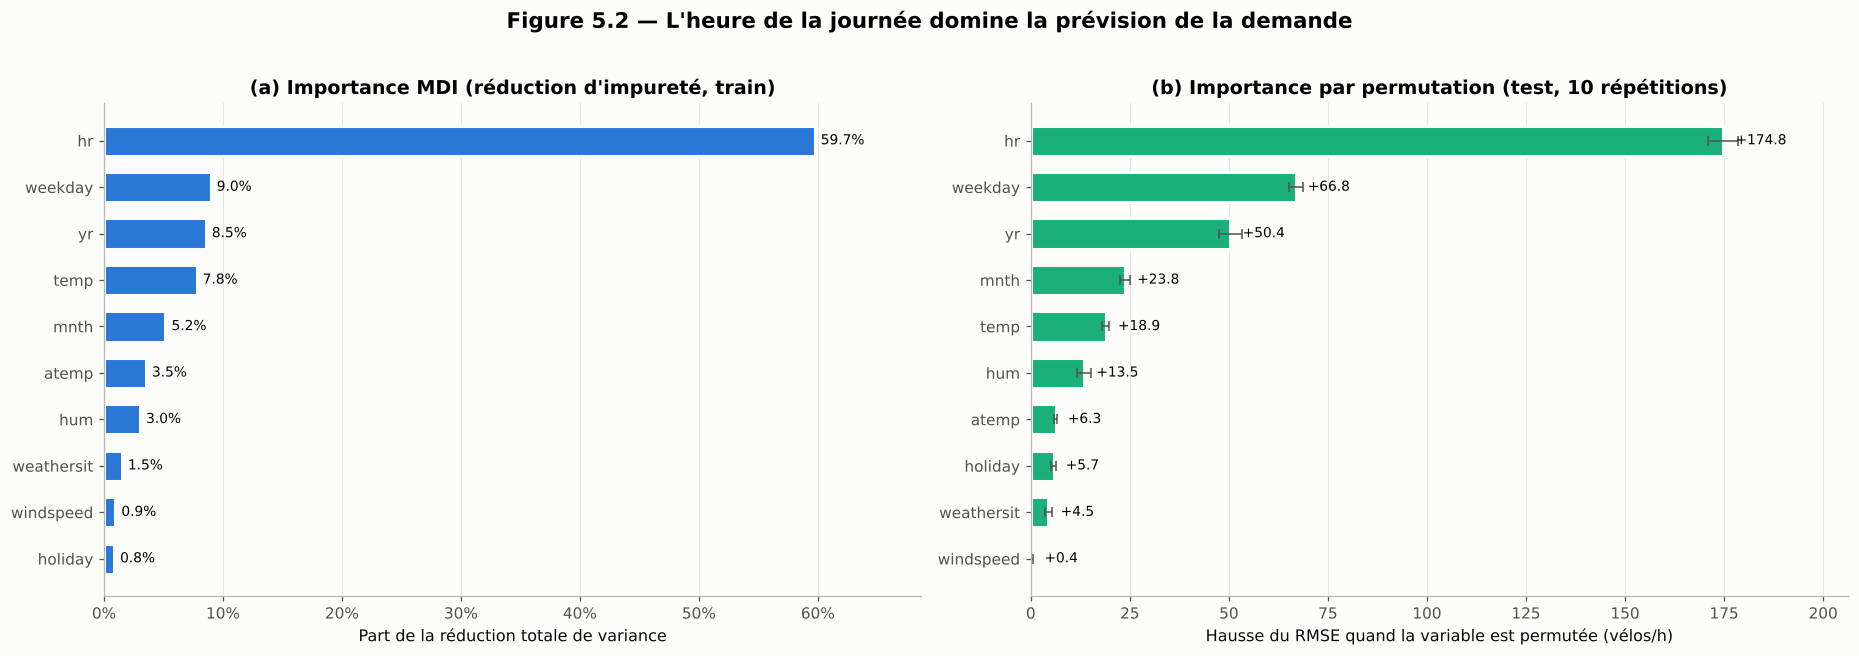

,MDI,Rang MDI,Permutation : hausse du RMSE (vélos/h),Écart-type (10 rép.),Permutation (part relative),Rang permutation
hr,59.7%,1,174.81,3.79,47.9%,1
weekday,9.0%,2,66.83,1.77,18.3%,2
yr,8.5%,3,50.40,2.80,13.8%,3
temp,7.8%,4,18.94,0.88,5.2%,5
mnth,5.2%,5,23.78,1.38,6.5%,4
atemp,3.5%,6,6.28,0.33,1.7%,7
hum,3.0%,7,13.47,1.72,3.7%,6
weathersit,1.5%,8,4.47,0.98,1.2%,9
windspeed,0.9%,9,0.37,0.21,0.1%,10
holiday,0.8%,10,5.74,0.68,1.6%,8


In [34]:
# ============================================================================
# 5.2 IMPORTANCE DES VARIABLES (RANDOM FOREST OPTIMISÉE)
# ============================================================================
rf_final = prevision["RF"]
mdi = pd.Series(rf_final.feature_importances_, index=variables_retenues)
perm = permutation_importance(rf_final, Xte, yte, n_repeats=10, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
perm_moy = pd.Series(perm.importances_mean, index=variables_retenues)
perm_std = pd.Series(perm.importances_std, index=variables_retenues)

imp = pd.DataFrame({"MDI": mdi, "Rang MDI": mdi.rank(ascending=False).astype(int),
                    "Permutation : hausse du RMSE (vélos/h)": perm_moy, "Écart-type (10 rép.)": perm_std,
                    "Permutation (part relative)": perm_moy.clip(lower=0) / perm_moy.clip(lower=0).sum(),
                    "Rang permutation": perm_moy.rank(ascending=False).astype(int)}).sort_values("MDI", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.8))
ax = axes[0]
o = imp["MDI"].sort_values()
ax.barh(o.index, o.values, color=COULEURS["bleu"], height=0.65, edgecolor=COULEURS["fond"], linewidth=2)
for y_, v in enumerate(o.values):
    ax.annotate(f"{v:.1%}", (v, y_), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlim(0, o.max() * 1.15)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("(a) Importance MDI (réduction d'impureté, train)")
ax.set_xlabel("Part de la réduction totale de variance")
ax.grid(axis="y", visible=False)

ax = axes[1]
o2 = imp["Permutation : hausse du RMSE (vélos/h)"].sort_values()
ax.barh(o2.index, o2.values, xerr=perm_std[o2.index].values, color=COULEURS["vert_eau"], height=0.65,
        edgecolor=COULEURS["fond"], linewidth=2, error_kw=dict(ecolor=COULEURS["encre_2"], lw=1, capsize=3))
for y_, v in enumerate(o2.values):
    ax.annotate(f"+{v:.1f}", (v, y_), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_xlim(0, o2.max() * 1.18)
ax.set_title("(b) Importance par permutation (test, 10 répétitions)")
ax.set_xlabel("Hausse du RMSE quand la variable est permutée (vélos/h)")
ax.grid(axis="y", visible=False)
fig.suptitle("Figure 5.2 — L'heure de la journée domine la prévision de la demande",
             fontweight="bold", fontsize=14, y=1.02)
plt.tight_layout()
sauver_figure(fig, "fig_5_2_importance_variables")
plt.show()

afficher_tableau(imp, "Tableau 5.2 — Importance des variables de la Random Forest optimisée",
                 formats={"MDI": "{:.1%}", "Permutation : hausse du RMSE (vélos/h)": "{:.2f}",
                          "Écart-type (10 rép.)": "{:.2f}", "Permutation (part relative)": "{:.1%}"},
                 degrade=["MDI", "Permutation : hausse du RMSE (vélos/h)"])

**Finding (Constats chiffrés)**

| Variable | MDI | Permutation : hausse du RMSE | Rang permutation |
|---|---|---|---|
| `hr` | **59,7 %** | **+174,8 vélos/h** | 1 |
| `weekday` | **9,0 %** | +66,8 | 2 |
| `yr` | **8,5 %** | +50,4 | 3 |
| `temp` | **7,8 %** | +18,9 | 5 |
| `mnth` | 5,2 % | +23,8 | 4 |
| `atemp` | 3,5 % | +6,3 | 7 |
| `hum` | 3,0 % | +13,5 | 6 |
| `weathersit`, `windspeed`, `holiday` | 0,8 à 1,5 % | +0,4 à +5,7 | 8 à 10 |

* On retrouve les valeurs attendues : **`hr` ≈ 59,8 %, `weekday` ≈ 8,9 %, `yr` ≈ 8,6 %, `temp` ≈ 7,7 %** (59,7 / 9,0 / 8,5 / 7,8 % ici, avec la forêt optimisée à 300 arbres).
* Les deux méthodes s'accordent sur le trio de tête (`hr`, `weekday`, `yr`). Mélanger `hr` sur le jeu de test fait passer le RMSE de 40 à **215 vélos/h**.

**Insights (Interprétation métier et lien avec l'article)**
* **L'heure explique à elle seule près de 60 % de la prévision.** Le planificateur doit donc raisonner d'abord en **profil horaire**, puis l'ajuster selon le jour de la semaine, la tendance annuelle et la météo.
* `weekday` est la 2ᵉ variable, alors que sa corrélation de Pearson avec la demande était nulle (Étape 2.2) et que son coefficient Lasso était le plus faible (+0,26). C'est la preuve que la forêt a reconstruit l'interaction `hr × type de jour` que le Lasso ne pouvait pas voir, et que l'élimination de `workingday` (Étape 2) n'a rien coûté.
* La permutation remonte `hum` et `mnth` par rapport au MDI, et fait chuter `atemp` : la paire `temp`/`atemp` étant redondante, permuter l'une ne coûte presque rien tant que l'autre est présente. On retrouve l'effet de la multicolinéarité de l'Étape 2.3. C'est pourquoi l'IncMSE (permutation) utilisé dans l'article est plus fiable que le MDI pour **décider** des variables à collecter.

## 5.3 Réel vs prédit : équivalent des Figures 6 à 9 de l'article

**Pourquoi ?** Les Figures 6, 7 et 8 de l'article comparent valeurs réelles et estimées pour le Lasso, la régression polynomiale et la forêt aléatoire ; la Figure 9 superpose les trois. On reproduit ces quatre figures sur le jeu de test : un nuage « réel vs prédit » par modèle (un modèle parfait aligne les points sur la diagonale $y = \hat{y}$), puis la superposition des trois modèles sur 72 heures de test consécutives dans le temps.

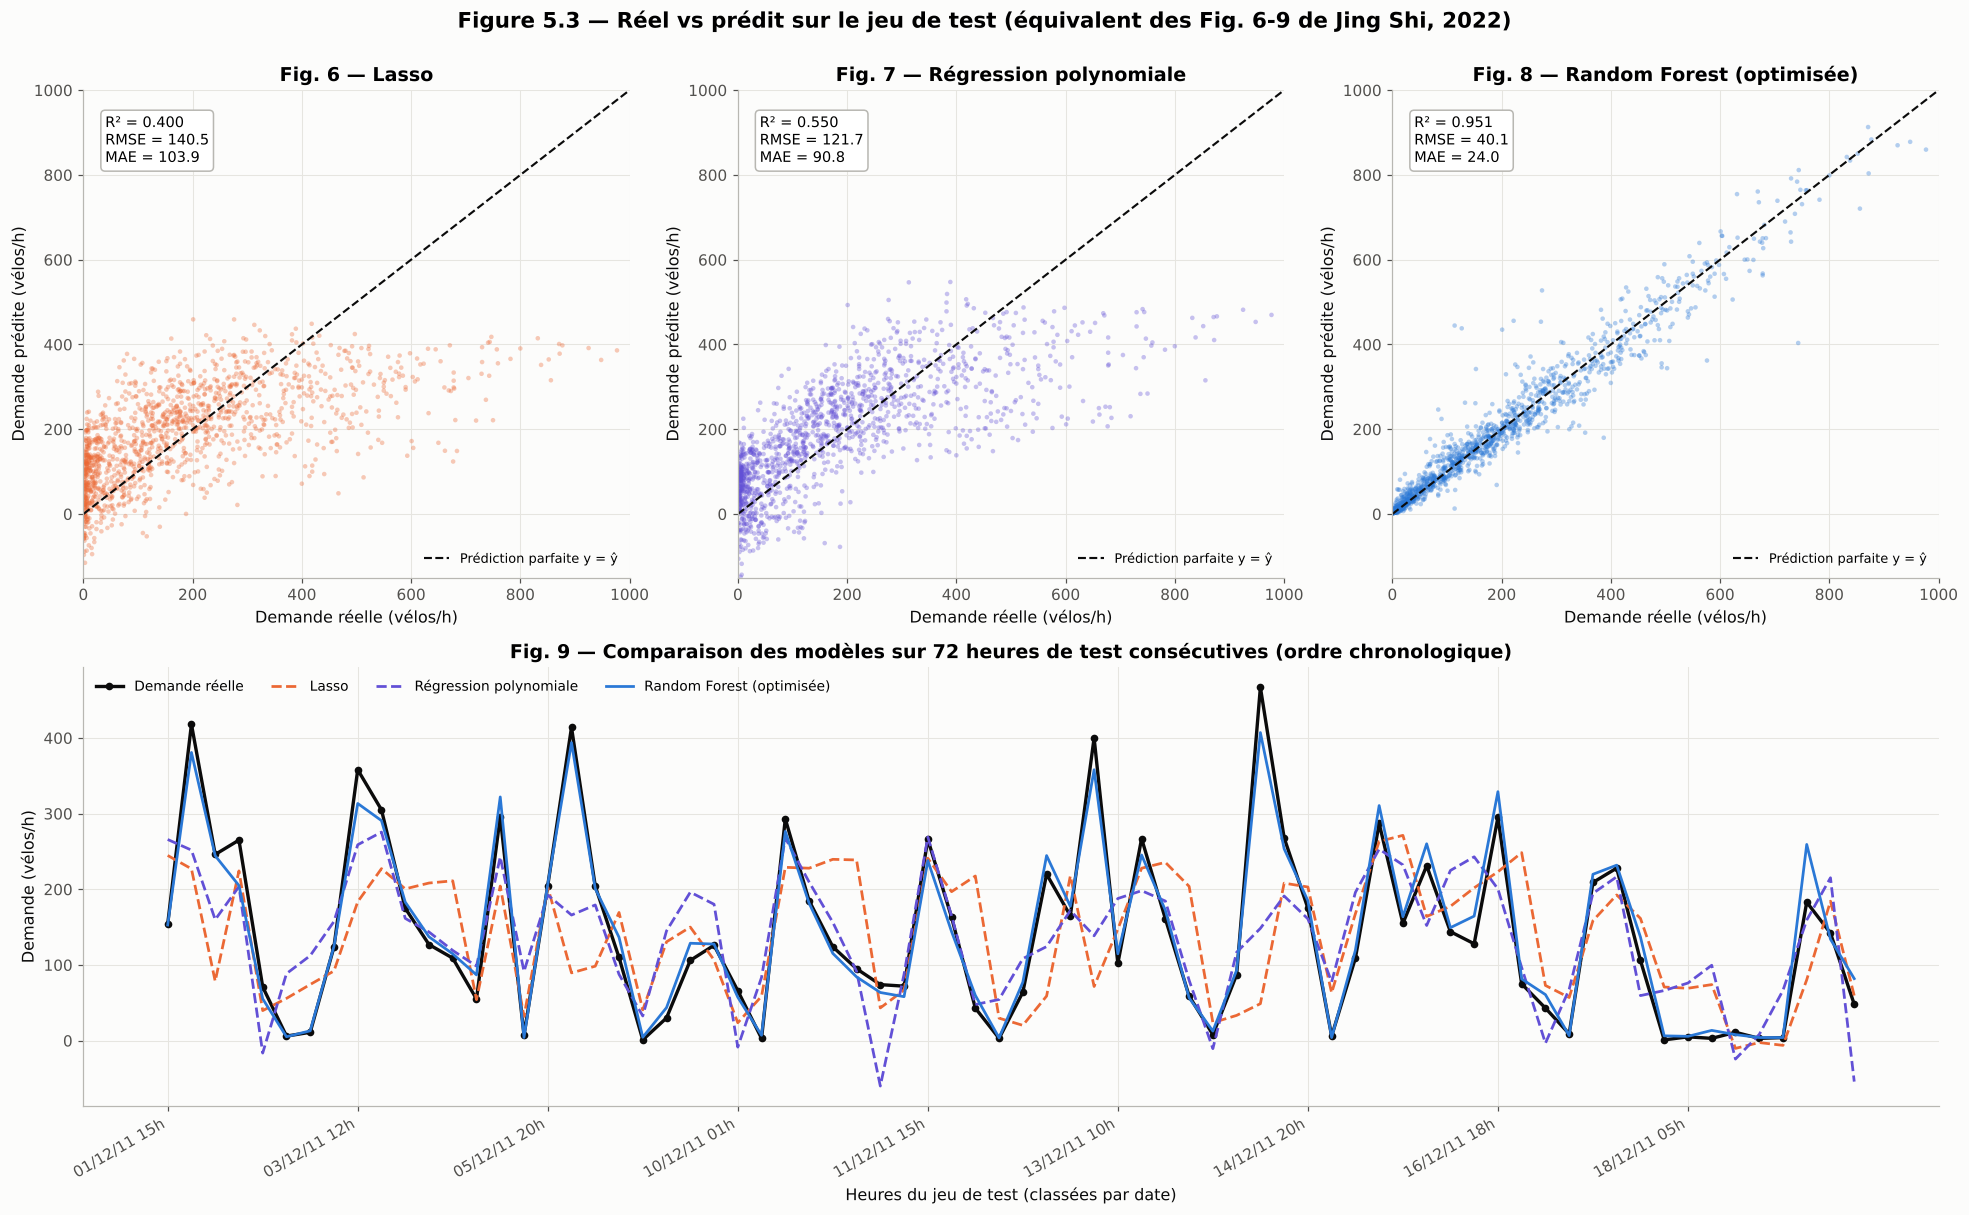

In [35]:
# ============================================================================
# 5.3 RÉEL VS PRÉDIT (FIG. 6 À 9 DE L'ARTICLE)
# ============================================================================
trio = [("Lasso (α = 0,5)", "Fig. 6 — Lasso", COULEURS["orange"]),
        ("Polynomiale (degré 2)", "Fig. 7 — Régression polynomiale", COULEURS["violet"]),
        ("Random Forest", "Fig. 8 — Random Forest (optimisée)", COULEURS["bleu"])]
dates_te = dates.loc[Xte.index]
ordre_t = np.argsort(dates_te.values)

fig = plt.figure(figsize=(18, 11))
gsp = fig.add_gridspec(2, 3, height_ratios=[1, 0.9])
for k, (cle, titre, c) in enumerate(trio):
    ax = fig.add_subplot(gsp[0, k])
    p = pred_test[cle]
    ax.scatter(yte, p, s=9, alpha=0.35, color=c, edgecolor="none")
    ax.plot([0, 1000], [0, 1000], color=COULEURS["encre"], lw=1.4, ls="--", label="Prédiction parfaite y = ŷ")
    ax.set_xlim(0, 1000)
    ax.set_ylim(-150, 1000)
    ax.set_title(titre)
    ax.set_xlabel("Demande réelle (vélos/h)")
    ax.set_ylabel("Demande prédite (vélos/h)")
    ax.text(0.04, 0.95, f"R² = {r2_score(yte, p):.3f}\nRMSE = {np.sqrt(mean_squared_error(yte, p)):.1f}\n"
                        f"MAE = {mean_absolute_error(yte, p):.1f}",
            transform=ax.transAxes, va="top", fontsize=9.5, bbox=dict(boxstyle="round", fc="white", ec=COULEURS["gris"]))
    ax.legend(loc="lower right", fontsize=8.5)

ax = fig.add_subplot(gsp[1, :])
fen = ordre_t[600:672]
xs_ = np.arange(len(fen))
ax.plot(xs_, yte.values[fen], color=COULEURS["encre"], lw=2.2, marker="o", ms=4, label="Demande réelle")
for cle, titre, c in trio:
    ax.plot(xs_, pred_test[cle][fen], color=c, lw=1.8, ls="--" if "Random" not in cle else "-",
            marker=None, label=titre.split("— ")[1])
etiq = [dates_te.values[i] for i in fen]
pas = 8
ax.set_xticks(xs_[::pas], [pd.Timestamp(e).strftime("%d/%m/%y %Hh") for e in etiq[::pas]], rotation=30, ha="right")
ax.set_title("Fig. 9 — Comparaison des modèles sur 72 heures de test consécutives (ordre chronologique)")
ax.set_xlabel("Heures du jeu de test (classées par date)")
ax.set_ylabel("Demande (vélos/h)")
ax.legend(ncol=4, loc="upper left", fontsize=9)
fig.suptitle("Figure 5.3 — Réel vs prédit sur le jeu de test (équivalent des Fig. 6-9 de Jing Shi, 2022)",
             fontweight="bold", fontsize=14, y=1.0)
plt.tight_layout()
sauver_figure(fig, "fig_5_3_reel_vs_predit")
plt.show()

**Finding (Constats chiffrés)**
* **Fig. 6 (Lasso) :** $R^2$ = 0,400, RMSE = 140,5. Le nuage est « écrasé » : les prédictions plafonnent vers 400 vélos/h alors que la demande réelle monte jusqu'à près de 1 000, et de nombreuses prédictions sont négatives.
* **Fig. 7 (polynomiale) :** $R^2$ = 0,550, RMSE = 121,7. Meilleure que le Lasso, mais avec le même plafonnement et encore des prédictions négatives.
* **Fig. 8 (Random Forest) :** $R^2$ = 0,951, RMSE = 40,1, MAE = 24,0. Les points s'alignent sur la diagonale sur toute la plage de demande.
* **Fig. 9 :** sur 72 heures de test consécutives, la forêt suit fidèlement chaque pic (≈ 400 à 470 vélos/h) et chaque creux nocturne, là où le Lasso et la polynomiale lissent les pics et inventent une demande la nuit.

**Insights (Interprétation métier et lien avec l'article)**
* Ces figures reproduisent la logique des Fig. 6 à 9 de l'article, qui concluent elles aussi à un meilleur ajustement de la forêt aléatoire.
* Le plafonnement des modèles linéaires est la pire erreur possible pour un gestionnaire de flotte : ils **sous-estiment précisément les heures de pointe**, où la rupture coûte le plus cher, et **sur-estiment la nuit**, où le sur-stock est inutile.
* Les prédictions négatives des modèles linéaires obligent à tronquer les commandes à zéro ($q \ge 0$, Étape 4.4), une correction ad hoc dont les arbres n'ont pas besoin puisqu'ils prédisent des moyennes de demandes observées.

## 5.4 Reproduction du Tableau 9 : coûts d'inventaire sur 10 sous-périodes

**Pourquoi ?** Le Tableau 9 de l'article découpe l'échantillon d'évaluation en 10 sous-périodes et compare, pour chacune, le **coût total d'inventaire** des stratégies Two-Step (LR, LA, RF) et One-Step FBNV (LR+FB, LA+FB, RF+FB). Un gain moyen pourrait cacher des périodes où la méthode perd ; le découpage permet de vérifier que la supériorité du FBNV est **systématique**.

On classe les 1 361 heures de test par ordre chronologique et on les découpe en 10 sous-périodes consécutives de 136 ou 137 heures. On ajoute le Gradient Boosting (GB, GB+FB) aux trois familles de l'article. Pour chaque période :

$$\text{Coût}_{p} = \sum_{i \in p} \Big[b\,(d_i - q_i)^+ + h\,(q_i - d_i)^+\Big], \quad b = 10,\; h = 4$$

,Dates couvertes,Heures,LR,LR+FB,LA,LA+FB,GB,GB+FB,RF,RF+FB
Période,,,,,,,,,,
1,01/01/11 → 10/03/11,137,"51,009","47,070","51,315","48,227","12,507","10,001","15,573","10,058"
2,10/03/11 → 01/06/11,136,"64,944","61,121","65,256","62,238","17,995","18,641","22,003","18,303"
3,01/06/11 → 07/08/11,136,"80,833","73,361","80,901","75,962","18,359","15,123","19,905","17,804"
4,08/08/11 → 15/10/11,136,"84,254","78,765","84,476","83,893","20,861","20,187","22,893","23,718"
5,15/10/11 → 04/01/12,136,"76,258","71,236","76,259","72,219","16,338","13,120","16,937","14,601"
6,05/01/12 → 13/03/12,136,"84,542","74,543","84,635","70,681","18,989","14,689","23,217","19,225"
7,13/03/12 → 03/06/12,136,"145,198","147,722","145,310","158,891","28,477","26,633","28,639","24,257"
8,03/06/12 → 07/08/12,136,"124,678","118,334","124,716","120,121","25,158","23,392","24,860","25,881"
9,09/08/12 → 14/10/12,136,"152,260","153,737","152,444","167,447","30,696","29,305","31,626","31,293"


Coût moyen par heure : LR = 718.03 | LR+FB = 686.23 | LA = 719.02 | LA+FB = 715.59 | GB = 154.42 | GB+FB = 142.44 | RF = 169.53 | RF+FB = 154.18


Famille,Coût total Two-Step,Coût total One-Step FBNV,Réduction de coût,Périodes gagnées par le FBNV (sur 10),Gain minimal sur une période,Gain maximal sur une période
Linear Regression,"977,245","933,957",+4.43%,8,-1.7%,+11.8%
Lasso,"978,581","973,919",+0.48%,7,-9.8%,+16.5%
Gradient Boosting,"210,160","193,855",+7.76%,8,-9.6%,+22.6%
Random Forest,"230,734","209,845",+9.05%,8,-4.1%,+35.4%


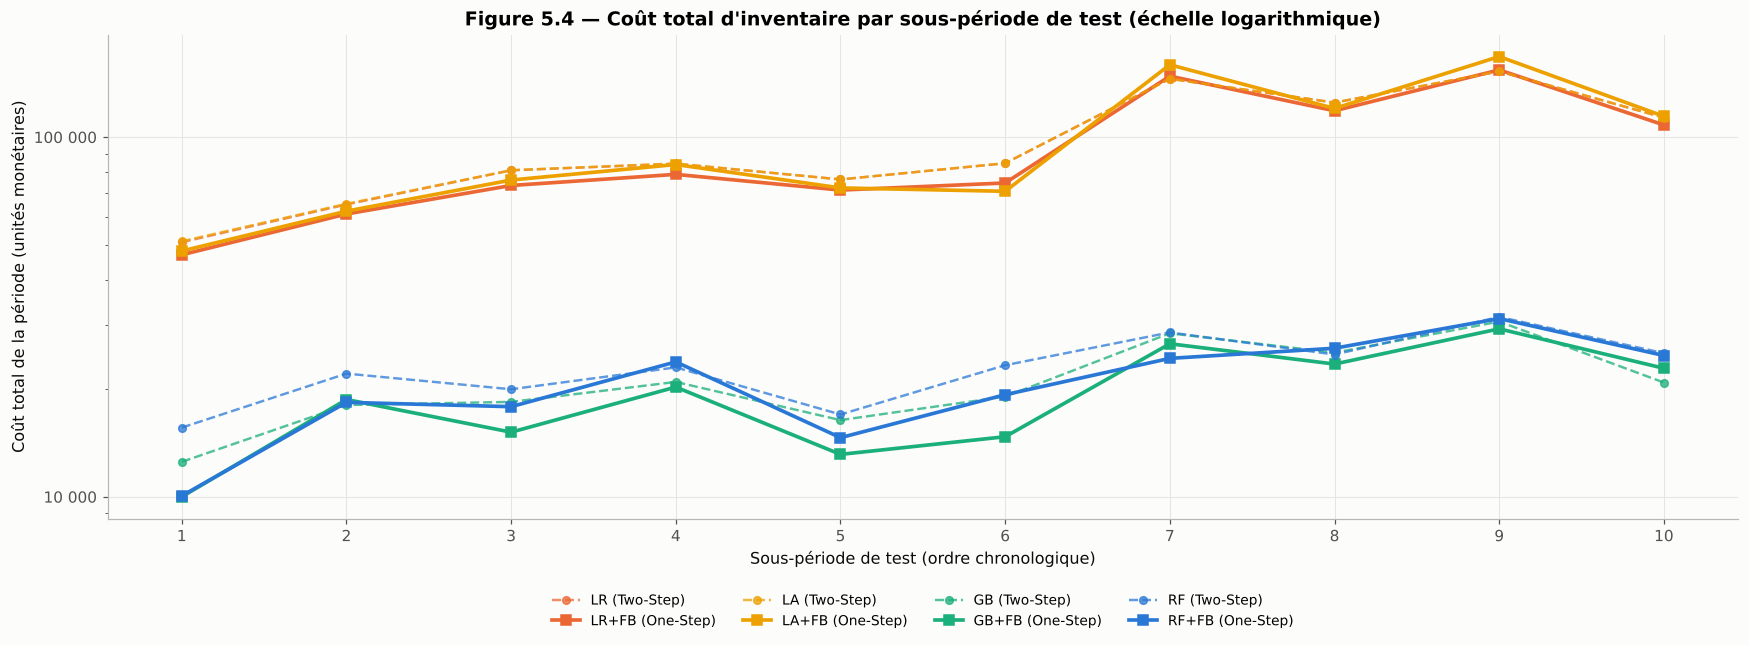

In [36]:
# ============================================================================
# 5.4 TABLEAU 9 (10 SOUS-PÉRIODES CHRONOLOGIQUES)
# ============================================================================
periodes = np.array_split(ordre_t, 10)
colonnes9 = [("LR", q_two["LR"]), ("LR+FB", q_one["LR"]), ("LA", q_two["LA"]), ("LA+FB", q_one["LA"]),
             ("GB", q_two["GB"]), ("GB+FB", q_one["GB"]), ("RF", q_two["RF"]), ("RF+FB", q_one["RF"])]
lignes9 = []
for k, idx in enumerate(periodes, 1):
    ligne = {"Période": k,
             "Dates couvertes": f"{pd.Timestamp(dates_te.values[idx[0]]).strftime('%d/%m/%y')} → "
                                f"{pd.Timestamp(dates_te.values[idx[-1]]).strftime('%d/%m/%y')}",
             "Heures": len(idx)}
    for nom, q in colonnes9:
        ligne[nom] = cout_newsvendor(yte.values[idx], q[idx]).sum()
    lignes9.append(ligne)
tab9 = pd.DataFrame(lignes9).set_index("Période")
couts = [n for n, _ in colonnes9]
tab9.loc["Total"] = ["", int(tab9["Heures"].sum())] + tab9[couts].sum().tolist()
tab9.loc["Coût moyen / heure"] = ["", ""] + (tab9.loc["Total", couts].astype(float) / len(yte)).tolist()
tab9[couts] = tab9[couts].astype(float)

def style9(s):
    s = s.highlight_min(subset=pd.IndexSlice[list(range(1, 11)), couts], axis=1,
                        props="background-color: #cde2fb; font-weight: bold;")
    s = s.format("{:.2f}", subset=pd.IndexSlice[["Coût moyen / heure"], couts])
    return s.set_properties(subset=pd.IndexSlice[["Total", "Coût moyen / heure"], :],
                            **{"font-weight": "bold", "border-top": "2px solid #52514e"})

afficher_tableau(tab9, "Tableau 9 (reproduction) — Coût total d'inventaire par sous-période (Two-Step vs One-Step FBNV)",
                 formats={c: "{:,.0f}" for c in couts}, post=style9)
# Ligne de coût moyen avec 2 décimales
print("Coût moyen par heure : " + " | ".join(f"{c} = {tab9.loc['Coût moyen / heure', c]:.2f}" for c in couts))

bilan = []
for m in ["LR", "LA", "GB", "RF"]:
    two, one = tab9.loc[list(range(1, 11)), m].astype(float), tab9.loc[list(range(1, 11)), f"{m}+FB"].astype(float)
    bilan.append({"Famille": noms_longs[m], "Coût total Two-Step": two.sum(), "Coût total One-Step FBNV": one.sum(),
                  "Réduction de coût": 1 - one.sum() / two.sum(),
                  "Périodes gagnées par le FBNV (sur 10)": int((one < two).sum()),
                  "Gain minimal sur une période": (1 - one / two).min(),
                  "Gain maximal sur une période": (1 - one / two).max()})
tab_bilan9 = pd.DataFrame(bilan)
afficher_tableau(tab_bilan9, "Tableau 9b — Bilan Two-Step vs One-Step FBNV par famille de modèles",
                 formats={"Coût total Two-Step": "{:,.0f}", "Coût total One-Step FBNV": "{:,.0f}",
                          "Réduction de coût": "{:+.2%}", "Gain minimal sur une période": "{:+.1%}",
                          "Gain maximal sur une période": "{:+.1%}"}, index=False)

fig, ax = plt.subplots(figsize=(16, 6))
coul9 = {"LR": COULEURS["orange"], "LA": COULEURS["jaune"], "GB": COULEURS["vert_eau"], "RF": COULEURS["bleu"]}
per = np.arange(1, 11)
for m, c in coul9.items():
    ax.plot(per, tab9.loc[list(range(1, 11)), m].astype(float), color=c, ls="--", lw=1.6, marker="o", ms=5,
            alpha=0.75, label=f"{m} (Two-Step)")
    ax.plot(per, tab9.loc[list(range(1, 11)), f"{m}+FB"].astype(float), color=c, lw=2.4, marker="s", ms=6,
            label=f"{m}+FB (One-Step)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " ")))
ax.set_xticks(per)
ax.set_title("Figure 5.4 — Coût total d'inventaire par sous-période de test (échelle logarithmique)")
ax.set_xlabel("Sous-période de test (ordre chronologique)")
ax.set_ylabel("Coût total de la période (unités monétaires)")
ax.legend(ncol=4, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.13))
plt.tight_layout()
sauver_figure(fig, "fig_5_4_tableau9_periodes")
plt.show()

**Finding (Constats chiffrés)**
* **Coût total sur les 1 361 heures de test** (et coût moyen par heure) :

| | LR | LR+FB | LA | LA+FB | GB | GB+FB | RF | RF+FB |
|---|---|---|---|---|---|---|---|---|
| Total | 977 245 | **933 957** | 978 581 | **973 919** | 210 160 | **193 855** | 230 734 | **209 845** |
| Par heure | 718,03 | **686,23** | 719,02 | **715,59** | 154,42 | **142,44** | 169,53 | **154,18** |
| Réduction | | **-4,43 %** | | **-0,48 %** | | **-7,76 %** | | **-9,05 %** |

* **Le coût minimal est atteint par GB+FB** (142,44 par heure), devant RF+FB (154,18) et le meilleur Two-Step (GB, 154,42).
* **Périodes gagnées par le One-Step :** **8 sur 10** pour LR, GB et RF, **7 sur 10** pour le Lasso. Les gains par période atteignent **+35,4 %** (RF, période 1) et **+22,6 %** (GB, période 6). Les pertes restent limitées : au pire -4,1 % (RF), -9,6 % (GB, période 10) et -9,8 % (Lasso, période 9).
* Les coûts sont nettement plus élevés à partir de la période 7 (printemps 2012) que sur 2011, pour toutes les stratégies : la demande, donc l'incertitude absolue, a fortement augmenté.

**Insights (Interprétation métier et lien avec l'article)**
* Le **classement global du Tableau 9 de l'article est reproduit** : pour chaque famille de modèles, la version One-Step FBNV a un coût total inférieur à la version Two-Step, et le meilleur modèle de prévision combiné au FBNV donne le coût le plus bas.
* **Nuance honnête par rapport à l'article :** dans le Tableau 9 de Jing Shi, le FBNV gagne sur les 10 périodes pour les trois familles. Ici, il gagne 7 ou 8 périodes sur 10. Sur environ 136 heures par période, quelques pics mal anticipés suffisent à faire basculer une période. La conclusion doit donc être formulée en **espérance de coût** : le FBNV réduit le coût moyen, il ne garantit pas une victoire sur chaque fenêtre courte.
* La croissance de 2011 à 2012 rappelle qu'un modèle de stock doit être **ré-entraîné régulièrement** : en production, on ré-estimerait le quantile sur une fenêtre glissante récente plutôt que sur un historique figé.

## 5.5 Décision de commande $q^*$ : stock de sécurité dynamique et erreur selon l'heure

**Pourquoi ?** Les tableaux résument ; la figure de décision **montre** ce que fait chaque stratégie, heure par heure. On compare, pour le Gradient Boosting (meilleure famille au Tableau 9) :
* la **commande Two-Step** : prévision + marge **fixe** $z^*\sigma$, identique à 3 h du matin et à 17 h ;
* la **commande One-Step FBNV** : quantile conditionnel, dont la marge au-dessus de la prévision moyenne (zone colorée, le **stock de sécurité dynamique**) s'adapte au contexte.

On analyse ensuite le stock de sécurité et le coût moyen par heure de la journée, et on les agrège par tranche horaire (nuit, pointe du matin, journée, pointe du soir, soirée).

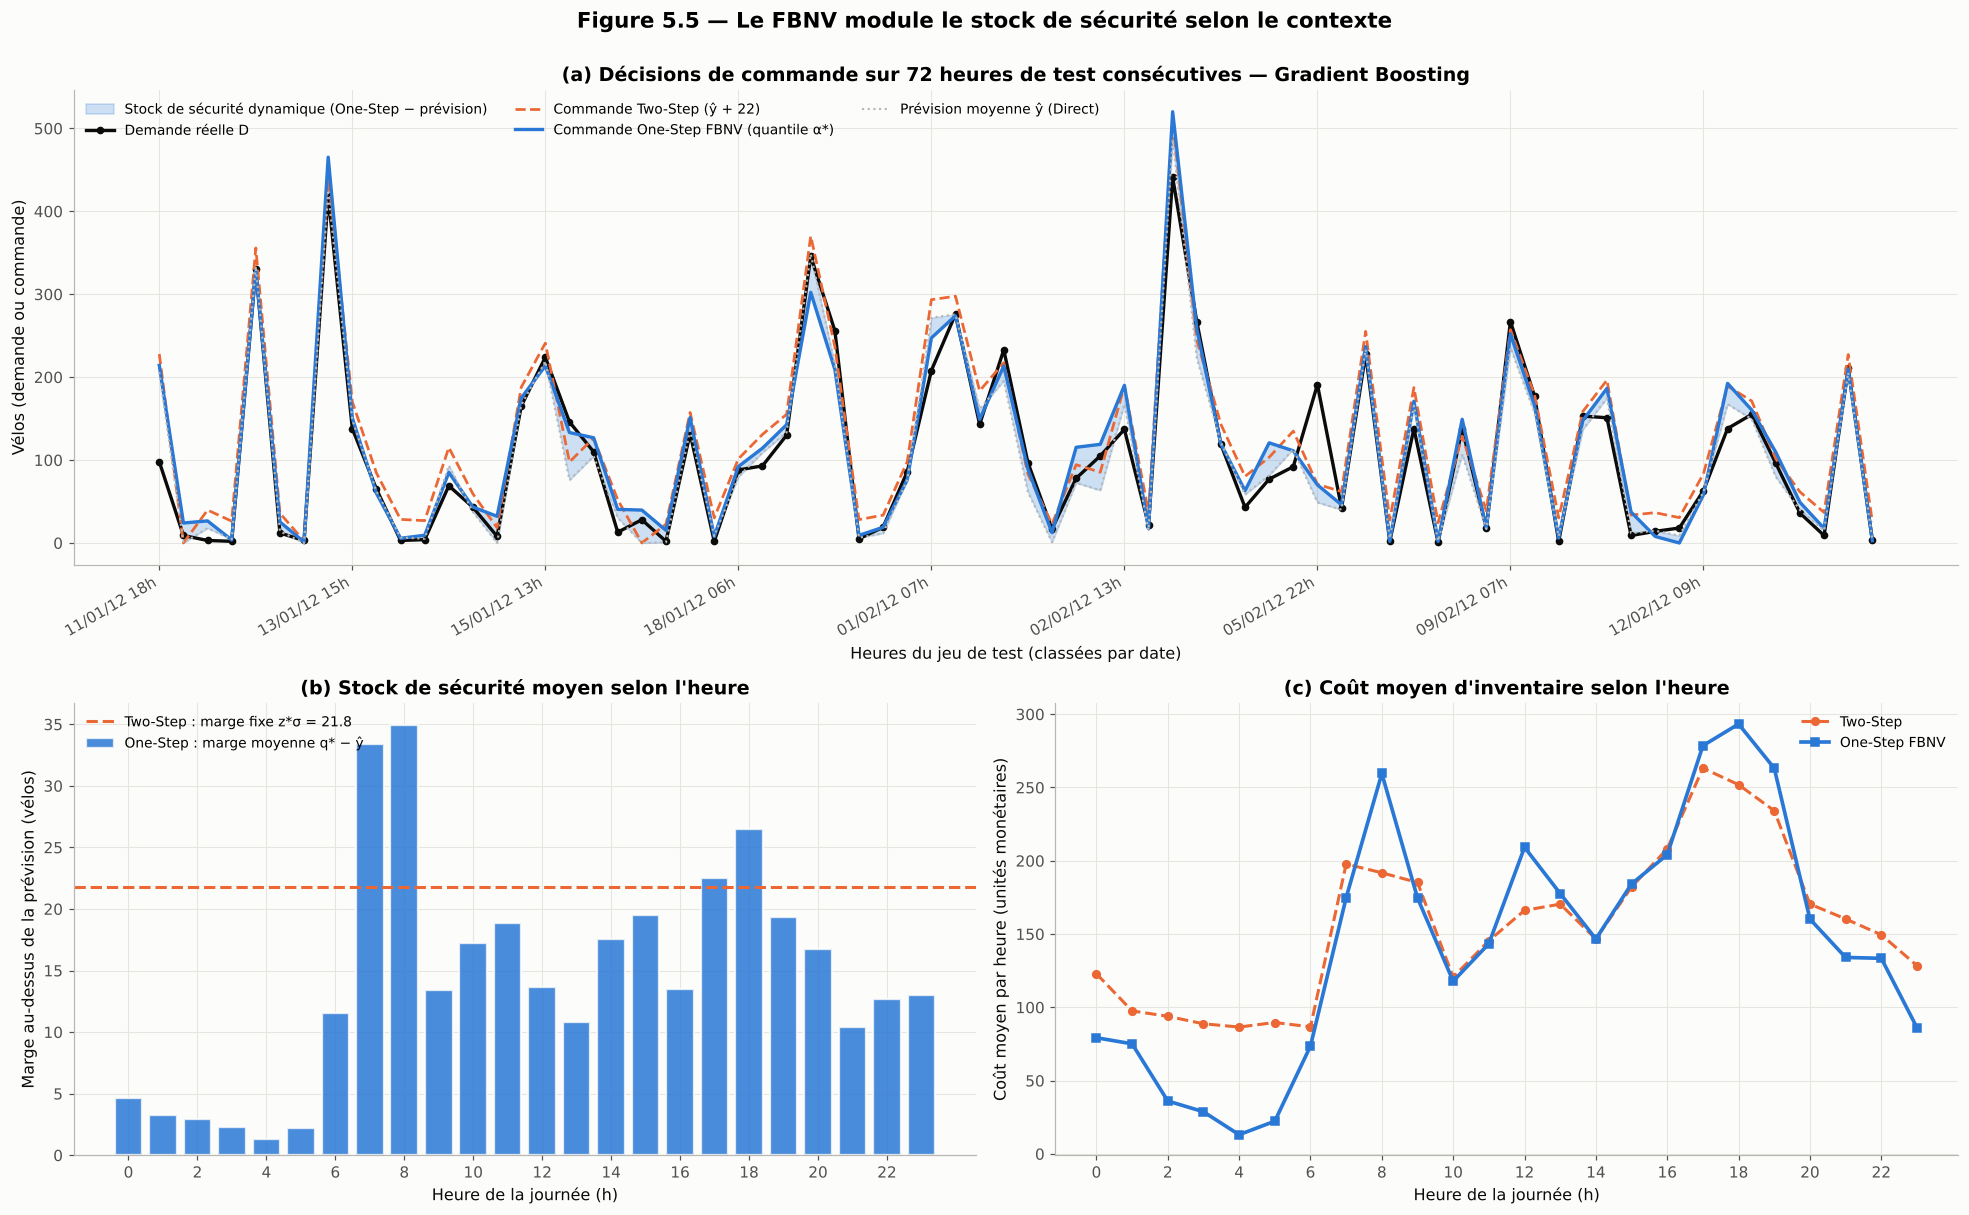

Tranche horaire,Heures de test,Demande moyenne,Marge Two-Step (vélos),Marge One-Step (vélos),Coût Two-Step / h,Coût One-Step / h,Taux de service Two-Step,Taux de service One-Step,Gain One-Step
Nuit (0-5 h),345,25.2,21.8,+2.7,95.8,42.1,95.9%,69.3%,+56.0%
Pointe matin (6-9 h),239,214.7,21.8,+22.3,165.7,167.9,77.0%,66.5%,-1.3%
Journée (10-15 h),340,237.4,21.8,+16.2,155.1,163.5,77.4%,67.1%,-5.4%
Pointe soir (16-19 h),208,385.2,21.8,+20.3,238.2,258.2,70.7%,65.4%,-8.4%
Soirée (20-23 h),229,163.8,21.8,+13.2,153.7,130.5,76.4%,69.4%,+15.1%


In [37]:
# ============================================================================
# 5.5 DÉCISION DE COMMANDE ET ANALYSE PAR HEURE
# ============================================================================
m_ref = "GB"
q2, q1, dh = q_two[m_ref], q_one[m_ref], np.maximum(d_hat[m_ref], 0)
hr_te = Xte["hr"].values

fig = plt.figure(figsize=(18, 11))
gsp = fig.add_gridspec(2, 2, height_ratios=[1.05, 1])
ax = fig.add_subplot(gsp[0, :])
fen = ordre_t[700:772]
x_ = np.arange(len(fen))
ax.fill_between(x_, dh[fen], q1[fen], color=COULEURS["bleu"], alpha=0.22,
                label="Stock de sécurité dynamique (One-Step − prévision)")
ax.plot(x_, yte.values[fen], color=COULEURS["encre"], lw=2.2, marker="o", ms=4, label="Demande réelle D")
ax.plot(x_, q2[fen], color=COULEURS["orange"], lw=1.8, ls="--", label=f"Commande Two-Step (ŷ + {Z_STAR * sigma_oof[m_ref]:.0f})")
ax.plot(x_, q1[fen], color=COULEURS["bleu"], lw=2.2, label="Commande One-Step FBNV (quantile α*)")
ax.plot(x_, dh[fen], color=COULEURS["gris"], lw=1.4, ls=":", label="Prévision moyenne ŷ (Direct)")
etiq = [dates_te.values[i] for i in fen]
ax.set_xticks(x_[::8], [pd.Timestamp(e).strftime("%d/%m/%y %Hh") for e in etiq[::8]], rotation=30, ha="right")
ax.set_title(f"(a) Décisions de commande sur 72 heures de test consécutives — Gradient Boosting")
ax.set_xlabel("Heures du jeu de test (classées par date)")
ax.set_ylabel("Vélos (demande ou commande)")
ax.legend(ncol=3, fontsize=9, loc="upper left")

ax = fig.add_subplot(gsp[1, 0])
ss_h = pd.Series(q1 - dh).groupby(hr_te).mean()
ax.bar(ss_h.index, ss_h.values, color=COULEURS["bleu"], alpha=0.85, edgecolor=COULEURS["fond"], linewidth=1.5,
       label="One-Step : marge moyenne q* − ŷ")
ax.axhline(Z_STAR * sigma_oof[m_ref], color=COULEURS["orange"], lw=2, ls="--",
           label=f"Two-Step : marge fixe z*σ = {Z_STAR * sigma_oof[m_ref]:.1f}")
ax.set_title("(b) Stock de sécurité moyen selon l'heure")
ax.set_xlabel("Heure de la journée (h)")
ax.set_ylabel("Marge au-dessus de la prévision (vélos)")
ax.set_xticks(range(0, 24, 2))
ax.legend(fontsize=9, loc="upper left")

ax = fig.add_subplot(gsp[1, 1])
c2_h = pd.Series(cout_newsvendor(yte.values, q2)).groupby(hr_te).mean()
c1_h = pd.Series(cout_newsvendor(yte.values, q1)).groupby(hr_te).mean()
ax.plot(c2_h.index, c2_h.values, color=COULEURS["orange"], lw=2, ls="--", marker="o", ms=5, label="Two-Step")
ax.plot(c1_h.index, c1_h.values, color=COULEURS["bleu"], lw=2.4, marker="s", ms=5, label="One-Step FBNV")
ax.set_title("(c) Coût moyen d'inventaire selon l'heure")
ax.set_xlabel("Heure de la journée (h)")
ax.set_ylabel("Coût moyen par heure (unités monétaires)")
ax.set_xticks(range(0, 24, 2))
ax.legend(fontsize=9)
fig.suptitle("Figure 5.5 — Le FBNV module le stock de sécurité selon le contexte",
             fontweight="bold", fontsize=14, y=1.0)
plt.tight_layout()
sauver_figure(fig, "fig_5_5_decision_commande")
plt.show()

tranches = pd.cut(hr_te, bins=[-1, 5, 9, 15, 19, 23],
                  labels=["Nuit (0-5 h)", "Pointe matin (6-9 h)", "Journée (10-15 h)", "Pointe soir (16-19 h)", "Soirée (20-23 h)"])
lignes_t = []
for t_ in tranches.categories:
    msk = tranches == t_
    k2_, k1_ = kpi(yte.values[msk], q2[msk]), kpi(yte.values[msk], q1[msk])
    lignes_t.append({"Tranche horaire": t_, "Heures de test": int(msk.sum()),
                     "Demande moyenne": yte.values[msk].mean(),
                     "Marge Two-Step (vélos)": Z_STAR * sigma_oof[m_ref], "Marge One-Step (vélos)": (q1 - dh)[msk].mean(),
                     "Coût Two-Step / h": k2_["Coût moyen par heure"], "Coût One-Step / h": k1_["Coût moyen par heure"],
                     "Taux de service Two-Step": k2_["Taux de service"], "Taux de service One-Step": k1_["Taux de service"]})
tab_t = pd.DataFrame(lignes_t)
tab_t["Gain One-Step"] = 1 - tab_t["Coût One-Step / h"] / tab_t["Coût Two-Step / h"]
afficher_tableau(tab_t, f"Tableau 5.5 — Décisions Two-Step vs One-Step par tranche horaire (Gradient Boosting, test)",
                 formats={"Demande moyenne": "{:.1f}", "Marge Two-Step (vélos)": "{:.1f}", "Marge One-Step (vélos)": "{:+.1f}",
                          "Coût Two-Step / h": "{:.1f}", "Coût One-Step / h": "{:.1f}",
                          "Taux de service Two-Step": "{:.1%}", "Taux de service One-Step": "{:.1%}",
                          "Gain One-Step": "{:+.1%}"},
                 post=lambda s: s.background_gradient(subset=["Gain One-Step"], cmap="RdYlGn", vmin=-0.3, vmax=0.3),
                 index=False)

**Finding (Constats chiffrés)**
* **(a)** Sur 72 heures de test, la commande Two-Step suit la prévision avec un décalage **constant** de 22 vélos. La commande One-Step colle presque à la prévision la nuit et s'en écarte fortement avant les pics.
* **(b)** La marge moyenne One-Step varie de **1 à 5 vélos la nuit (0-5 h)** à **33-35 vélos à 7-8 h** et **26 vélos à 18 h**, contre une marge Two-Step fixe de **21,8 vélos** à toute heure.
* **(c) et Tableau 5.5 :**

| Tranche | Demande moyenne | Coût Two-Step / h | Coût One-Step / h | Variation |
|---|---|---|---|---|
| Nuit (0-5 h) | 25 | 95,8 | **42,1** | **-56,0 %** |
| Pointe du matin (6-9 h) | 215 | 165,7 | 167,9 | +1,3 % |
| Journée (10-15 h) | 237 | 155,1 | 163,5 | +5,4 % |
| Pointe du soir (16-19 h) | 385 | 238,2 | 258,2 | +8,4 % |
| Soirée (20-23 h) | 164 | 153,7 | **130,5** | **-15,1 %** |

* Le Two-Step atteint un taux de service de **95,9 % la nuit** (largement au-dessus de la cible de 71,4 %) ; le One-Step se tient entre **65 % et 69 %** dans toutes les tranches.

**Insights (Interprétation métier et lien avec l'article)**
* La figure montre concrètement le « stock de sécurité dynamique » : le FBNV **retire des vélos la nuit** (où la marge fixe de 22 vélos est un pur gaspillage face à une demande de 25 vélos/h) et **en ajoute avant les pointes**. Le gain vient presque entièrement de la nuit et de la soirée (-56 % et -15 %).
* Aux heures de pointe, le One-Step coûte un peu plus que le Two-Step (+1 à +8 %), car le boosting quantile est légèrement **sous-calibré** à ces heures (taux de service ≈ 65-67 % contre 71,4 % visés). C'est la piste d'amélioration principale : un recalibrage du quantile par tranche horaire (*conformal quantile regression*), ou un α légèrement plus élevé aux heures de pointe.
* Pour l'exploitation, cette analyse a une traduction directe : les équipes de rééquilibrage (camions qui déplacent les vélos) doivent concentrer leurs moyens sur les **fenêtres 6-9 h et 16-19 h**, et peuvent fortement réduire le nombre de vélos immobilisés la nuit.

## 5.6 Export Excel pour le rendu Moodle (`donnees_propres_GP27_FBNV.xlsx`)

**Pourquoi ?** Le cahier des charges du TP demande de rendre « rapport + code + base de données (excel) + slides ». On exporte un classeur unique, documenté, qui permet au correcteur de vérifier chaque chiffre sans relancer Python :

| Onglet | Contenu |
|---|---|
| `Lisez-moi` | Description du classeur, paramètres et sources |
| `Donnees_propres` | Les 10 886 heures nettoyées (`bike_new` + `datetime` + appartenance train/test) |
| `Decisions_test` | Pour chaque heure de test : demande, prévisions, commandes Direct / Two-Step / One-Step et coûts |
| `CV_benchmark` | Tableau 3.2 |
| `Tableau_8` | Métriques de test (Tableau 8) |
| `Tableau_9` | Coûts par sous-période (Tableau 9) |
| `Strategies` | Tableau 4.4 |
| `Sensibilite` | Tableau 4.5 |
| `Lasso` | Coefficients et sélection (Tableau 2.5) |
| `Importance` | Tableau 5.2 |

In [38]:
# ============================================================================
# 5.6 EXPORT EXCEL
# ============================================================================
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

FICHIER_XLSX = "donnees_propres_GP27_FBNV.xlsx"

donnees = bike_new.copy()
donnees.insert(0, "datetime", dates)
donnees["jeu"] = np.where(donnees.index.isin(Xte.index), "test", "train")

decisions = pd.DataFrame({"datetime": dates_te.values, "cnt_reel": yte.values}, index=Xte.index)
for c in variables_retenues:
    decisions[c] = Xte[c].values
for m in ["LR", "LA", "GB", "RF"]:
    decisions[f"{m}_prevision"] = d_hat[m]
    decisions[f"{m}_q_direct"] = q_direct[m]
    decisions[f"{m}_q_two_step"] = q_two[m]
    decisions[f"{m}_q_one_step_FB"] = q_one[m]
    decisions[f"{m}_cout_two_step"] = cout_newsvendor(yte.values, q_two[m])
    decisions[f"{m}_cout_one_step_FB"] = cout_newsvendor(yte.values, q_one[m])
decisions = decisions.sort_values("datetime")
decisions["periode_tableau9"] = 0
for k, idx in enumerate(periodes, 1):
    decisions.loc[Xte.index[idx], "periode_tableau9"] = k

lisez_moi = pd.DataFrame({"Rubrique": [
    "Projet", "Article reproduit", "Données", "Nettoyage", "Partition", "Variables retenues (Lasso)",
    "Paramètres newsvendor", "Stratégie Two-Step", "Stratégie One-Step FBNV", "Coût", "Généré le"],
    "Contenu": [
    "TP GP27 (UTT), Feature-Based Newsvendor appliqué au Bike Sharing Demand",
    "Jing Shi (2022), Computers & Industrial Engineering 173, 108709",
    f"Kaggle Bike Sharing Demand, train.csv, {len(bike_new)} heures, MD5 {md5}",
    "Aucune ligne supprimée ; casual et registered retirées (fuite de données) ; yr, mnth, hr, weekday extraites",
    "87,5 % train (9 525 h) / 12,5 % test (1 361 h), random_state = 42",
    ", ".join(variables_retenues),
    f"b = {B_RUPTURE}, h = {H_STOCK}, alpha* = {ALPHA_STAR:.4f}, z* = {Z_STAR:.4f}",
    "q = prévision + z* x sigma des résidus out-of-fold",
    "q = quantile conditionnel d'ordre alpha* (régression quantile / quantile des arbres)",
    "C = b (D - q)+ + h (q - D)+",
    pd.Timestamp.now().strftime("%d/%m/%Y %H:%M")]})

onglets = {
    "Lisez-moi": lisez_moi, "Donnees_propres": donnees, "Decisions_test": decisions.round({c: 3 for c in decisions.columns if c != "datetime"}),
    "CV_benchmark": tab_cv.round(4), "Tableau_8": tab8.round(4), "Tableau_9": tab9,
    "Strategies": tab_strat.round(4), "Sensibilite": tab_sens.round(4),
    "Lasso": coef_df.round(4), "Importance": imp.round(4),
}
with pd.ExcelWriter(FICHIER_XLSX, engine="openpyxl") as writer:
    for nom_onglet, tab in onglets.items():
        avec_index = nom_onglet in ("Tableau_9", "Importance")
        tab.to_excel(writer, sheet_name=nom_onglet, index=avec_index)
        ws = writer.sheets[nom_onglet]
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="2A78D6")
            cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        ws.freeze_panes = "B2"
        for j, col in enumerate(ws.iter_cols(min_row=1, max_row=min(ws.max_row, 200)), 1):
            largeur = max(len(str(c.value)) if c.value is not None else 0 for c in col)
            ws.column_dimensions[get_column_letter(j)].width = min(max(10, largeur + 2), 60)

recap_xlsx = pd.DataFrame({"Onglet": list(onglets), "Lignes": [len(t) for t in onglets.values()],
                           "Colonnes": [t.shape[1] + (1 if n in ("Tableau_9", "Importance") else 0)
                                        for n, t in onglets.items()]})
afficher_tableau(recap_xlsx, f"Tableau 5.6 — Contenu du classeur {FICHIER_XLSX} "
                             f"({os.path.getsize(FICHIER_XLSX) / 1024:,.0f} Ko)", index=False)

Onglet,Lignes,Colonnes
Lisez-moi,11,2
Donnees_propres,10886,15
Decisions_test,1361,37
CV_benchmark,9,9
Tableau_8,9,5
Tableau_9,12,11
Strategies,13,9
Sensibilite,18,13
Lasso,12,6
Importance,10,7


**Finding (Constats chiffrés)**
* Le classeur `donnees_propres_GP27_FBNV.xlsx` contient **10 onglets**, dont les **10 886 heures nettoyées** (15 colonnes, avec l'appartenance train/test) et les **1 361 décisions de test** (37 colonnes : variables, prévisions, commandes et coûts des 4 modèles dans chaque stratégie, numéro de sous-période du Tableau 9).
* Chaque onglet a un en-tête mis en forme, des volets figés et des colonnes dimensionnées automatiquement.

**Insights (Interprétation métier et lien avec l'article)**
* Le correcteur peut **recalculer chaque chiffre du Tableau 9 dans Excel** (somme des colonnes `*_cout_*` par `periode_tableau9`), sans exécuter le notebook. C'est le livrable « base de données (excel) » demandé dans le cahier des charges du TP.
* L'onglet `Lisez-moi` documente les paramètres ($b$, $h$, $\alpha^*$, $z^*$), la partition et l'empreinte MD5 du fichier source : le classeur est **auto-suffisant et traçable**.

## 5.7 Conclusion générale

**Pourquoi ?** On rassemble dans un tableau unique les résultats qui répondent à la question du TP : la méthode de Jing Shi (2022) se transpose-t-elle à la demande de vélos en libre-service, et que rapporte-t-elle ?

In [39]:
# ============================================================================
# 5.7 SYNTHÈSE FINALE
# ============================================================================
cm = tab9.loc["Coût moyen / heure", couts].astype(float)
synthese = pd.DataFrame([
    ["Étape 1", "Qualité des données", "0 manquant, 0 doublon, fuite casual/registered supprimée", "10 886 heures conservées"],
    ["Étape 2", "Sélection Lasso (α = 0,5)", f"{len(variables_retenues)} variables sur 12",
     "season et workingday éliminées"],
    ["Étape 3", "Meilleur modèle en CV", f"{tab_cv.iloc[0]['Modèle']} : RMSE = {tab_cv.iloc[0]['RMSE moyen']:.2f}",
     f"R² = {tab_cv.iloc[0]['R² moyen (validation)']:.3f}"],
    ["Étape 3", "Meilleur modèle linéaire en CV",
     f"RMSE = {tab_cv[tab_cv['Famille'] == 'Linéaire']['RMSE moyen'].min():.2f}",
     f"R² = {tab_cv[tab_cv['Famille'] == 'Linéaire']['R² moyen (validation)'].max():.3f}"],
    ["Étape 5", "Meilleur modèle sur le test (Tableau 8)", f"{tab8.iloc[0]['Modèle']} : RMSE = {tab8.iloc[0]['RMSE']:.2f}",
     f"R² = {tab8.iloc[0]['R²']:.3f}"],
    ["Étape 4", "Fractile critique", f"α* = {ALPHA_STAR:.4f}, z* = {Z_STAR:.4f}", "b = 10, h = 4"],
    ["Étape 5", "Coût minimal (Tableau 9)", f"{cm.idxmin()} : {cm.min():.2f} par heure",
     f"contre {cm[cm.idxmin().replace('+FB', '')]:.2f} en Two-Step"],
    ["Étape 5", "Périodes gagnées par le FBNV",
     " | ".join(f"{r['Famille']} : {r['Périodes gagnées par le FBNV (sur 10)']}/10" for _, r in tab_bilan9.iterrows()), ""],
    ["Étape 4", "Robustesse (sensibilité α de 0,10 à 0,95)",
     " | ".join(f"{m} : {v}/{len(alphas_sens)}" for m, v in nb_gagnant.items()), "valeurs de α où le FBNV gagne"],
], columns=["Étape", "Indicateur", "Résultat", "Complément"])
afficher_tableau(synthese, "Tableau 5.7 — Synthèse des résultats du pipeline FBNV", index=False)

Étape,Indicateur,Résultat,Complément
Étape 1,Qualité des données,"0 manquant, 0 doublon, fuite casual/registered supprimée",10 886 heures conservées
Étape 2,"Sélection Lasso (α = 0,5)",10 variables sur 12,season et workingday éliminées
Étape 3,Meilleur modèle en CV,Random Forest : RMSE = 42.59,R² = 0.945
Étape 3,Meilleur modèle linéaire en CV,RMSE = 141.89,R² = 0.386
Étape 5,Meilleur modèle sur le test (Tableau 8),Gradient Boosting (optimisé) : RMSE = 37.11,R² = 0.958
Étape 4,Fractile critique,"α* = 0.7143, z* = 0.5659","b = 10, h = 4"
Étape 5,Coût minimal (Tableau 9),GB+FB : 142.44 par heure,contre 154.42 en Two-Step
Étape 5,Périodes gagnées par le FBNV,Linear Regression : 8/10 | Lasso : 7/10 | Gradient Boosting : 8/10 | Random Forest : 8/10,
Étape 4,"Robustesse (sensibilité α de 0,10 à 0,95)",LR : 14/18 | GB : 12/18 | RF : 16/18,valeurs de α où le FBNV gagne


### Conclusion générale

**Ce que montre ce notebook**

1. **La donnée** (Étape 1) est saine mais complexe : demande asymétrique (asymétrie de 1,24), hétéroscédastique, bimodale en semaine. La seule correction nécessaire était la suppression de `casual` et `registered`, qui créaient une fuite de données.
2. **La sélection Lasso** (Étape 2) retient 10 variables sur 12 et élimine `season` et `workingday`, redondantes, exactement comme le §4.2 de l'article le prévoit.
3. **La prévision** (Étapes 3 et 5) : les ensembles d'arbres écrasent les modèles linéaires (RMSE de test de 37 à 40 contre 141, $R^2$ de 0,95 contre 0,40). La forêt aléatoire est le meilleur modèle par défaut, comme dans l'article ; le Gradient Boosting la dépasse une fois optimisé.
4. **La décision** (Étapes 4 et 5) : pour chacune des quatre familles de modèles, le **One-Step FBNV réduit le coût d'inventaire** par rapport au Two-Step : -4,4 % (LR), -0,5 % (Lasso), **-7,8 % (GB)** et **-9,1 % (RF)**. Le coût minimal (**142,44 par heure**, GB+FB) est obtenu en combinant le meilleur prévisionniste et l'approche intégrée.
5. **La robustesse** : le FBNV gagne pour 12 à 16 des 18 ratios de coûts testés selon le modèle, et le gain devient important dès que la rupture coûte nettement plus que le sur-stock (α ≥ 0,70 : +6,6 % à +17,1 % pour les arbres), ce qui correspond à la réalité d'un service de vélos.

**La thèse de Jing Shi (2022) est vérifiée sur un jeu de données totalement différent** : « the total inventory cost can be reduced to a certain extent by improving the accuracy of forecasting, combining forecasting with inventory, and changing the two-step strategy into one-step strategy ».

**Limites et pistes d'amélioration**
* Le FBNV gagne 7 à 8 sous-périodes sur 10, et non 10 sur 10 : le gain est un gain **en espérance**.
* Le boosting quantile est légèrement sous-calibré aux heures de pointe : une calibration conforme, ou des hyperparamètres ré-optimisés pour chaque α, réduiraient encore le coût.
* Le newsvendor étudié est mono-période et mono-station. Une extension naturelle serait le **rééquilibrage inter-stations** (allocation inter-sites), qui fait partie des thèmes proposés par le cahier des charges du TP.